In [38]:
import hashlib
import os
import re
import textwrap
import time
from itertools import combinations

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.utils import to_categorical

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, auc, classification_report,
                             confusion_matrix, roc_curve, silhouette_score)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
except ImportError:
    CATBOOST_AVAILABLE = False
    print("CatBoost not available. Skipping it.")

In [39]:
# Parameters
input_shape = (224, 224, 3)
num_classes = 4

# Define paths
dataset_dir = "/kaggle/input/datasets/blank1508/mendeley-lbc-cervical-cancer"  

print(f"Using dataset directory: {dataset_dir}")
print("Subfolders (classes):", os.listdir(dataset_dir))

classes = ['High squamous intra-epithelial lesion', 'Low squamous intra-epithelial lesion', 'Negative for Intraepithelial malignancy', 'Squamous cell carcinoma']
class_names = ['High squamous intra-epithelial lesion', 'Low squamous intra-epithelial lesion', 'Negative for Intraepithelial malignancy', 'Squamous cell carcinoma']

# Now define cropped_dirs using the actual class subfolder names
class_subdirs = os.listdir(dataset_dir)  # Should be the 4 class folders
cropped_dirs = {
    subdir: os.path.join(dataset_dir, subdir)
    for subdir in class_subdirs
}

Using dataset directory: /kaggle/input/datasets/blank1508/mendeley-lbc-cervical-cancer
Subfolders (classes): ['High squamous intra-epithelial lesion', 'Low squamous intra-epithelial lesion', 'Negative for Intraepithelial malignancy', 'Squamous cell carcinoma']


In [40]:
def load_images_from_directory(directory, target_size=(224, 224)):
    images, filenames = [], []
    for filename in sorted(os.listdir(directory)):
        img = cv2.imread(os.path.join(directory, filename))
        if img is not None:
            img = cv2.resize(img, target_size)
            images.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            filenames.append(filename)
    return np.array(images), filenames

cropped_images, cropped_labels, cropped_groups = {}, {}, {}

for cls, dir_path in cropped_dirs.items():

    images, filenames = load_images_from_directory(dir_path)

    cropped_images[cls] = images
    cropped_labels[cls] = np.full(len(images), cls)

    cropped_groups[cls] = np.array([
        re.match(r'(.+?)\s*\(\d+\)', fn).group(1)
        if re.match(r'(.+?)\s*\(\d+\)', fn)
        else os.path.splitext(fn)[0]
        for fn in filenames
    ])


X_cropped = np.concatenate(list(cropped_images.values()))
y_cropped = np.concatenate(list(cropped_labels.values()))
groups = np.concatenate(list(cropped_groups.values()))

label_to_index = {
    cls: idx for idx, cls in enumerate(cropped_dirs.keys())
}

y_cropped = np.array([
    label_to_index[label] for label in y_cropped
])

y_cropped = to_categorical(y_cropped, num_classes=4)

In [41]:
def group_split_per_class(y_int, groups, fractions=(0.80, 0.10, 0.10),
                          trials=1000, random_state=42):
    fractions = np.asarray(fractions, dtype=float)
    if len(fractions) != 3 or not np.isclose(fractions.sum(), 1.0):
        raise ValueError("fractions must contain three values that sum to 1.")

    rng = np.random.default_rng(random_state)
    unique_groups = np.unique(groups)
    classes_in_data = np.unique(y_int)

    group_counts = np.array([
        [np.sum((groups == group) & (y_int == cls)) for cls in classes_in_data]
        for group in unique_groups
    ])

    group_classes = np.argmax(group_counts, axis=1)

    for cls in classes_in_data:
        n_groups = np.sum(group_classes == cls)
        if n_groups < 3:
            raise ValueError(
                f"Class {cls} has only {n_groups} groups; at least 3 are "
                "needed for train/validation/test splitting."
            )

    targets = fractions * len(y_int)
    class_targets = fractions[:, None] * np.bincount(
        y_int, minlength=len(classes_in_data)
    )

    best_score = float("inf")
    best_assignment = None

    for _ in range(trials):
        assignment = np.full(len(unique_groups), -1, dtype=int)

        for cls in classes_in_data:
            idx = np.where(group_classes == cls)[0]
            idx = rng.permutation(idx)

            assignment[idx[:3]] = rng.permutation(3)

            assignment[idx[3:]] = rng.choice(
                3, size=len(idx) - 3, p=fractions
            )

        split_counts = np.array([
            group_counts[assignment == split].sum(axis=0)
            for split in range(3)
        ])
        split_sizes = split_counts.sum(axis=1)

        size_error = np.sum(((split_sizes - targets) / np.maximum(targets, 1)) ** 2)
        class_error = np.sum(
            ((split_counts - class_targets) /
             np.maximum(class_targets, 1)) ** 2
        )
        score = size_error + class_error

        if score < best_score:
            best_score = score
            best_assignment = assignment.copy()

    split_map = dict(zip(unique_groups, best_assignment))
    return np.array([split_map[group] for group in groups])


y_cropped_int = np.argmax(y_cropped, axis=1)

split_id = group_split_per_class(
    y_cropped_int,
    groups,
    fractions=(0.80, 0.10, 0.10),
    random_state=42
)

X_train, y_train = X_cropped[split_id == 0], y_cropped[split_id == 0]
X_val, y_val = X_cropped[split_id == 1], y_cropped[split_id == 1]
X_test, y_test = X_cropped[split_id == 2], y_cropped[split_id == 2]

groups_train = groups[split_id == 0]
groups_val = groups[split_id == 1]
groups_test = groups[split_id == 2]

# Leakage checks
assert not (set(groups_train) & set(groups_val))
assert not (set(groups_train) & set(groups_test))
assert not (set(groups_val) & set(groups_test))

for split_name, X, y, split_groups in [
    ("Train", X_train, y_train, groups_train),
    ("Validation", X_val, y_val, groups_val),
    ("Test", X_test, y_test, groups_test)
]:
    print(f"\\n{split_name}: {len(X)} images / {len(np.unique(split_groups))} groups")
    print(f"Percentage: {len(X) / len(X_cropped) * 100:.2f}%")
    print("Class distribution:", np.sum(y, axis=0).astype(int))

\nTrain: 739 images / 46 groups
Percentage: 76.82%
Class distribution: [127  65 499  48]
\nValidation: 109 images / 7 groups
Percentage: 11.33%
Class distribution: [17 21 56 15]
\nTest: 114 images / 8 groups
Percentage: 11.85%
Class distribution: [19 27 57 11]


In [42]:
y_train_classes = np.argmax(y_train, axis=1)
y_val_classes = np.argmax(y_val, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

print("Training:", len(X_train), len(y_train_classes))
print("Validation:", len(X_val), len(y_val_classes))
print("Testing:", len(X_test), len(y_test_classes))

assert len(X_val) == len(y_val_classes)
assert len(X_test) == len(y_test_classes)

Training: 739 739
Validation: 109 109
Testing: 114 114


In [43]:
g_train, g_val, g_test = (set(groups[split_id == k]) for k in range(3))
assert not (g_train & g_val), "DATA LEAK: groups shared between train and val"
assert not (g_train & g_test), "DATA LEAK: groups shared between train and test"
assert not (g_val & g_test), "DATA LEAK: groups shared between val and test"

def image_hashes(X):
    return {hashlib.md5(x.tobytes()).hexdigest() for x in X}

h_train, h_val, h_test = image_hashes(X_train), image_hashes(X_val), image_hashes(X_test)
assert not (h_train & h_val), "DATA LEAK: identical images shared between train and val"
assert not (h_train & h_test), "DATA LEAK: identical images shared between train and test"
assert not (h_val & h_test), "DATA LEAK: identical images shared between val and test"

print("No group or exact-duplicate overlap between train / val / test.")

No group or exact-duplicate overlap between train / val / test.


In [44]:
class ClusterAttentionBlock(tf.keras.layers.Layer):
    def __init__(self, num_clusters, **kwargs):
        super(ClusterAttentionBlock, self).__init__(**kwargs)
        self.num_clusters = num_clusters
        self.conv1x1 = tf.keras.layers.Conv2D(1, kernel_size=1, use_bias=False)
        self.dense = tf.keras.layers.Dense(num_clusters, activation='sigmoid')

    def call(self, feature_maps):
        batch_size = tf.shape(feature_maps)[0]
        h, w, num_channels = feature_maps.shape[1:]
        maps_per_cluster = num_channels // self.num_clusters

        reshaped = tf.reshape(feature_maps, (batch_size, h, w, self.num_clusters, maps_per_cluster))
        temp_batch = batch_size * self.num_clusters
        conv_input = tf.reshape(reshaped, (temp_batch, h, w, maps_per_cluster))

        fused = self.conv1x1(conv_input)
        fused = tf.reshape(fused, (batch_size, h, w, self.num_clusters))

        squeezed = tf.reduce_mean(fused, axis=[1, 2])
        weights = self.dense(squeezed)
        weighted = fused * tf.reshape(weights, (batch_size, 1, 1, self.num_clusters))

        final_map = tf.reduce_max(weighted, axis=-1, keepdims=True)
        vector_output = tf.reduce_mean(weighted, axis=[1, 2])

        return final_map, vector_output

    def get_config(self):
        config = super().get_config()
        config.update({"num_clusters": self.num_clusters})
        return config

    def compute_output_spec(self, input_spec):
        batch_size, h, w, num_channels = input_spec.shape
        if num_channels % self.num_clusters != 0:
            raise ValueError(f"Number of channels ({num_channels}) must be divisible by num_clusters ({self.num_clusters})")

        final_map_spec = tf.keras.KerasTensor(shape=(batch_size, h, w, 1), dtype=tf.float32)
        vector_output_spec = tf.keras.KerasTensor(shape=(batch_size, self.num_clusters), dtype=tf.float32)
        return final_map_spec, vector_output_spec


custom_objects = {'ASCFBlock': ClusterAttentionBlock, 'ClusterAttentionBlock': ClusterAttentionBlock}

### Model paths

| Version | Backbone | Version | Backbone (pretrained) |
|---|---|---|---|
| v1 | VGG16 | v8 | VGG16 |
| v2 | VGG19 | v9 | VGG19 |
| v3 | ResNet50 | v10 | ResNet50 |
| v4 | MobileNet | v11 | MobileNet |
| v5 | DenseNet121 | v12 | DenseNet121 |
| v6 | Xception | v13 | Xception |
| v7 | Inception | v14 | Inception |

In [45]:
models_dir = "/kaggle/input/models/anzumshreya2003/cer-vical-mendeley/tensorflow2/default"

versions = {
    "VGG16": 1,
    "VGG19": 2,
    "ResNet50": 3,
    "MobileNet": 4,
    "DenseNet": 5,
    "Xception": 6,
    "Inception": 7,
}

# Reference accuracies from the earlier experiment.
reported_accuracy = {
    "GAP": {
        "VGG16": 0.798246,
        "VGG19": 0.807018,
        "ResNet50": 0.894737,
        "MobileNet": 0.684211,
        "DenseNet": 0.771930,
        "Xception": 0.885965,
        "Inception": 0.754386,
    },
    "CA": {
        "VGG16": 0.868421,
        "VGG19": 0.885965,
        "ResNet50": 0.903509,
        "MobileNet": 0.798246,
        "DenseNet": 0.859649,
        "Xception": 0.894737,
        "Inception": 0.798246,
    },
    "pretrained": {
        "VGG16": 0.8158, 
        "VGG19": 0.8421, 
        "ResNet50": 0.8947, 
        "MobileNet": 0.7544,
        "DenseNet": 0.7982, 
        "Xception": 0.8684, 
        "Inception": 0.7719},
}

model_info = {}
for variant in ["GAP", "CA", "pretrained"]:
    for backbone, v in versions.items():
        if variant == "GAP":
            path = f"{models_dir}/{v}/cervical_cancer_model_gap.h5"
        elif variant == "CA":
            path = f"{models_dir}/{v}/cervical_cancer_model.h5"
        else:
            path = f"{models_dir}/{v + 7}/cervical_cancer_model.h5"
        model_info[f"{backbone}_{variant}"] = {"path": path, "accuracy": reported_accuracy[variant][backbone]}

ca_models = [name for name in model_info if name.endswith("_CA")]


def load_cervical_model(name):
    return load_model(model_info[name]["path"], custom_objects=custom_objects)

In [46]:
val_predictions, test_predictions, test_time_per_image = {}, {}, {}
mismatched = []

for name, info in model_info.items():
    print(f"Loading {name} ...")
    K.clear_session()
    model = load_cervical_model(name)

    val_predictions[name] = model.predict(X_val, verbose=0)

    model.predict(X_test[:32], verbose=0) 
    start = time.time()
    test_predictions[name] = model.predict(X_test, verbose=0)
    test_time_per_image[name] = (time.time() - start) / len(X_test)

    val_acc = accuracy_score(y_val_classes, np.argmax(val_predictions[name], axis=1))
    test_acc = accuracy_score(y_test_classes, np.argmax(test_predictions[name], axis=1))
    print(f"{name} Val Accuracy: {val_acc:.6f} | Test Accuracy: {test_acc:.6f} "
          f"(Reported: {info['accuracy']:.6f}) | time per image: {test_time_per_image[name]:.6f}s")

    if abs(test_acc - info['accuracy']) > 0.001:
        print(f"  WARNING: {name} does not reproduce its recorded accuracy, "
              f"the split may differ from the one used for training")
        mismatched.append(name)
    del model

Loading VGG16_GAP ...


VGG16_GAP Val Accuracy: 0.788991 | Test Accuracy: 0.798246 (Reported: 0.798246) | time per image: 0.103450s
Loading VGG19_GAP ...


VGG19_GAP Val Accuracy: 0.825688 | Test Accuracy: 0.807018 (Reported: 0.807018) | time per image: 0.013596s
Loading ResNet50_GAP ...


ResNet50_GAP Val Accuracy: 0.853211 | Test Accuracy: 0.894737 (Reported: 0.894737) | time per image: 0.046521s
Loading MobileNet_GAP ...


2026-11-14 08:47:31.823830: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 08:47:31.961616: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 08:47:40.129334: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 08:47:40.284717: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 08:47:40.421993: E external/local_xla/xla/stream_

MobileNet_GAP Val Accuracy: 0.853211 | Test Accuracy: 0.684211 (Reported: 0.684211) | time per image: 0.073654s
Loading DenseNet_GAP ...


... (14 outputs left out)

MobileNet_pretrained Val Accuracy: 0.862385 | Test Accuracy: 0.754386 (Reported: 0.754400) | time per image: 0.018180s
Loading DenseNet_pretrained ...


DenseNet_pretrained Val Accuracy: 0.862385 | Test Accuracy: 0.798246 (Reported: 0.798200) | time per image: 0.067120s
Loading Xception_pretrained ...


Xception_pretrained Val Accuracy: 0.862385 | Test Accuracy: 0.868421 (Reported: 0.868400) | time per image: 0.030730s
Loading Inception_pretrained ...


Inception_pretrained Val Accuracy: 0.862385 | Test Accuracy: 0.771930 (Reported: 0.771900) | time per image: 0.032991s


## Individual model performance

In [47]:
rows = []
for name in model_info:
    y_pred = np.argmax(test_predictions[name], axis=1)
    report = classification_report(y_test_classes, y_pred, target_names=class_names,
                                   output_dict=True, zero_division=0)
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_classes, y_pred),
        'Precision': report['macro avg']['precision'],
        'Recall': report['macro avg']['recall'],
        'F1-Score': report['macro avg']['f1-score'],
        'Time/Image (s)': test_time_per_image[name],
    })

df_metrics = pd.DataFrame(rows).set_index('Model')

display(df_metrics.style
        .format("{:.5f}")
        .format("{:.6f}", subset=['Time/Image (s)'])
        .set_properties(**{'text-align': 'center'}))

try:
    print("\nMarkdown version for copying:")
    print(df_metrics.to_markdown(floatfmt=".5f"))
except ImportError:
    pass  # tabulate not installed

,Accuracy,Precision,Recall,F1-Score,Time/Image (s)
Model,,,,,
VGG16_GAP,0.79825,0.58573,0.62719,0.60564,0.103450
VGG19_GAP,0.80702,0.56569,0.61404,0.58848,0.013596
ResNet50_GAP,0.89474,0.65517,0.73684,0.68750,0.046521
MobileNet_GAP,0.68421,0.58173,0.53216,0.52451,0.073654
DenseNet_GAP,0.77193,0.71793,0.60119,0.60941,0.097072
Xception_GAP,0.88596,0.75741,0.76037,0.74282,0.107926
Inception_GAP,0.75439,0.56414,0.58187,0.57049,0.074521
VGG16_CA,0.86842,0.63175,0.70127,0.66072,0.014491
VGG19_CA,0.88596,0.64331,0.72368,0.67654,0.015562



Markdown version for copying:
| Model                |   Accuracy |   Precision |   Recall |   F1-Score |   Time/Image (s) |
|:---------------------|-----------:|------------:|---------:|-----------:|-----------------:|
| VGG16_GAP            |    0.79825 |     0.58573 |  0.62719 |    0.60564 |          0.10345 |
| VGG19_GAP            |    0.80702 |     0.56569 |  0.61404 |    0.58848 |          0.01360 |
| ResNet50_GAP         |    0.89474 |     0.65517 |  0.73684 |    0.68750 |          0.04652 |
| MobileNet_GAP        |    0.68421 |     0.58173 |  0.53216 |    0.52451 |          0.07365 |
| DenseNet_GAP         |    0.77193 |     0.71793 |  0.60119 |    0.60941 |          0.09707 |
| Xception_GAP         |    0.88596 |     0.75741 |  0.76037 |    0.74282 |          0.10793 |
| Inception_GAP        |    0.75439 |     0.56414 |  0.58187 |    0.57049 |          0.07452 |
| VGG16_CA             |    0.86842 |     0.63175 |  0.70127 |    0.66072 |          0.01449 |
| VGG19_CA         

## Meta-classifiers (CA models)

In [48]:
def wrap_label(text, width=14):
    return textwrap.fill(text, width=width, break_on_hyphens=True)


wrapped_class_names = [wrap_label(n) for n in class_names]


def plot_confusion_matrix(y_true, y_pred, title, save_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(9, 7))
    ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                     xticklabels=wrapped_class_names, yticklabels=wrapped_class_names)
    ax.set_xticklabels(wrapped_class_names, rotation=0, ha='center', fontsize=10)  # horizontal, multi-line
    ax.set_yticklabels(wrapped_class_names, rotation=0, va='center', fontsize=10)
    plt.title(f'Confusion Matrix\n{title}', fontsize=14)
    plt.xlabel('Predicted', fontsize=12)
    plt.ylabel('True', fontsize=12)
    plt.tight_layout()
    plt.savefig(f'{save_name}_cm.png', dpi=150)
    plt.show()


def plot_roc_curves(y_true_onehot, probs, title, save_name):
    plt.figure(figsize=(10, 8))
    for i in range(num_classes):
        fpr, tpr, _ = roc_curve(y_true_onehot[:, i], probs[:, i])
        plt.plot(fpr, tpr, label=f'{class_names[i]} (AUC = {auc(fpr, tpr):.4f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title(f'ROC Curve\n{title}', fontsize=14)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(f'{save_name}_roc.png')
    plt.show()

In [49]:
def get_meta_classifiers():
    meta_classifiers = {
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "MLP": MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=1000, random_state=42),
        "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    }
    if CATBOOST_AVAILABLE:
        meta_classifiers["CatBoost"] = CatBoostClassifier(iterations=300, verbose=0, random_state=42)
    return meta_classifiers


def run_meta_classifiers(base_name, show_plots=False):
    val_preds = val_predictions[base_name]
    test_preds = test_predictions[base_name]

    base_acc = accuracy_score(y_test_classes, np.argmax(test_preds, axis=1))
    print("=" * 70)
    print(f"{base_name} + Meta-Classifiers (base accuracy on test: {base_acc:.6f})")
    print("=" * 70)

    for meta_name, meta_model in get_meta_classifiers().items():
        print(f"\n--- {base_name} + {meta_name} ---")

        start = time.time()
        meta_model.fit(val_preds, y_val_classes)
        train_time = time.time() - start

        start = time.time()
        y_pred = np.asarray(meta_model.predict(test_preds)).ravel().astype(int)  # CatBoost returns shape (n, 1)
        probs = meta_model.predict_proba(test_preds)
        inference_time = time.time() - start

        print(f"Test Accuracy       : {accuracy_score(y_test_classes, y_pred):.6f}")
        print(f"Meta training time  : {train_time:.6f} s")
        print(f"Test time per image : {inference_time / len(X_test):.6f} s")

        print("\nClassification Report:")
        print(classification_report(y_test_classes, y_pred, target_names=class_names, digits=6))

        if show_plots:
            save_name = f'{base_name}_{meta_name}'
            plot_confusion_matrix(y_test_classes, y_pred, f'{base_name} + {meta_name}', save_name)
            plot_roc_curves(y_test, probs, f'{base_name} + {meta_name}', save_name)

### ResNet50_CA

ResNet50_CA + Meta-Classifiers (base accuracy on test: 0.903509)

--- ResNet50_CA + KNN ---
Test Accuracy       : 0.815789
Meta training time  : 0.000997 s
Test time per image : 0.000026 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.400000  0.210526  0.275862        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   1.000000  1.000000  1.000000        57
                Squamous cell carcinoma   0.250000  0.454545  0.322581        11

                               accuracy                       0.815789       114
                              macro avg   0.662500  0.666268  0.649611       114
                           weighted avg   0.827632  0.815789  0.813945       114



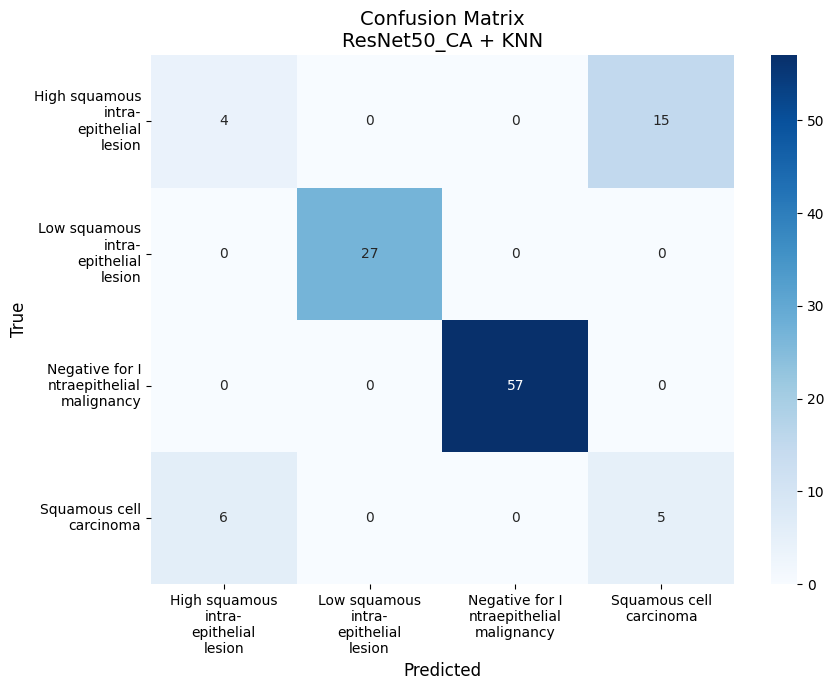

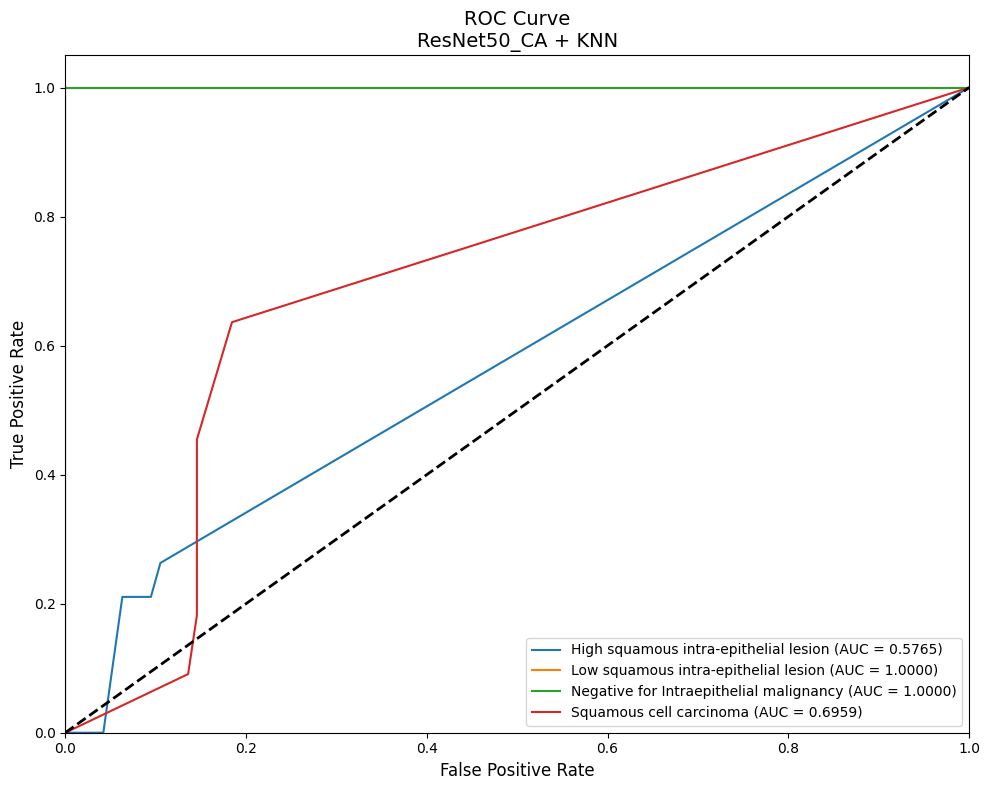


--- ResNet50_CA + MLP ---
Test Accuracy       : 0.807018
Meta training time  : 0.369783 s
Test time per image : 0.000007 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.450000  0.473684  0.461538        19
   Low squamous intra-epithelial lesion   0.900000  1.000000  0.947368        27
Negative for Intraepithelial malignancy   1.000000  0.982456  0.991150        57
                Squamous cell carcinoma   0.000000  0.000000  0.000000        11

                               accuracy                       0.807018       114
                              macro avg   0.587500  0.614035  0.600014       114
                           weighted avg   0.788158  0.807018  0.796875       114



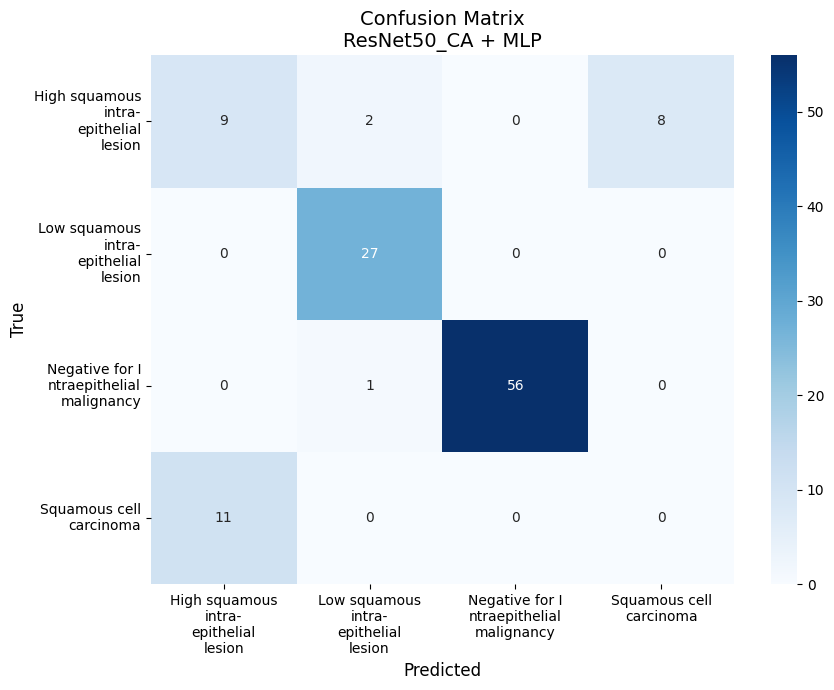

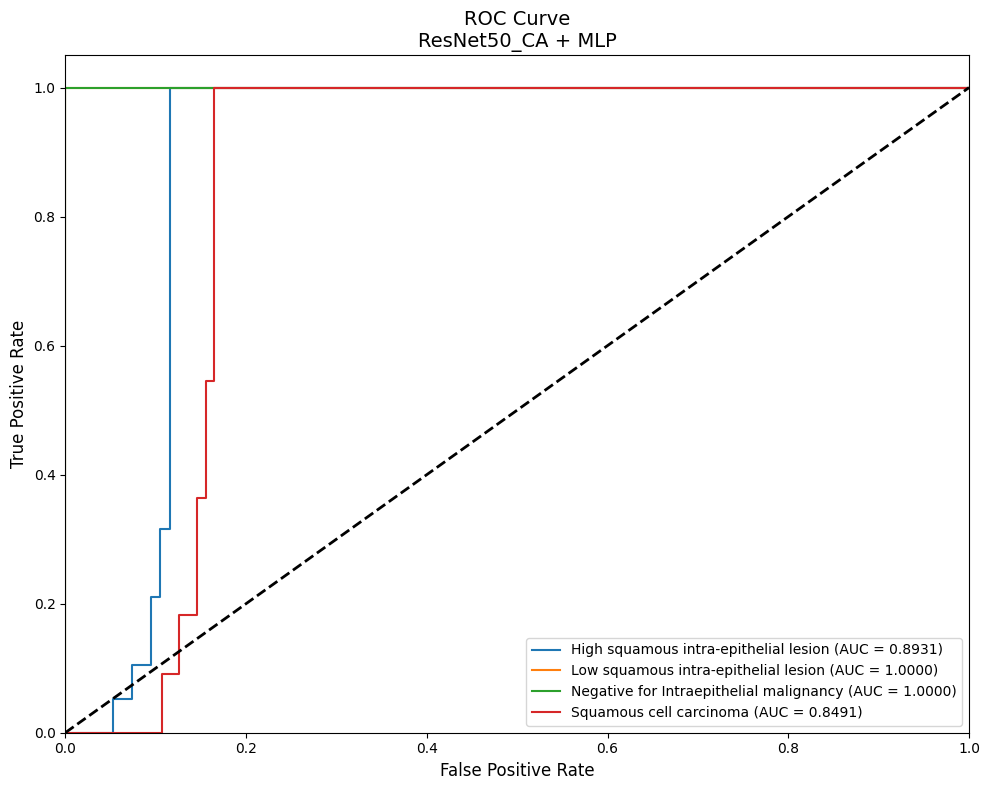


--- ResNet50_CA + RandomForest ---
Test Accuracy       : 0.807018
Meta training time  : 0.548882 s
Test time per image : 0.001067 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.363636  0.210526  0.266667        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   1.000000  1.000000  1.000000        57
                Squamous cell carcinoma   0.210526  0.363636  0.266667        11

                               accuracy                       0.807018       114
                              macro avg   0.643541  0.643541  0.633333       114
                           weighted avg   0.817762  0.807018  0.807018       114



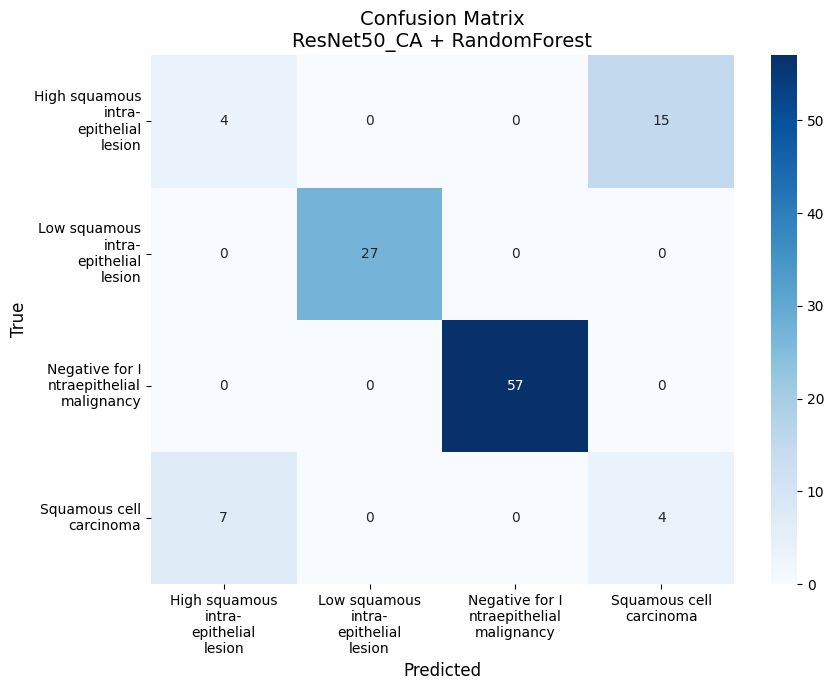

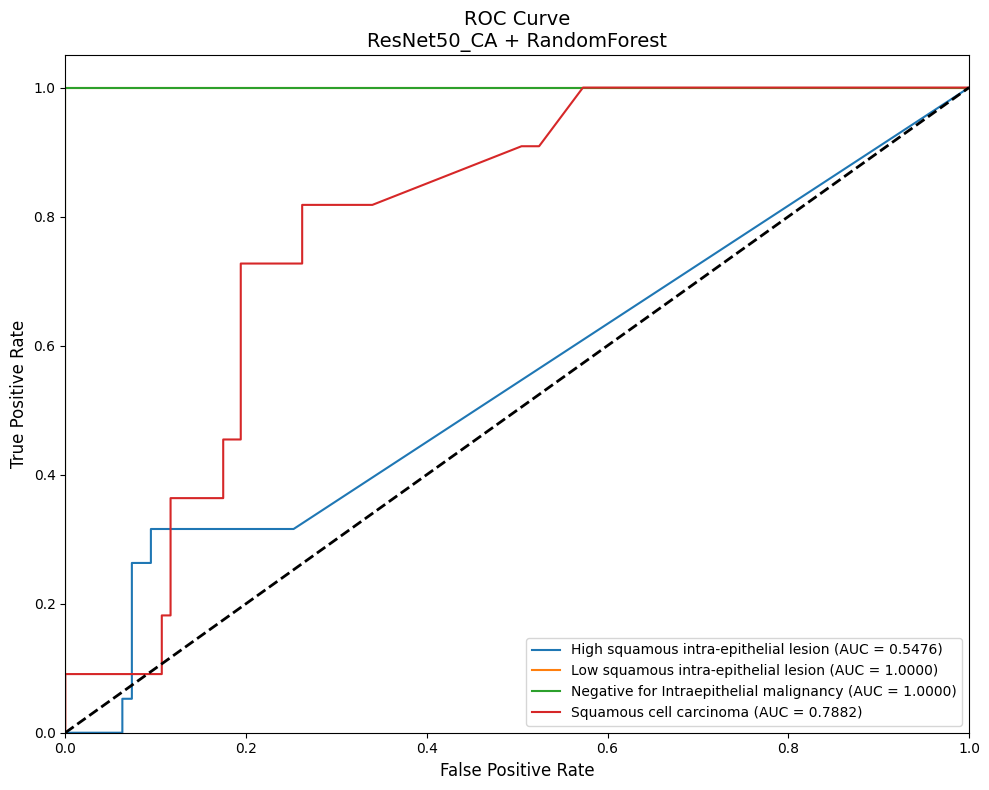


--- ResNet50_CA + CatBoost ---
Test Accuracy       : 0.798246
Meta training time  : 0.317551 s
Test time per image : 0.000022 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.384615  0.263158  0.312500        19
   Low squamous intra-epithelial lesion   0.900000  1.000000  0.947368        27
Negative for Intraepithelial malignancy   1.000000  0.982456  0.991150        57
                Squamous cell carcinoma   0.200000  0.272727  0.230769        11

                               accuracy                       0.798246       114
                              macro avg   0.621154  0.629585  0.620447       114
                           weighted avg   0.796559  0.798246  0.794302       114



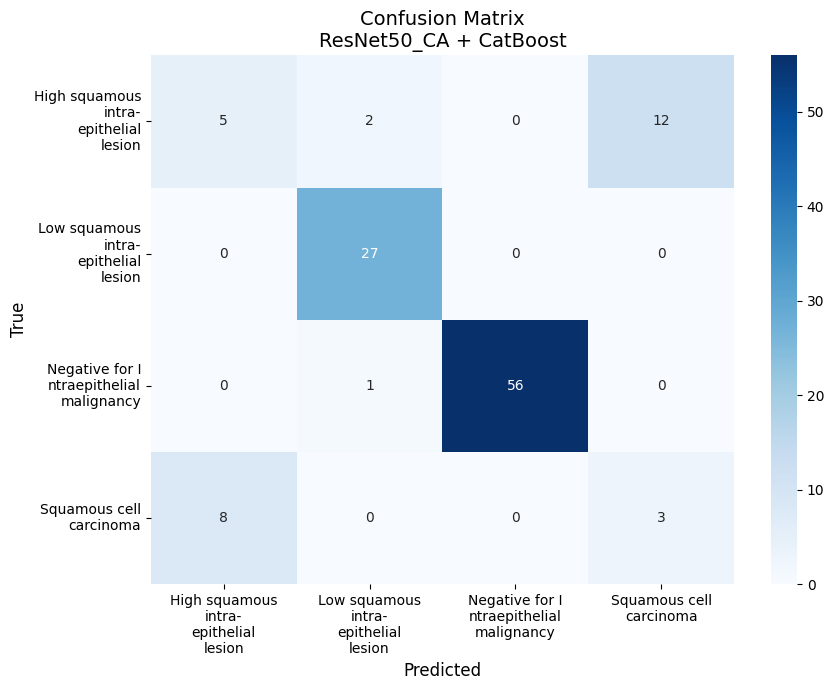

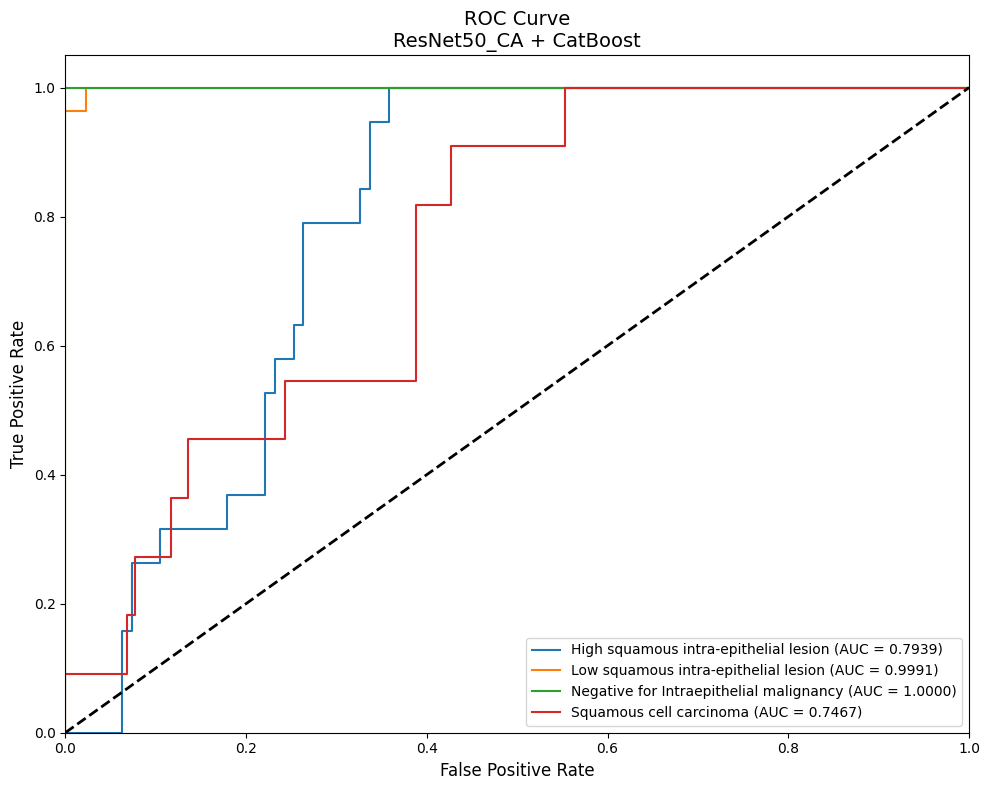

In [50]:
run_meta_classifiers("ResNet50_CA", show_plots=True)

### VGG16_CA

VGG16_CA + Meta-Classifiers (base accuracy on test: 0.868421)

--- VGG16_CA + KNN ---
Test Accuracy       : 0.815789
Meta training time  : 0.001151 s
Test time per image : 0.000038 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.333333  0.052632  0.090909        19
   Low squamous intra-epithelial lesion   1.000000  0.962963  0.981132        27
Negative for Intraepithelial malignancy   0.934426  1.000000  0.966102        57
                Squamous cell carcinoma   0.375000  0.818182  0.514286        11

                               accuracy                       0.815789       114
                              macro avg   0.660690  0.708444  0.638107       114
                           weighted avg   0.795795  0.815789  0.780200       114



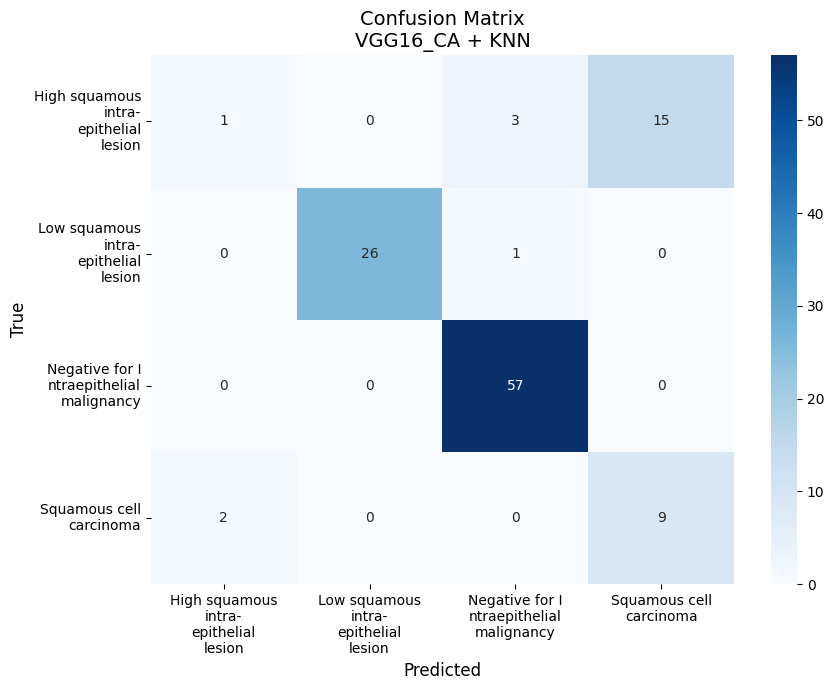

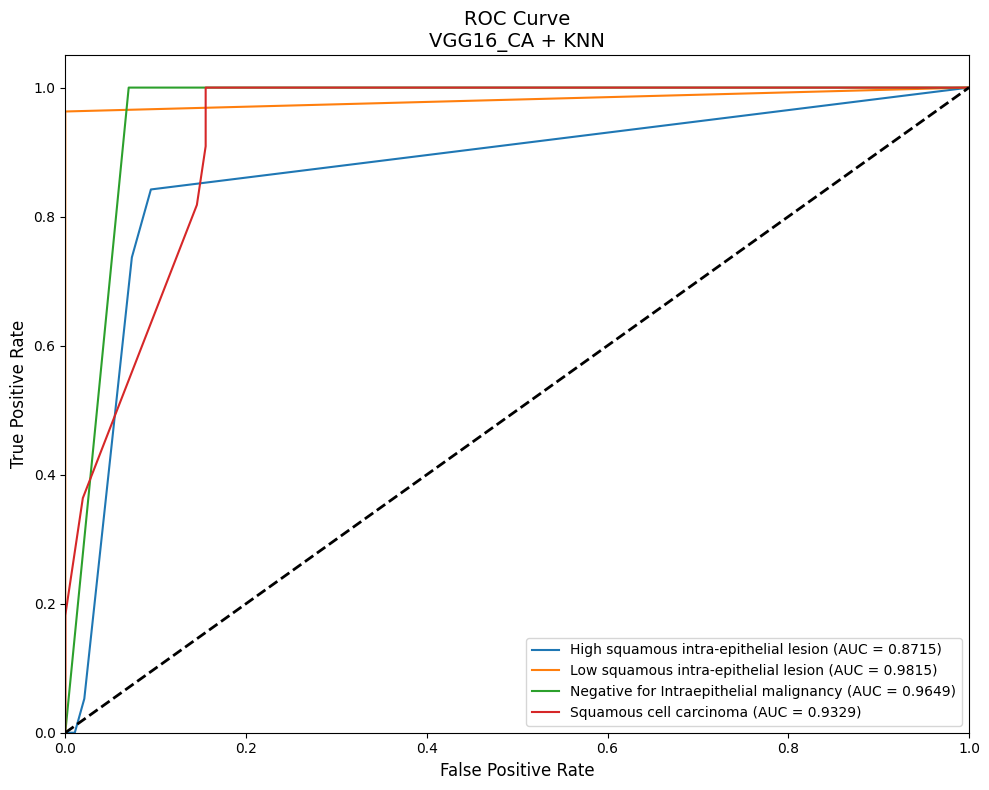


--- VGG16_CA + MLP ---
Test Accuracy       : 0.807018
Meta training time  : 0.233310 s
Test time per image : 0.000008 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.437500  0.368421  0.400000        19
   Low squamous intra-epithelial lesion   1.000000  0.962963  0.981132        27
Negative for Intraepithelial malignancy   0.919355  1.000000  0.957983        57
                Squamous cell carcinoma   0.200000  0.181818  0.190476        11

                               accuracy                       0.807018       114
                              macro avg   0.639214  0.628301  0.632398       114
                           weighted avg   0.788734  0.807018  0.796411       114



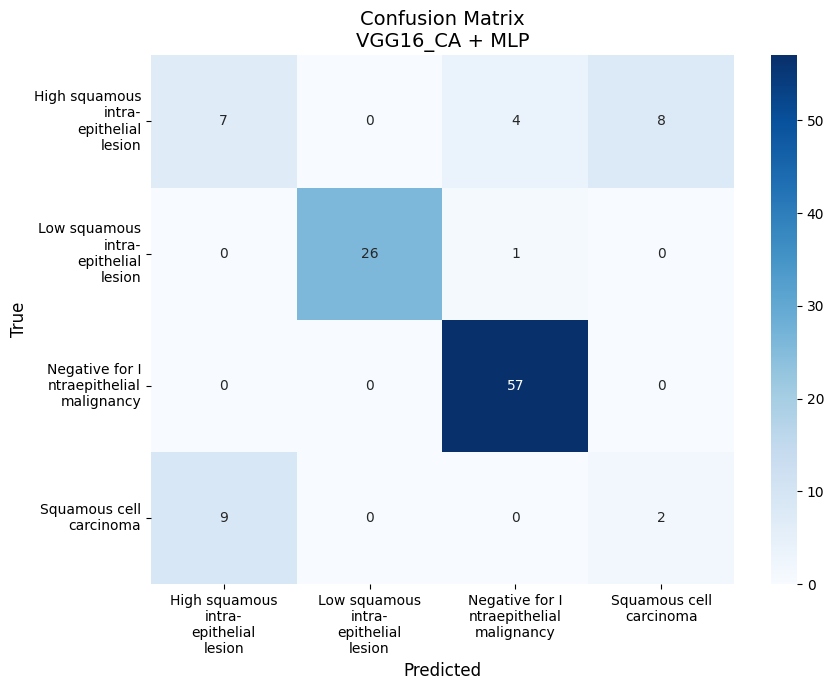

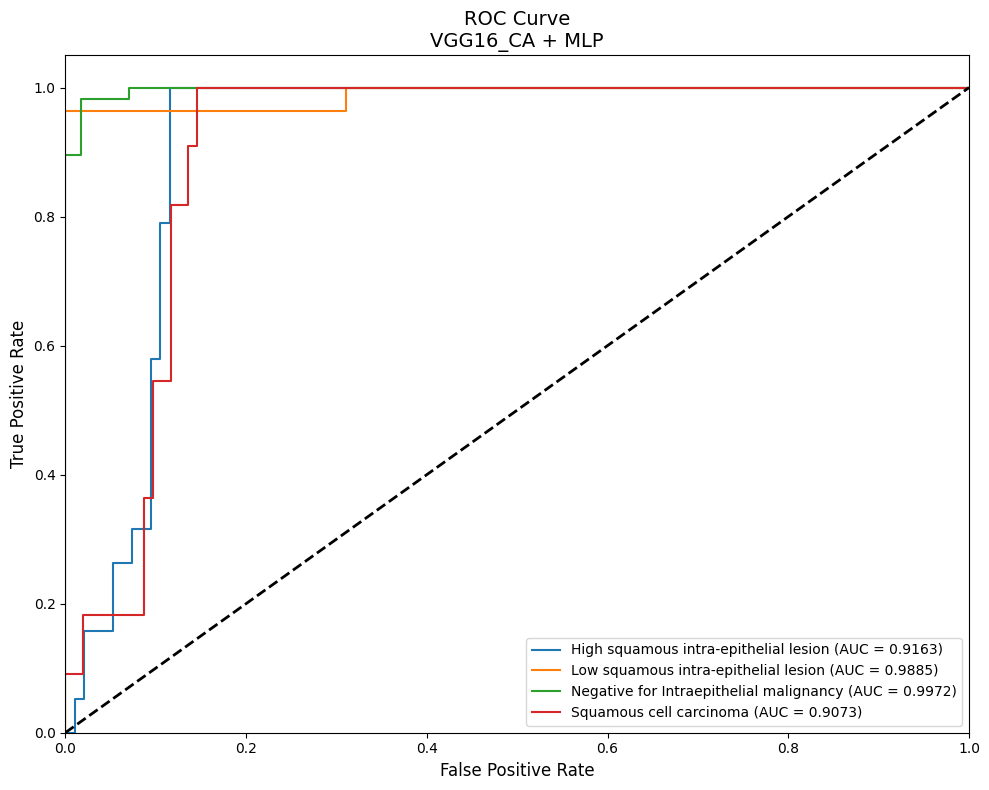


--- VGG16_CA + RandomForest ---
Test Accuracy       : 0.842105
Meta training time  : 0.569780 s
Test time per image : 0.001093 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   1.000000  0.105263  0.190476        19
   Low squamous intra-epithelial lesion   1.000000  0.962963  0.981132        27
Negative for Intraepithelial malignancy   0.934426  1.000000  0.966102        57
                Squamous cell carcinoma   0.440000  1.000000  0.611111        11

                               accuracy                       0.842105       114
                              macro avg   0.843607  0.767057  0.687205       114
                           weighted avg   0.913178  0.842105  0.806137       114



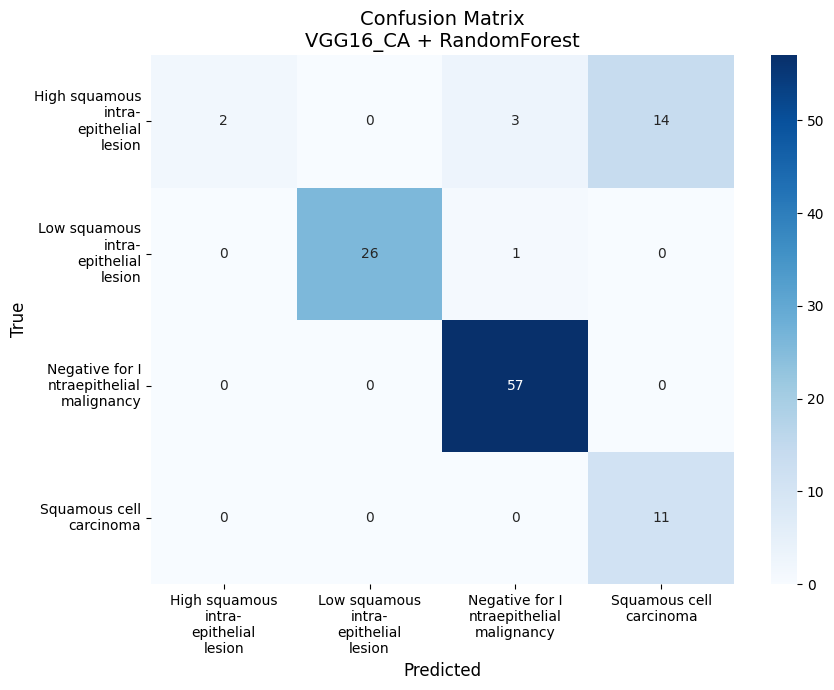

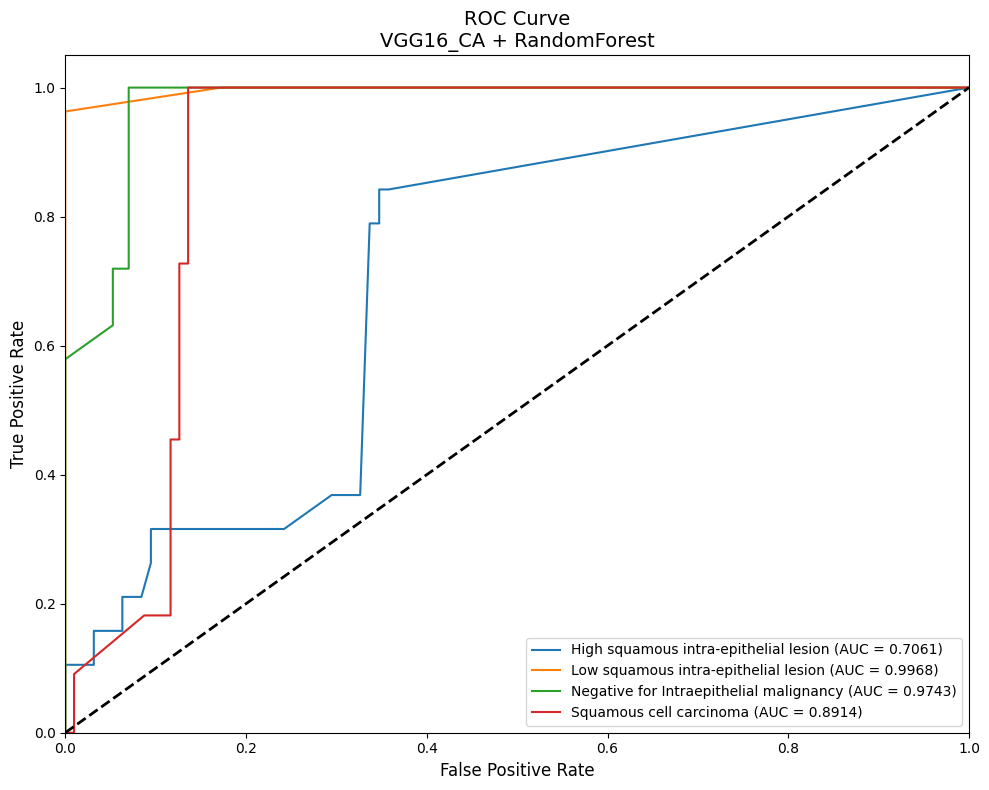


--- VGG16_CA + CatBoost ---
Test Accuracy       : 0.789474
Meta training time  : 0.305331 s
Test time per image : 0.000018 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.333333  0.052632  0.090909        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   1.000000  0.929825  0.963636        57
                Squamous cell carcinoma   0.290323  0.818182  0.428571        11

                               accuracy                       0.789474       114
                              macro avg   0.655914  0.700159  0.620779       114
                           weighted avg   0.820411  0.789474  0.775165       114



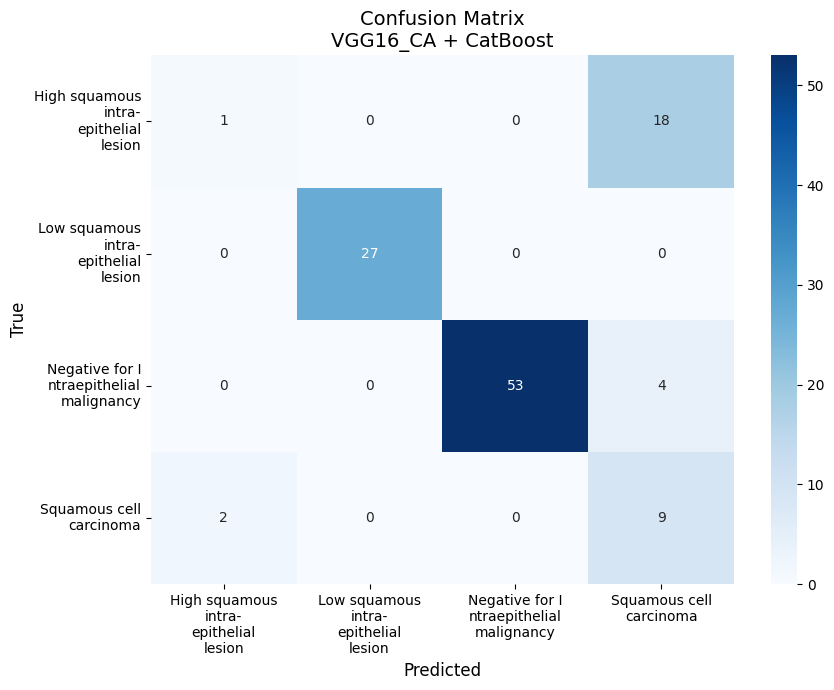

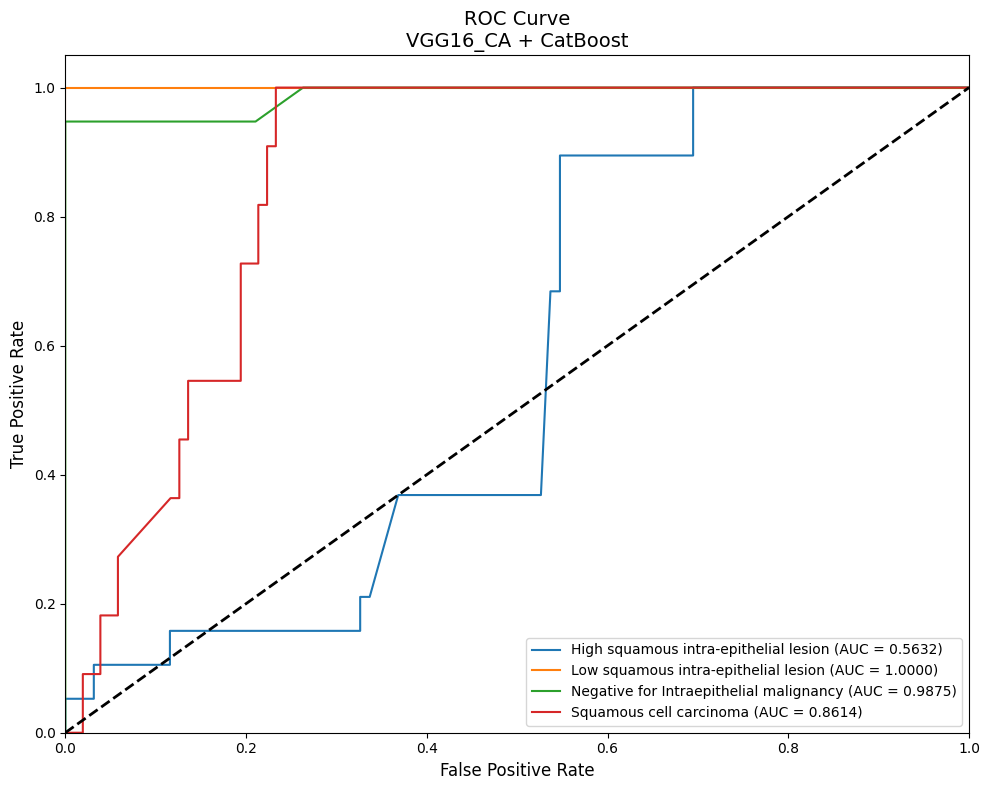

In [51]:
run_meta_classifiers("VGG16_CA", show_plots=True)

### Xception_ca

Xception_CA + Meta-Classifiers (base accuracy on test: 0.894737)

--- Xception_CA + KNN ---
Test Accuracy       : 0.824561
Meta training time  : 0.001003 s
Test time per image : 0.000042 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.461538  0.315789  0.375000        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   1.000000  1.000000  1.000000        57
                Squamous cell carcinoma   0.235294  0.363636  0.285714        11

                               accuracy                       0.824561       114
                              macro avg   0.674208  0.669856  0.665179       114
                           weighted avg   0.836469  0.824561  0.826911       114



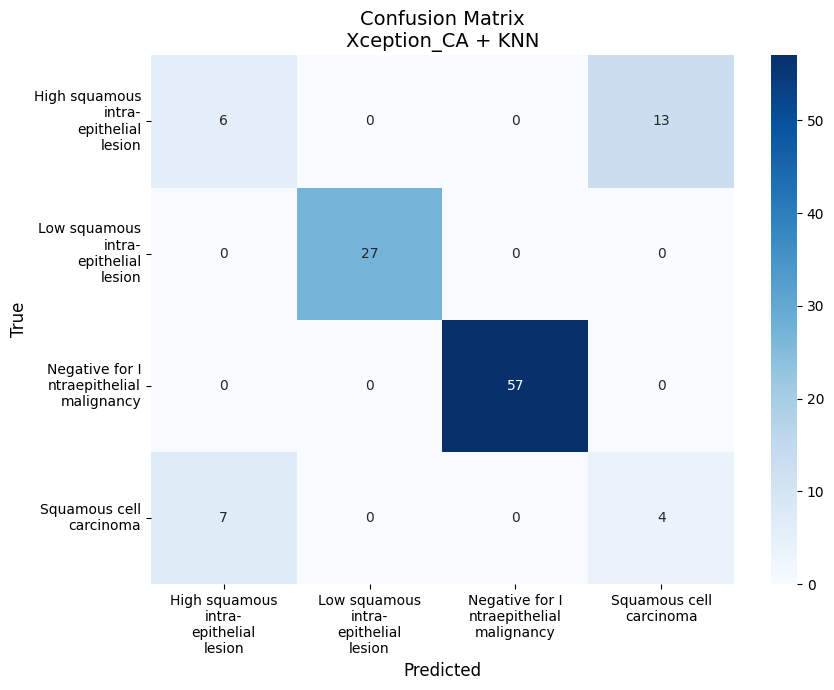

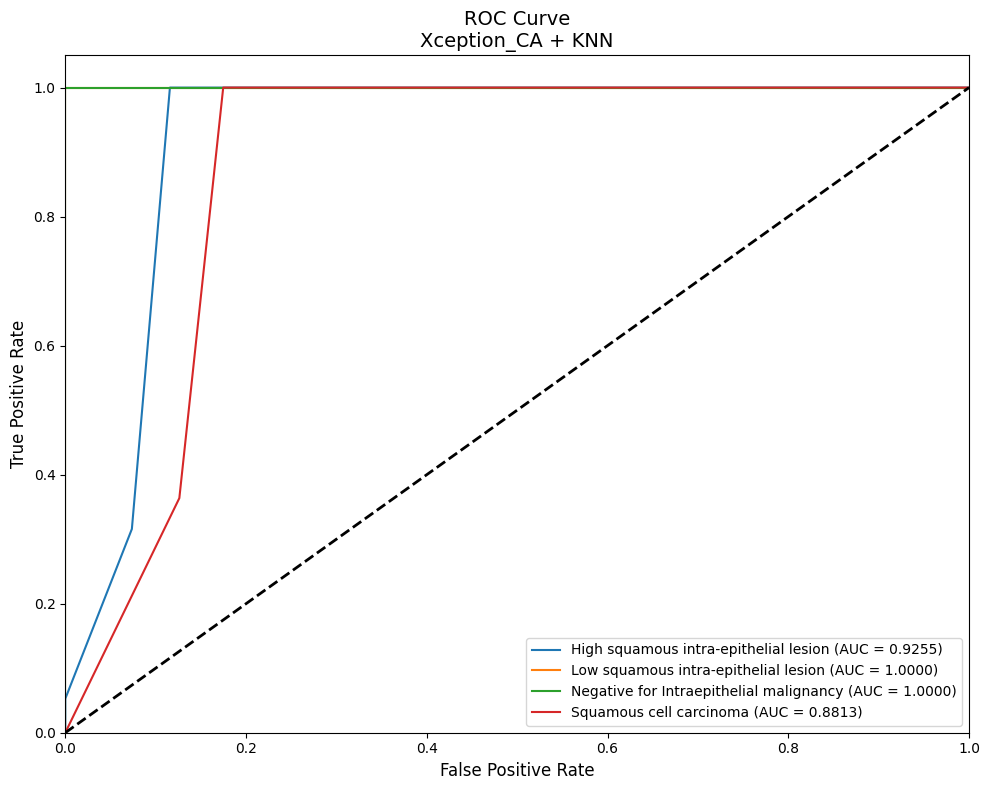


--- Xception_CA + MLP ---
Test Accuracy       : 0.859649
Meta training time  : 0.231358 s
Test time per image : 0.000008 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.571429  0.631579  0.600000        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   0.966102  1.000000  0.982759        57
                Squamous cell carcinoma   0.285714  0.181818  0.222222        11

                               accuracy                       0.859649       114
                              macro avg   0.705811  0.703349  0.701245       114
                           weighted avg   0.842700  0.859649  0.849664       114



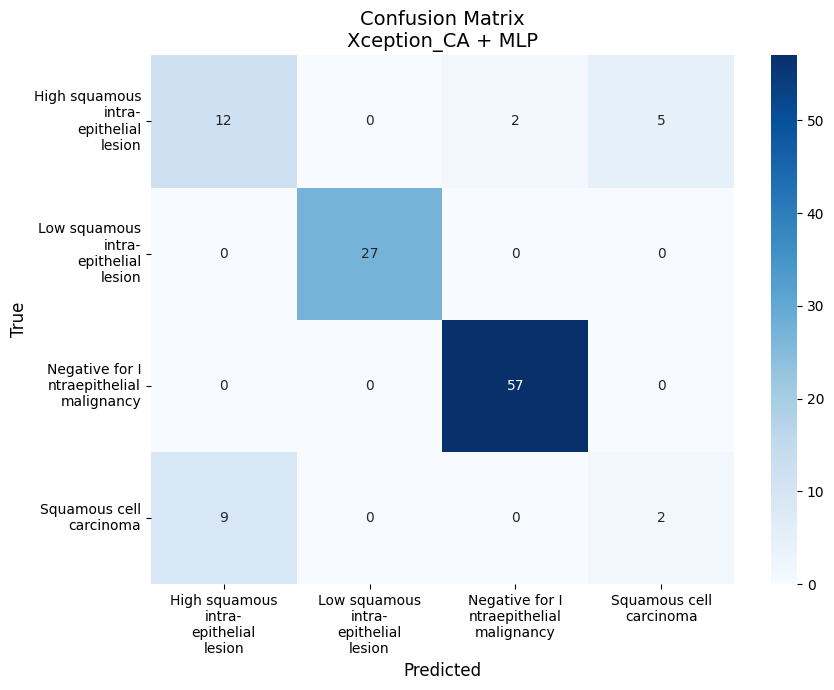

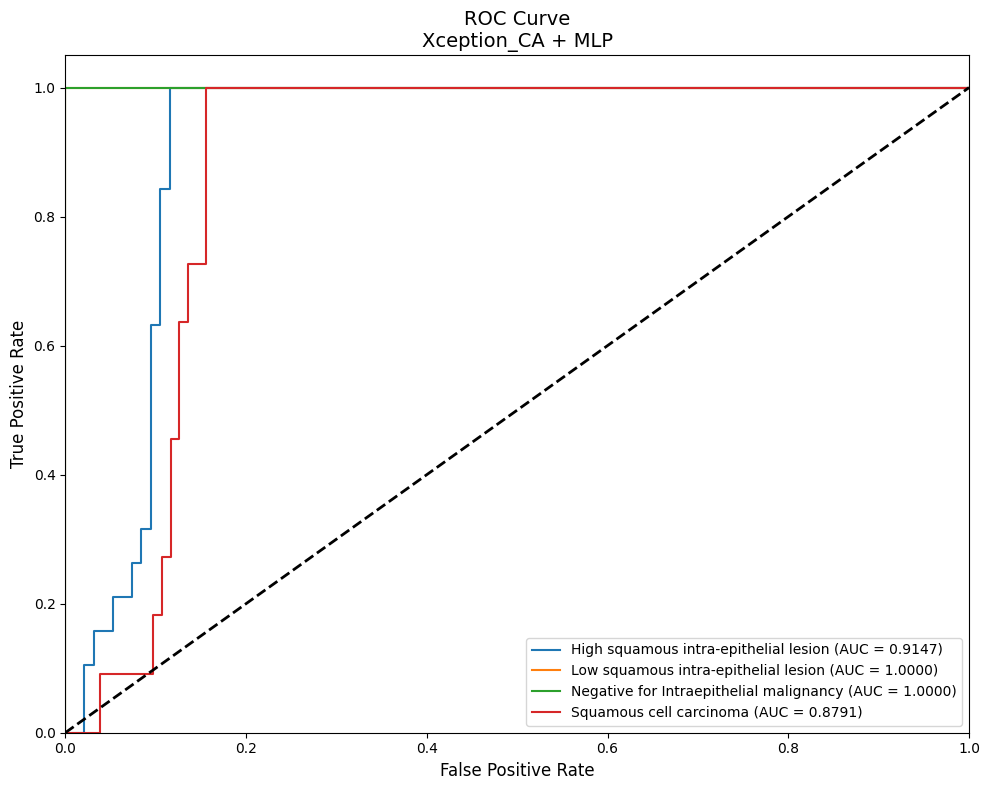


--- Xception_CA + RandomForest ---
Test Accuracy       : 0.807018
Meta training time  : 0.553965 s
Test time per image : 0.001067 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.444444  0.210526  0.285714        19
   Low squamous intra-epithelial lesion   0.900000  1.000000  0.947368        27
Negative for Intraepithelial malignancy   1.000000  0.982456  0.991150        57
                Squamous cell carcinoma   0.263158  0.454545  0.333333        11

                               accuracy                       0.807018       114
                              macro avg   0.651901  0.661882  0.639392       114
                           weighted avg   0.812624  0.807018  0.799735       114



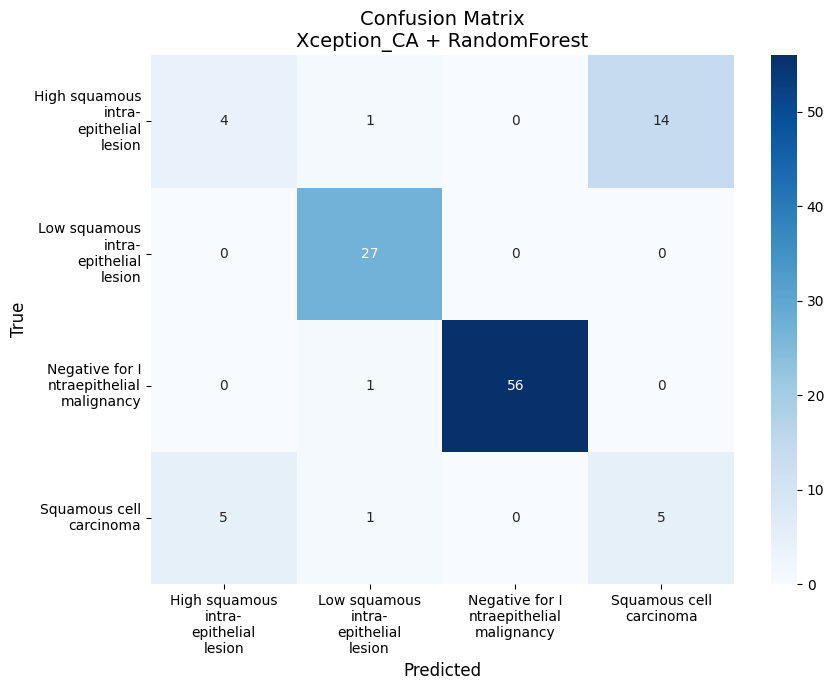

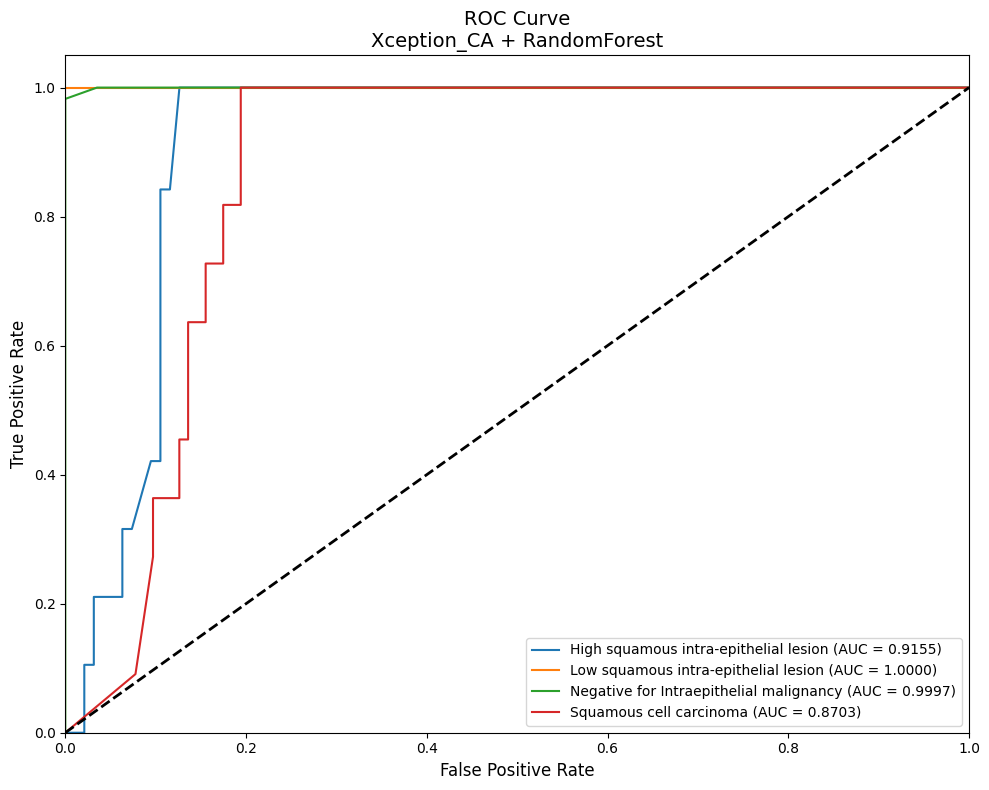


--- Xception_CA + CatBoost ---
Test Accuracy       : 0.807018
Meta training time  : 0.317176 s
Test time per image : 0.000019 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.375000  0.157895  0.222222        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   0.950000  1.000000  0.974359        57
                Squamous cell carcinoma   0.263158  0.454545  0.333333        11

                               accuracy                       0.807018       114
                              macro avg   0.647039  0.653110  0.632479       114
                           weighted avg   0.799735  0.807018  0.793222       114



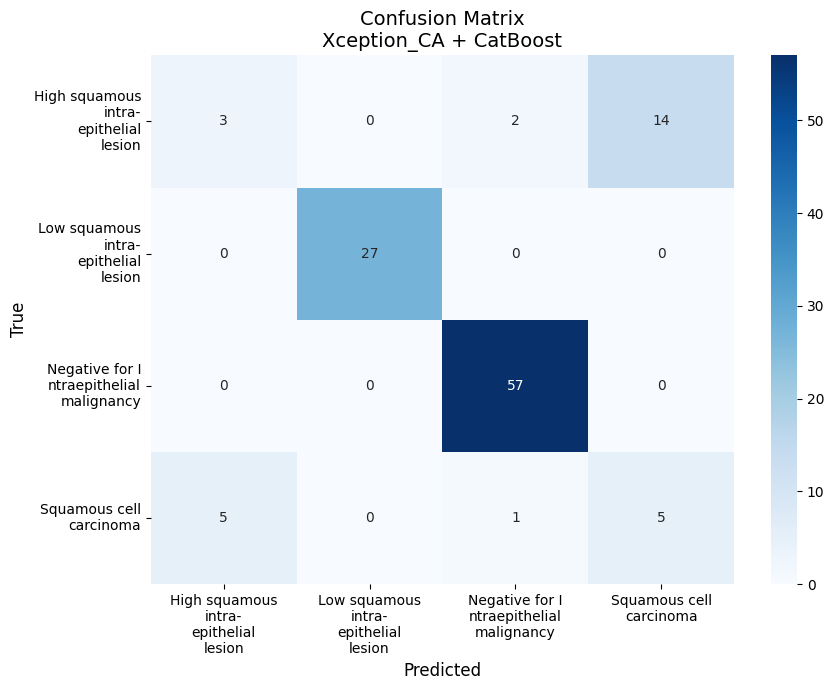

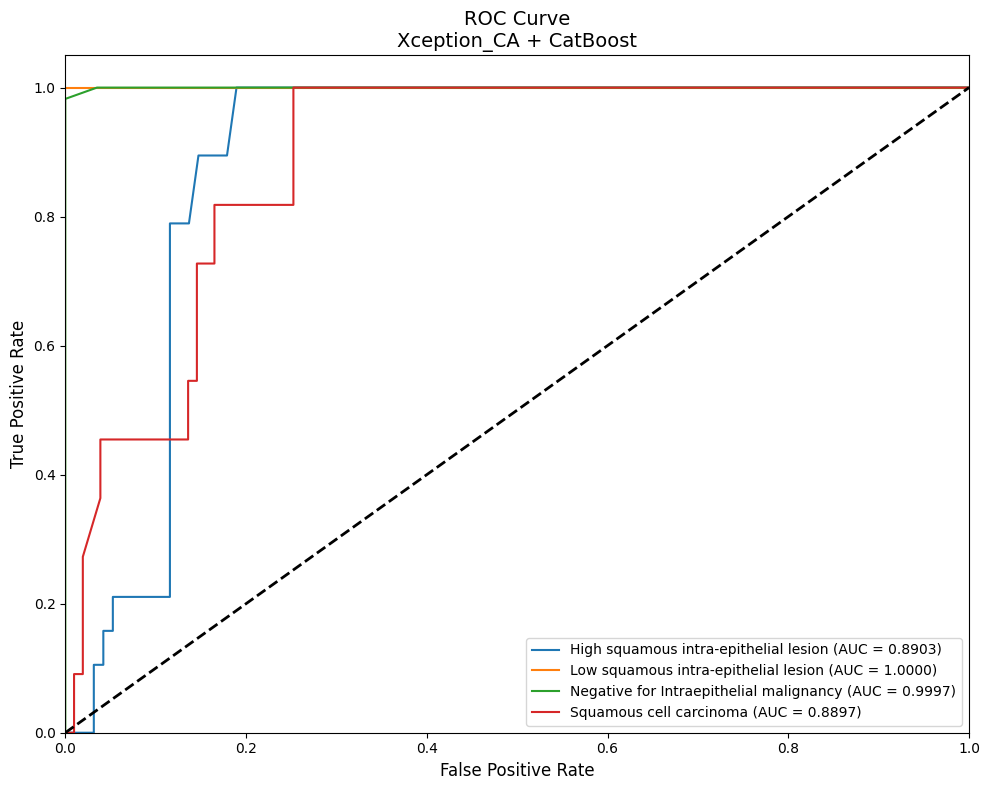

In [52]:
run_meta_classifiers("Xception_CA", show_plots=True)

### DenseNet121_ca

DenseNet_CA + Meta-Classifiers (base accuracy on test: 0.859649)

--- DenseNet_CA + KNN ---
Test Accuracy       : 0.798246
Meta training time  : 0.000933 s
Test time per image : 0.000043 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.000000  0.000000  0.000000        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   0.949153  0.982456  0.965517        57
                Squamous cell carcinoma   0.320000  0.727273  0.444444        11

                               accuracy                       0.798246       114
                              macro avg   0.567288  0.677432  0.602490       114
                           weighted avg   0.742296  0.798246  0.762486       114



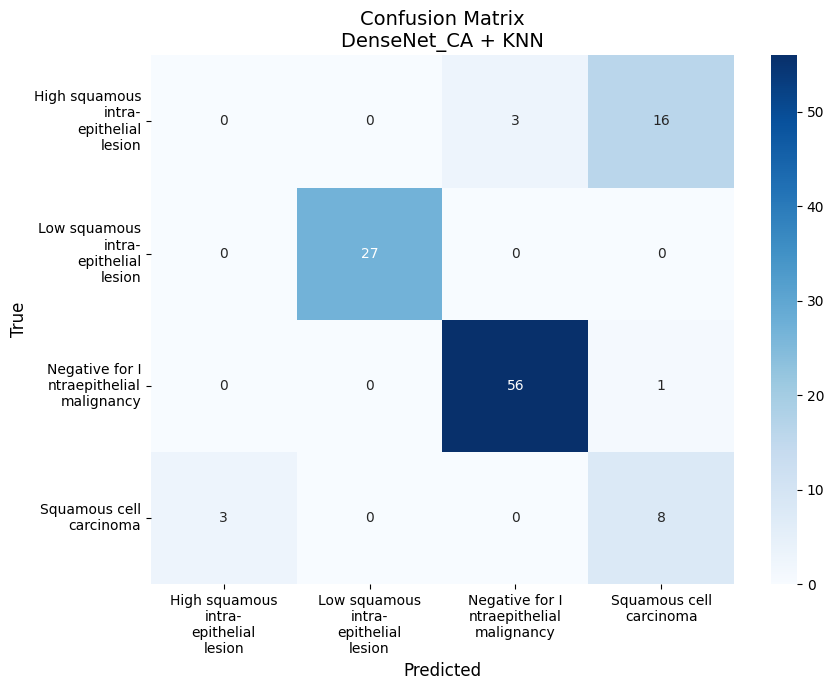

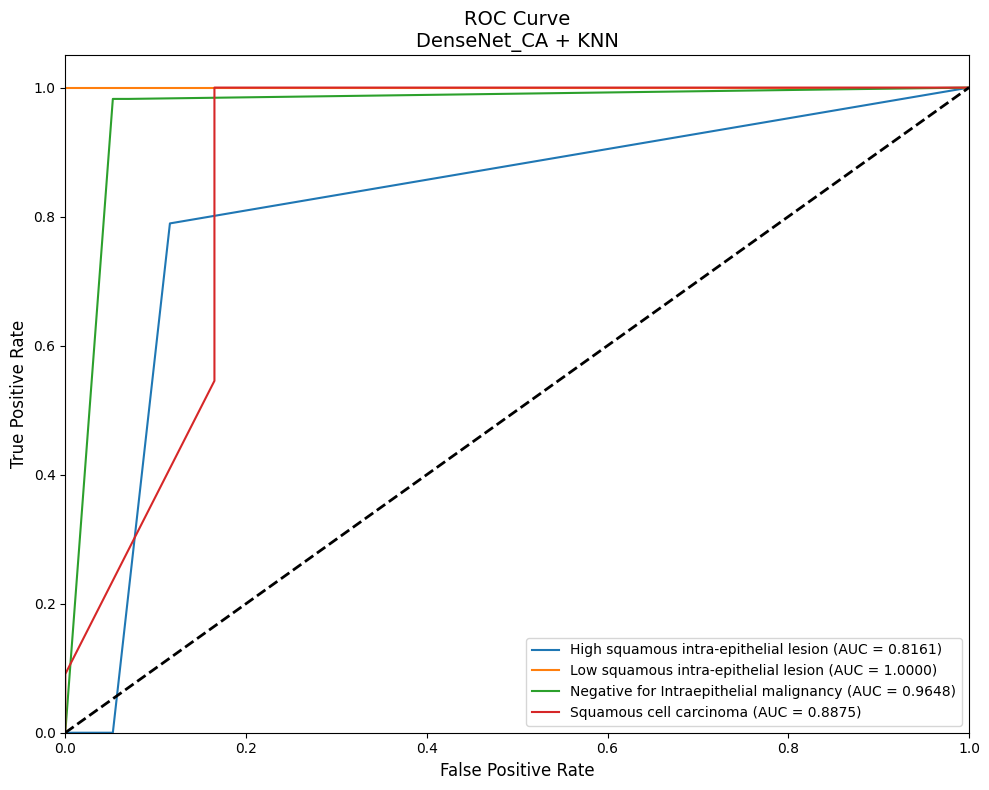


--- DenseNet_CA + MLP ---
Test Accuracy       : 0.780702
Meta training time  : 0.495673 s
Test time per image : 0.000010 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.000000  0.000000  0.000000        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   0.875000  0.982456  0.925620        57
                Squamous cell carcinoma   0.315789  0.545455  0.400000        11

                               accuracy                       0.780702       114
                              macro avg   0.547697  0.631978  0.581405       114
                           weighted avg   0.704813  0.780702  0.738249       114



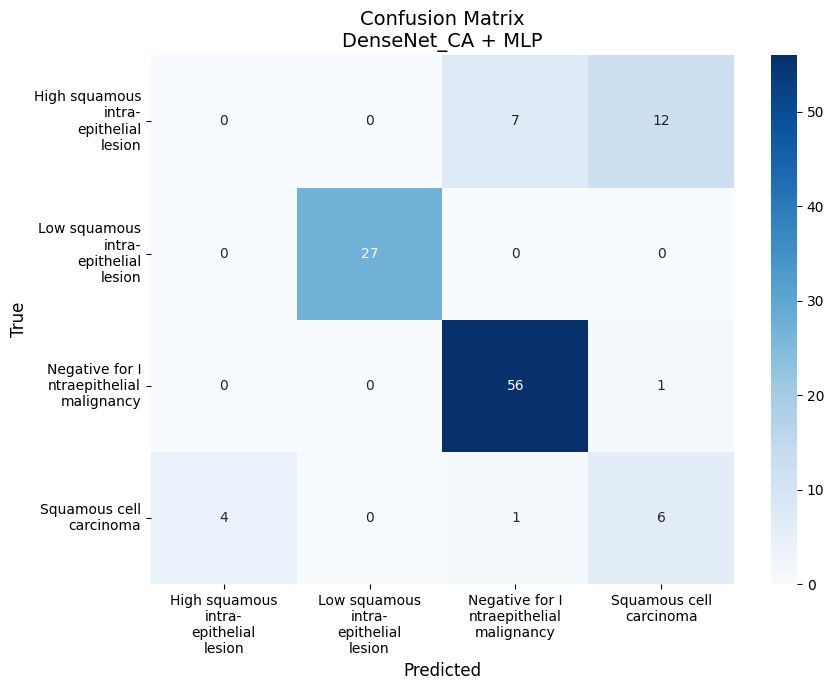

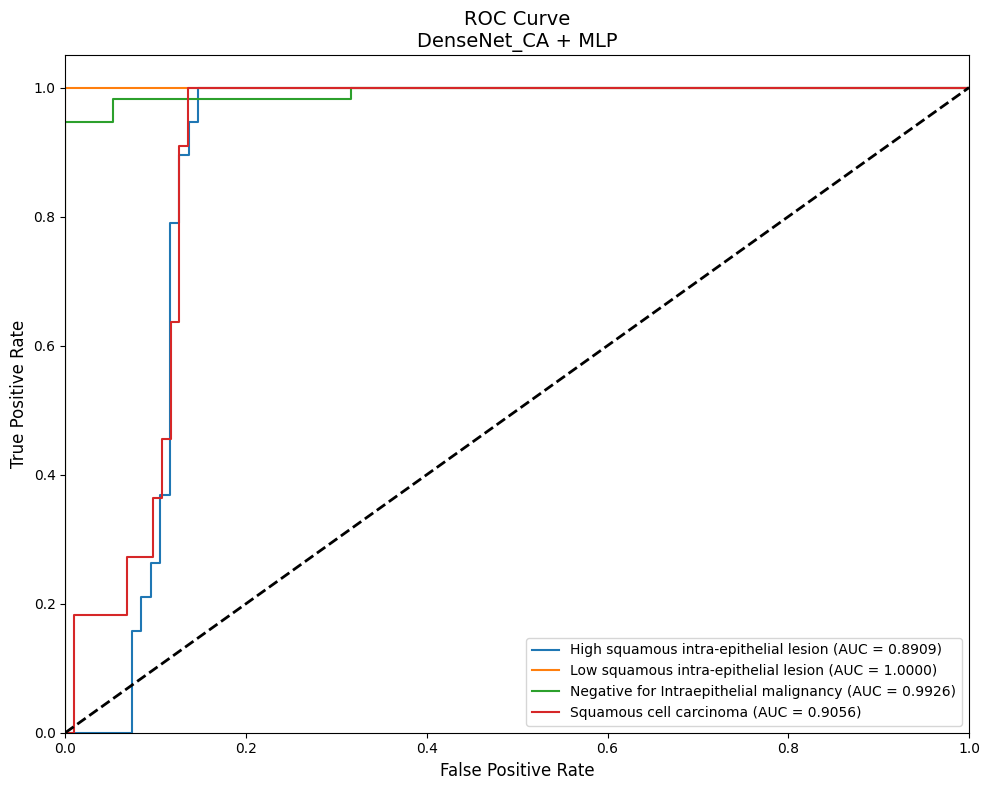


--- DenseNet_CA + RandomForest ---
Test Accuracy       : 0.780702
Meta training time  : 0.551106 s
Test time per image : 0.001096 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.000000  0.000000  0.000000        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   0.964286  0.947368  0.955752        57
                Squamous cell carcinoma   0.285714  0.727273  0.410256        11

                               accuracy                       0.780702       114
                              macro avg   0.562500  0.668660  0.591502       114
                           weighted avg   0.746554  0.780702  0.754304       114



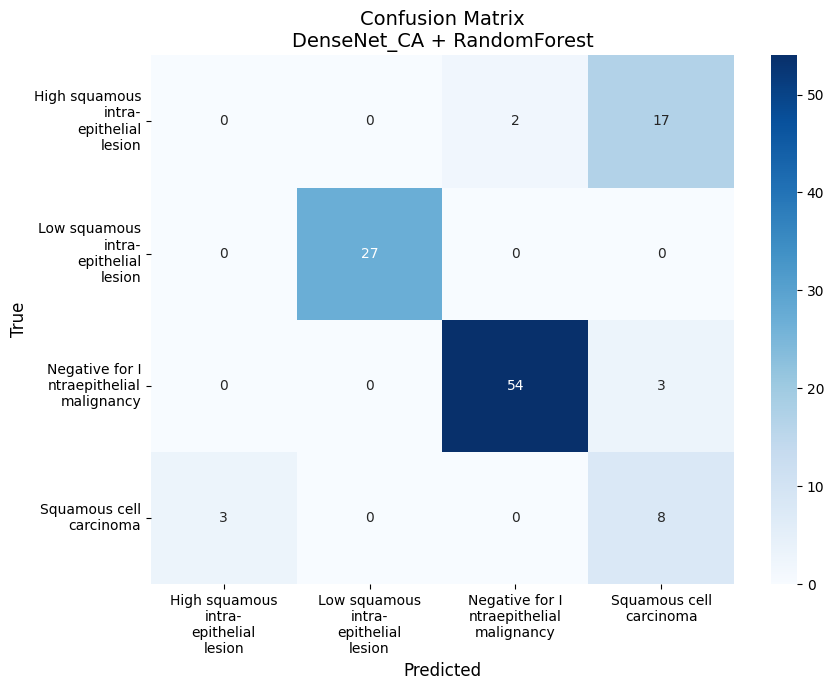

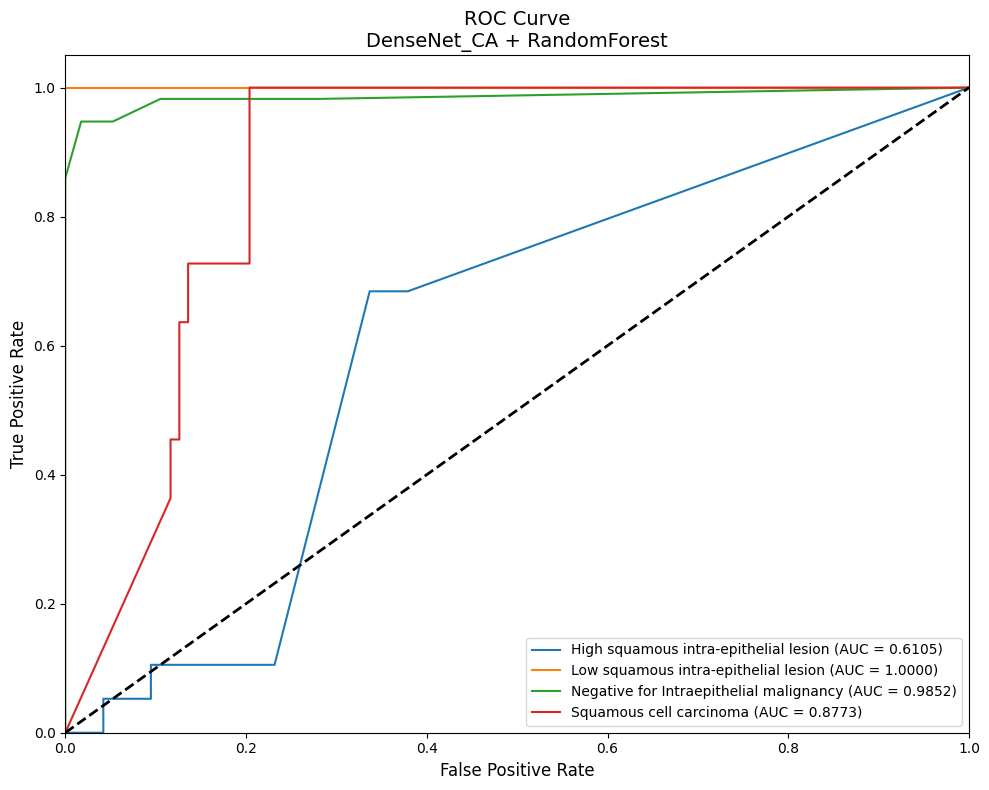


--- DenseNet_CA + CatBoost ---
Test Accuracy       : 0.745614
Meta training time  : 0.306852 s
Test time per image : 0.000018 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.000000  0.000000  0.000000        19
   Low squamous intra-epithelial lesion   1.000000  0.962963  0.981132        27
Negative for Intraepithelial malignancy   0.980769  0.894737  0.935780        57
                Squamous cell carcinoma   0.242424  0.727273  0.363636        11

                               accuracy                       0.745614       114
                              macro avg   0.555798  0.646243  0.570137       114
                           weighted avg   0.750619  0.745614  0.735351       114



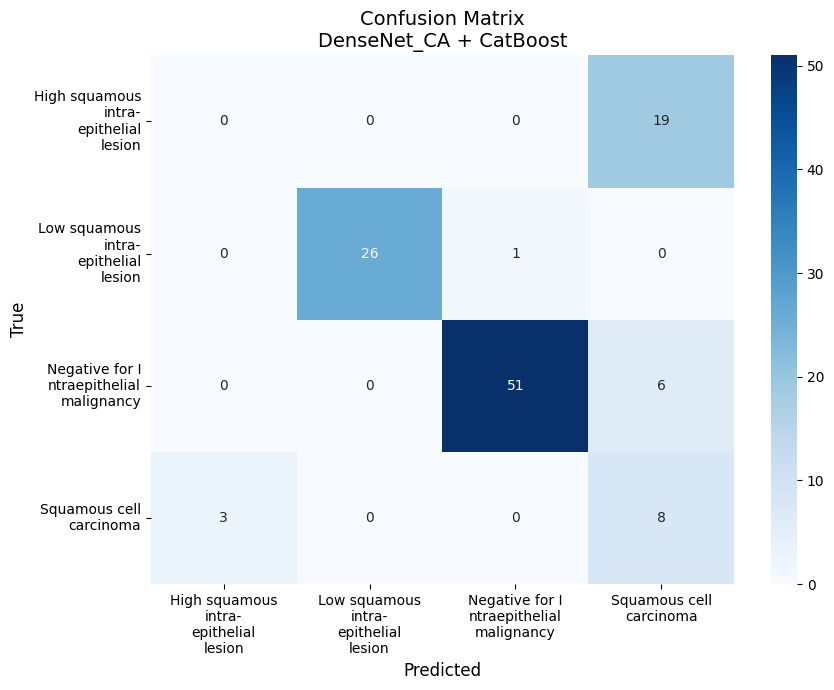

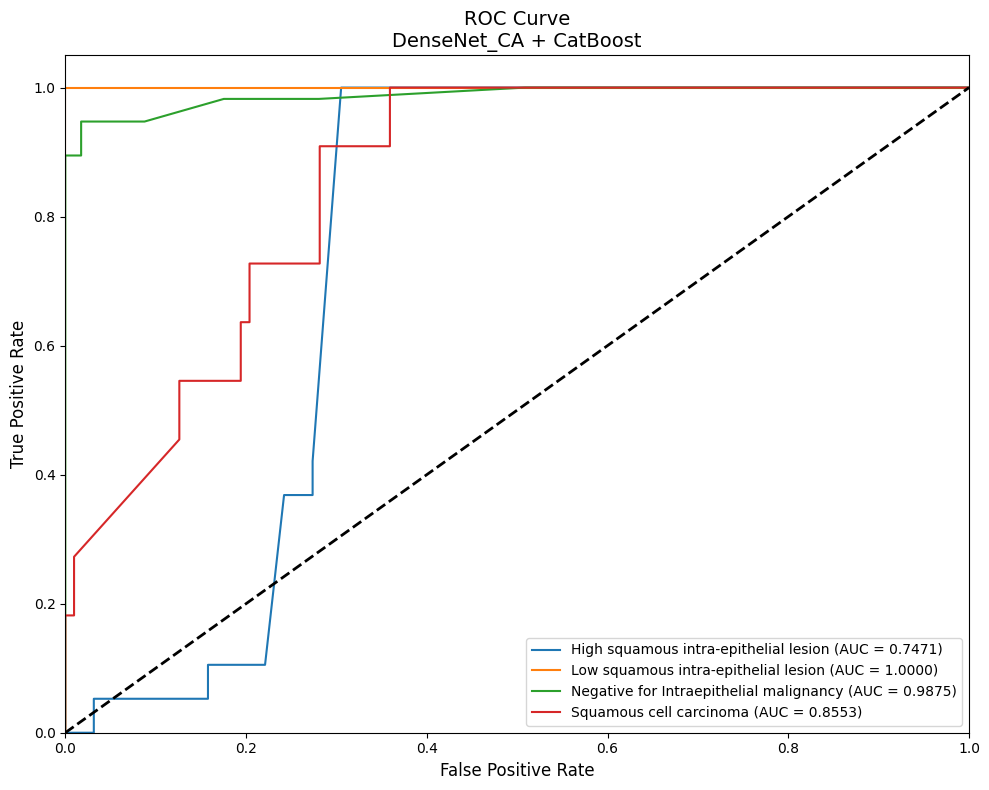

In [53]:
run_meta_classifiers("DenseNet_CA", show_plots=True)

### VGG19_ca

VGG19_CA + Meta-Classifiers (base accuracy on test: 0.885965)

--- VGG19_CA + KNN ---
Test Accuracy       : 0.921053
Meta training time  : 0.001523 s
Test time per image : 0.000040 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.727273  0.842105  0.780488        19
   Low squamous intra-epithelial lesion   0.964286  1.000000  0.981818        27
Negative for Intraepithelial malignancy   0.982759  1.000000  0.991304        57
                Squamous cell carcinoma   0.833333  0.454545  0.588235        11

                               accuracy                       0.921053       114
                              macro avg   0.876913  0.824163  0.835461       114
                           weighted avg   0.921384  0.921053  0.915029       114



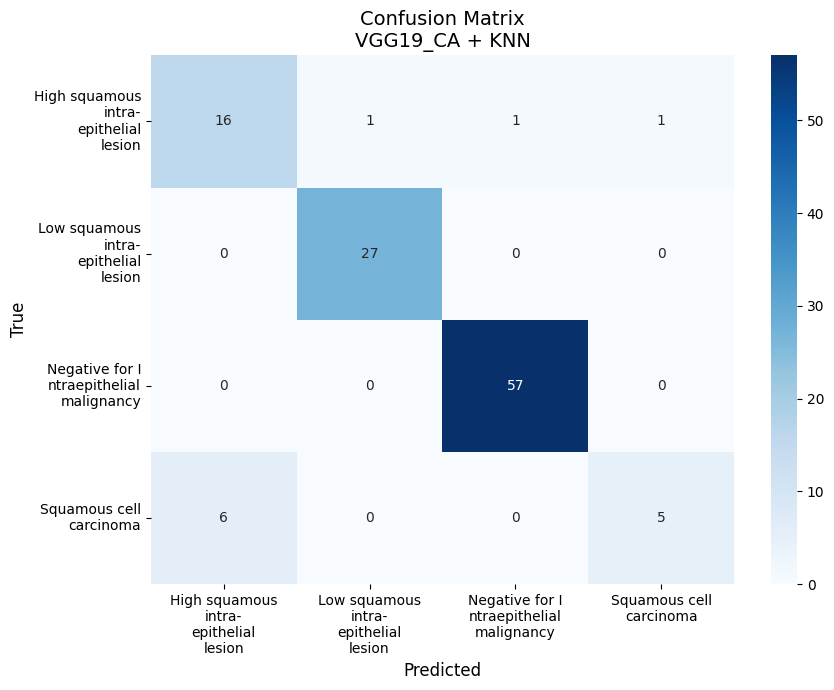

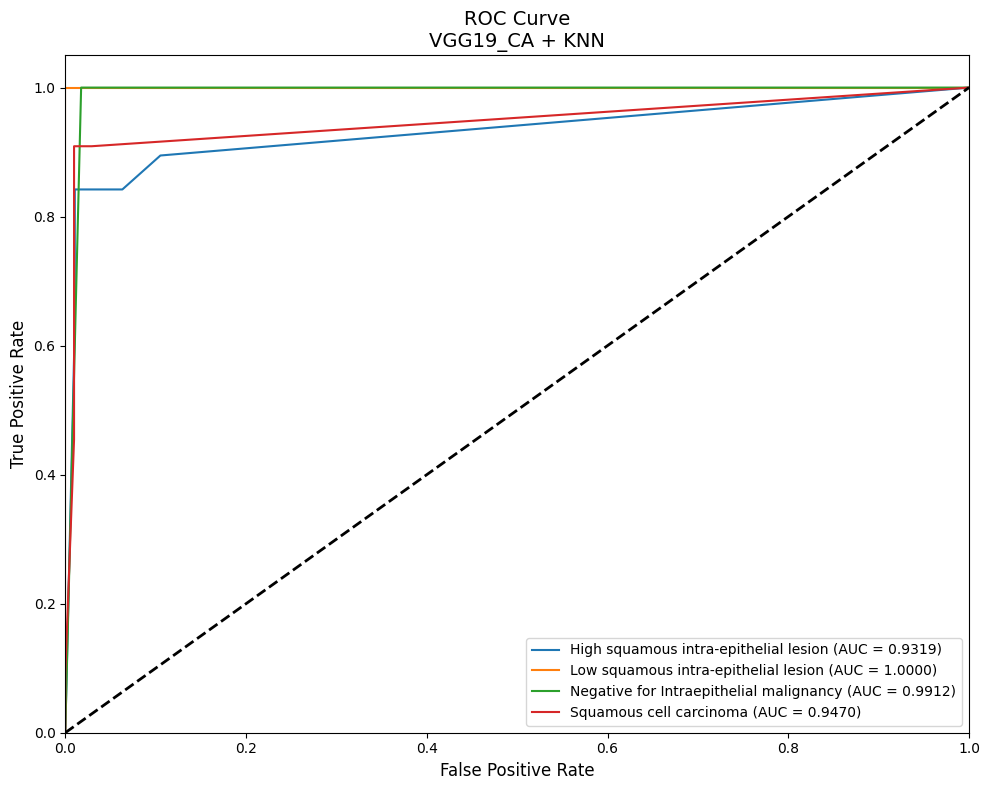


--- VGG19_CA + MLP ---
Test Accuracy       : 0.877193
Meta training time  : 0.440989 s
Test time per image : 0.000008 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.592593  0.842105  0.695652        19
   Low squamous intra-epithelial lesion   0.964286  1.000000  0.981818        27
Negative for Intraepithelial malignancy   0.966102  1.000000  0.982759        57
                Squamous cell carcinoma   0.000000  0.000000  0.000000        11

                               accuracy                       0.877193       114
                              macro avg   0.630745  0.710526  0.665057       114
                           weighted avg   0.810200  0.877193  0.839857       114



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


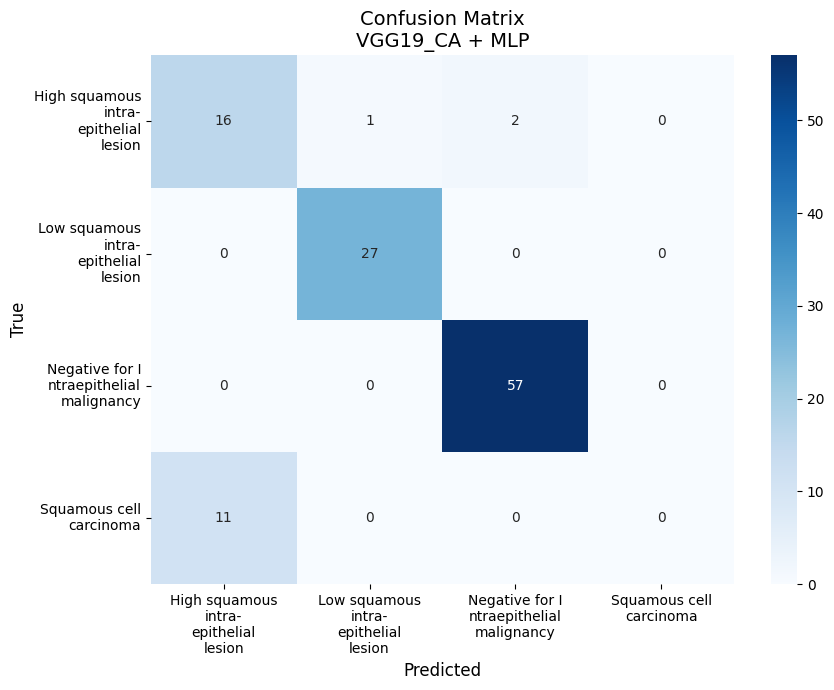

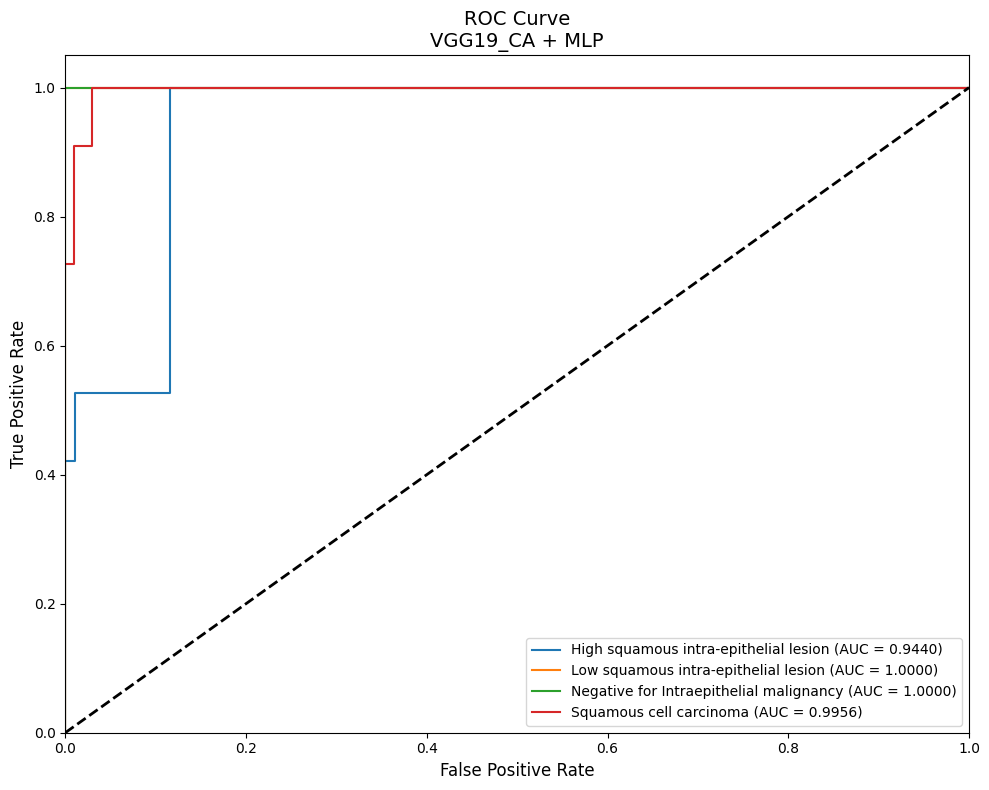


--- VGG19_CA + RandomForest ---
Test Accuracy       : 0.903509
Meta training time  : 0.552166 s
Test time per image : 0.001160 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.653846  0.894737  0.755556        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   0.982759  1.000000  0.991304        57
                Squamous cell carcinoma   0.666667  0.181818  0.285714        11

                               accuracy                       0.903509       114
                              macro avg   0.825818  0.769139  0.758144       114
                           weighted avg   0.901523  0.903509  0.885989       114



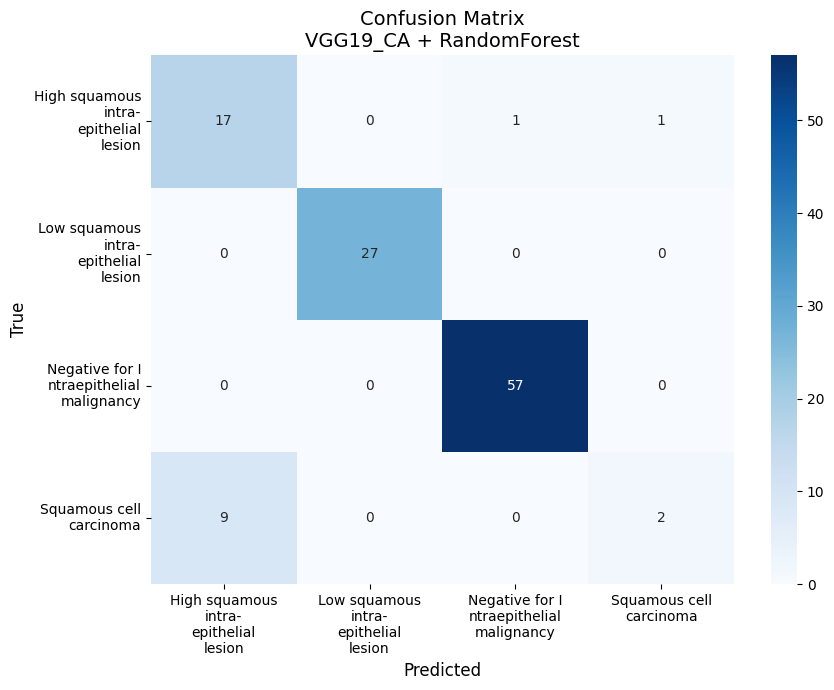

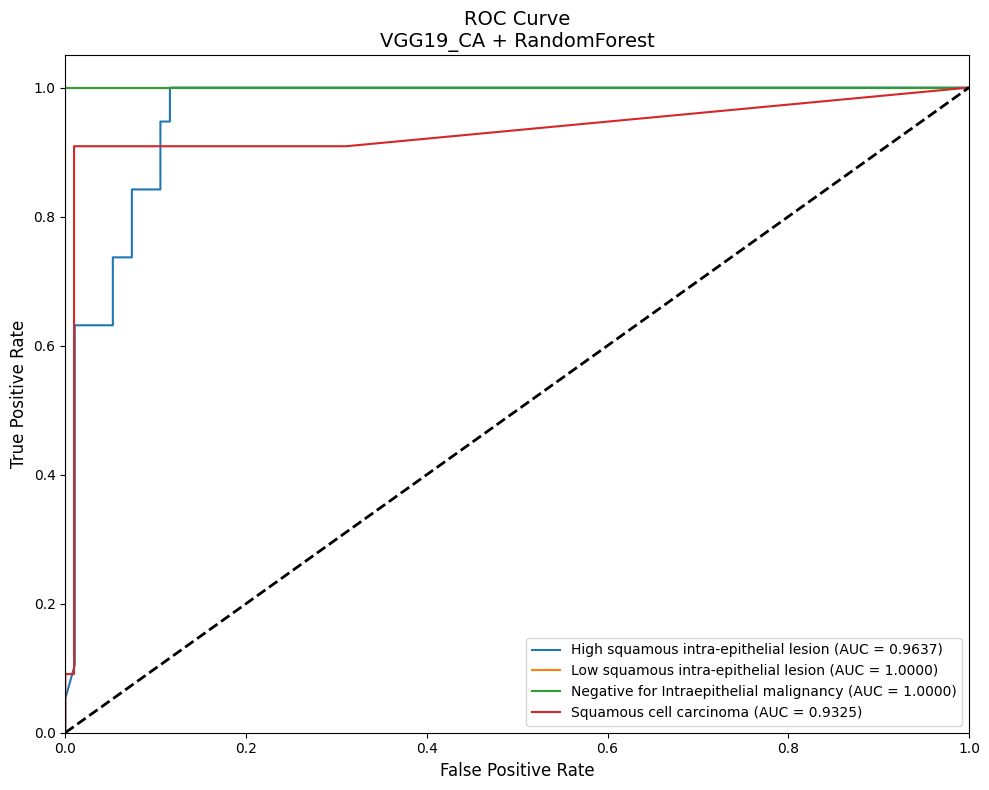


--- VGG19_CA + CatBoost ---
Test Accuracy       : 0.868421
Meta training time  : 0.308074 s
Test time per image : 0.000017 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.600000  0.631579  0.615385        19
   Low squamous intra-epithelial lesion   0.818182  1.000000  0.900000        27
Negative for Intraepithelial malignancy   1.000000  1.000000  1.000000        57
                Squamous cell carcinoma   0.750000  0.272727  0.400000        11

                               accuracy                       0.868421       114
                              macro avg   0.792045  0.726077  0.728846       114
                           weighted avg   0.866148  0.868421  0.854318       114



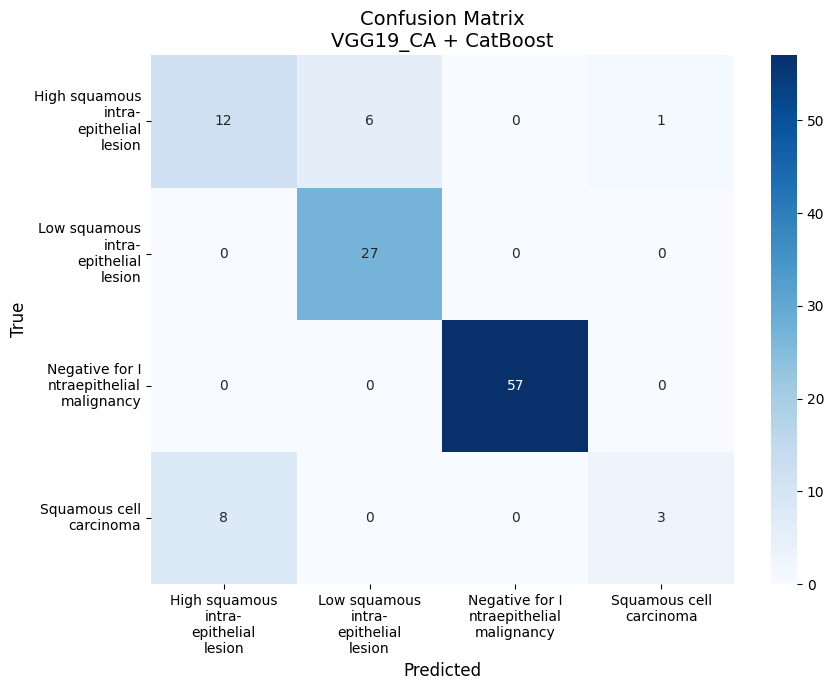

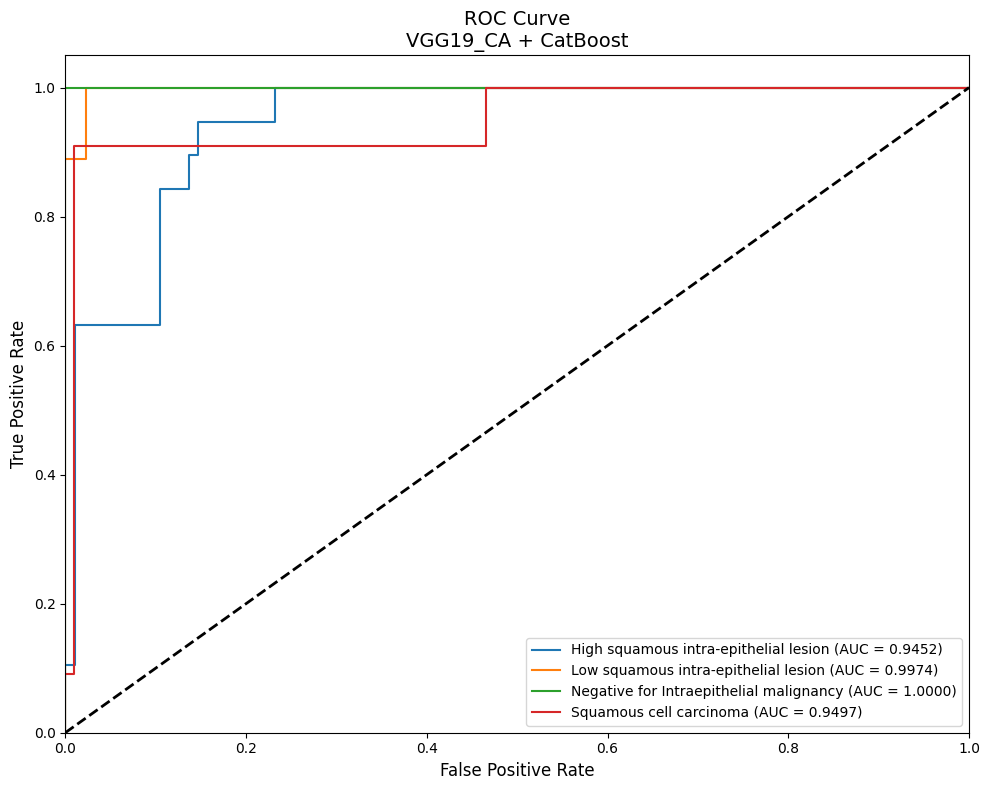

In [54]:
run_meta_classifiers("VGG19_CA", show_plots=True)

### Inception_ca

Inception_CA + Meta-Classifiers (base accuracy on test: 0.798246)

--- Inception_CA + KNN ---
Test Accuracy       : 0.850877
Meta training time  : 0.001641 s
Test time per image : 0.000040 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.600000  0.631579  0.615385        19
   Low squamous intra-epithelial lesion   0.928571  0.962963  0.945455        27
Negative for Intraepithelial malignancy   0.947368  0.947368  0.947368        57
                Squamous cell carcinoma   0.555556  0.454545  0.500000        11

                               accuracy                       0.850877       114
                              macro avg   0.757874  0.749114  0.752052       114
                           weighted avg   0.847215  0.850877  0.848417       114



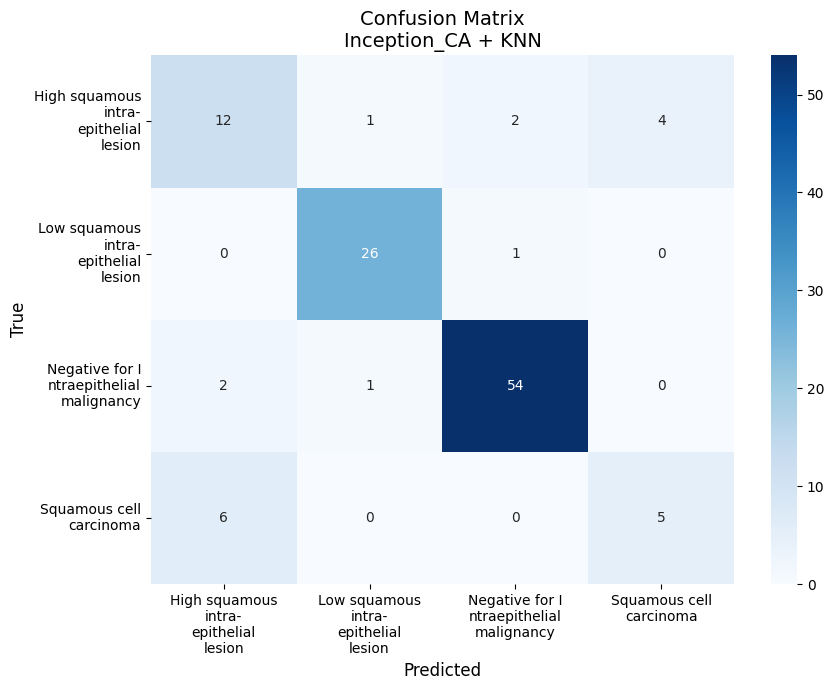

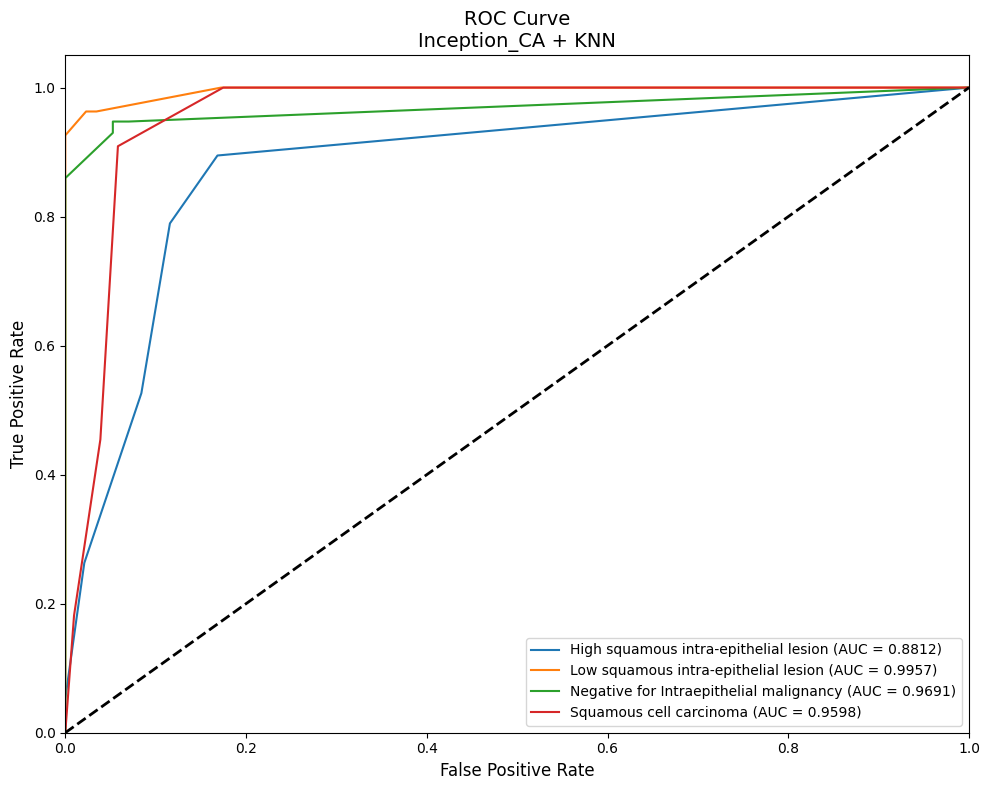


--- Inception_CA + MLP ---
Test Accuracy       : 0.798246
Meta training time  : 0.496922 s
Test time per image : 0.000008 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.481481  0.684211  0.565217        19
   Low squamous intra-epithelial lesion   0.794118  1.000000  0.885246        27
Negative for Intraepithelial malignancy   0.980769  0.894737  0.935780        57
                Squamous cell carcinoma   0.000000  0.000000  0.000000        11

                               accuracy                       0.798246       114
                              macro avg   0.564092  0.644737  0.596561       114
                           weighted avg   0.758712  0.798246  0.771756       114



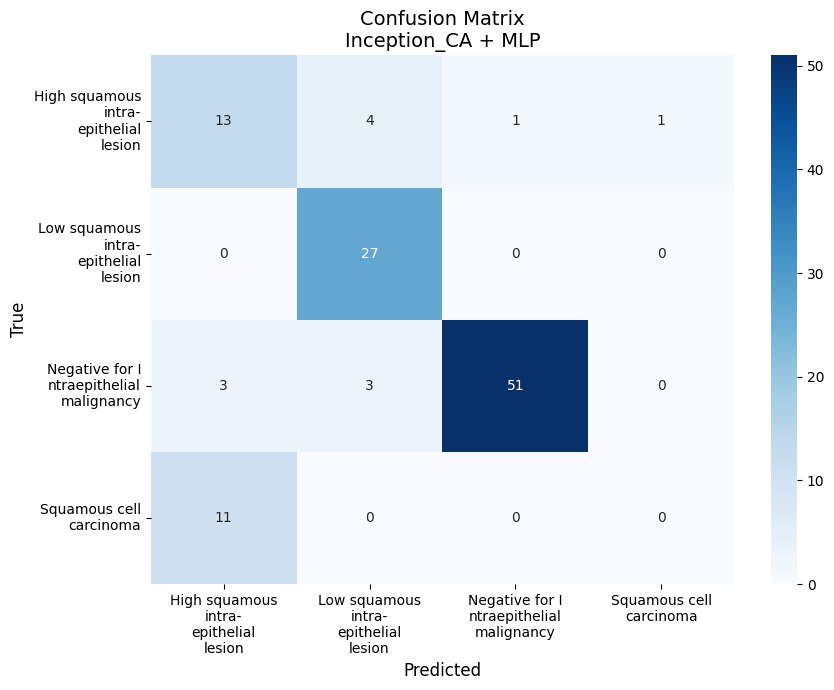

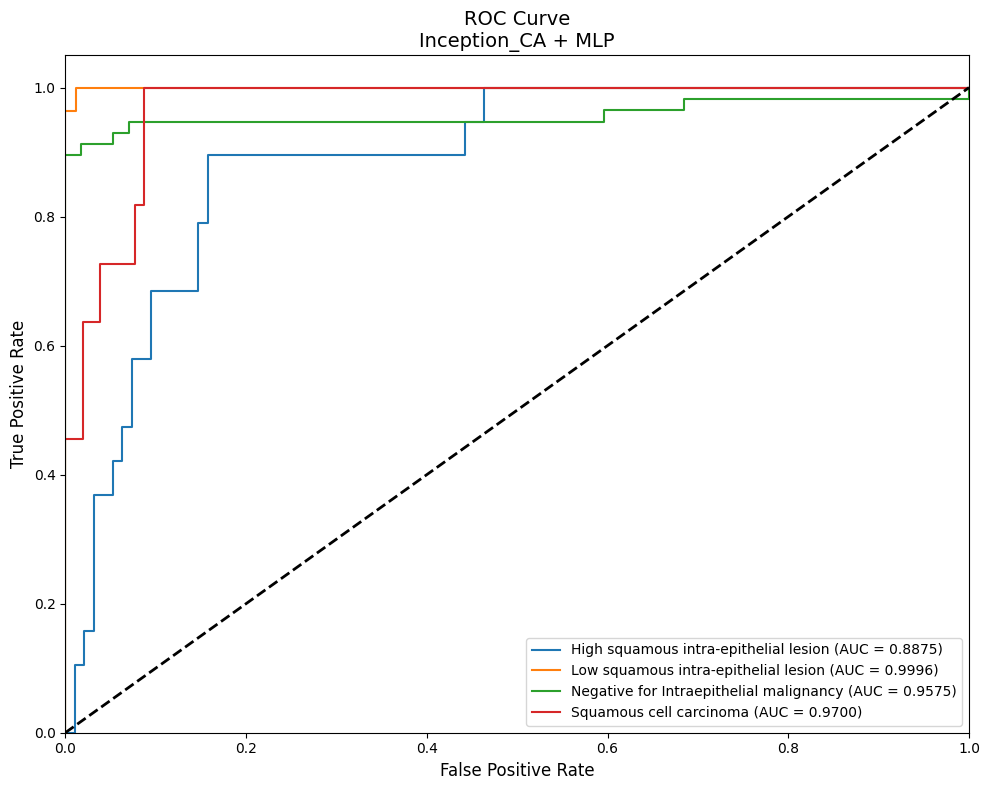


--- Inception_CA + RandomForest ---
Test Accuracy       : 0.807018
Meta training time  : 0.564174 s
Test time per image : 0.001156 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.550000  0.578947  0.564103        19
   Low squamous intra-epithelial lesion   0.771429  1.000000  0.870968        27
Negative for Intraepithelial malignancy   1.000000  0.894737  0.944444        57
                Squamous cell carcinoma   0.375000  0.272727  0.315789        11

                               accuracy                       0.807018       114
                              macro avg   0.674107  0.686603  0.673826       114
                           weighted avg   0.810558  0.807018  0.802992       114



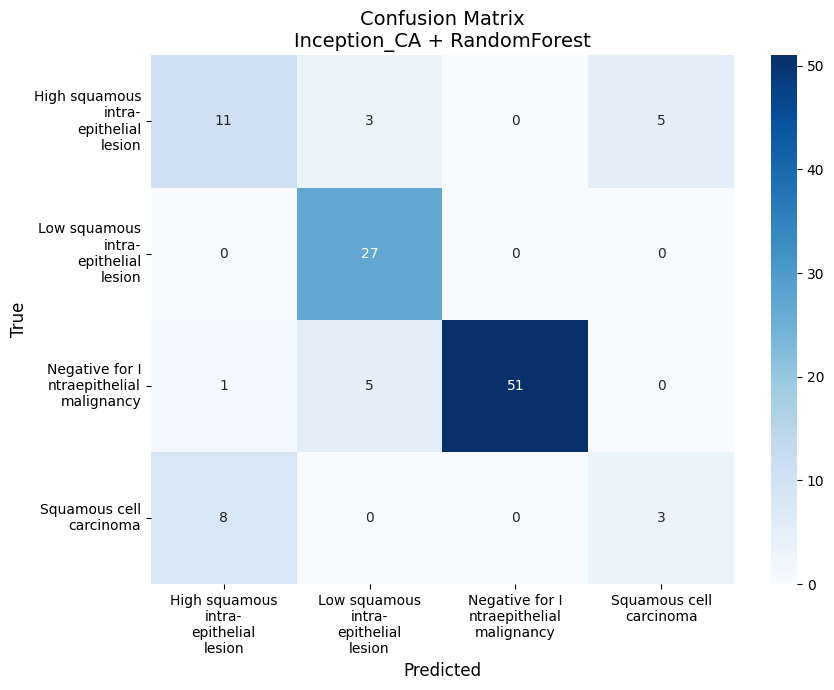

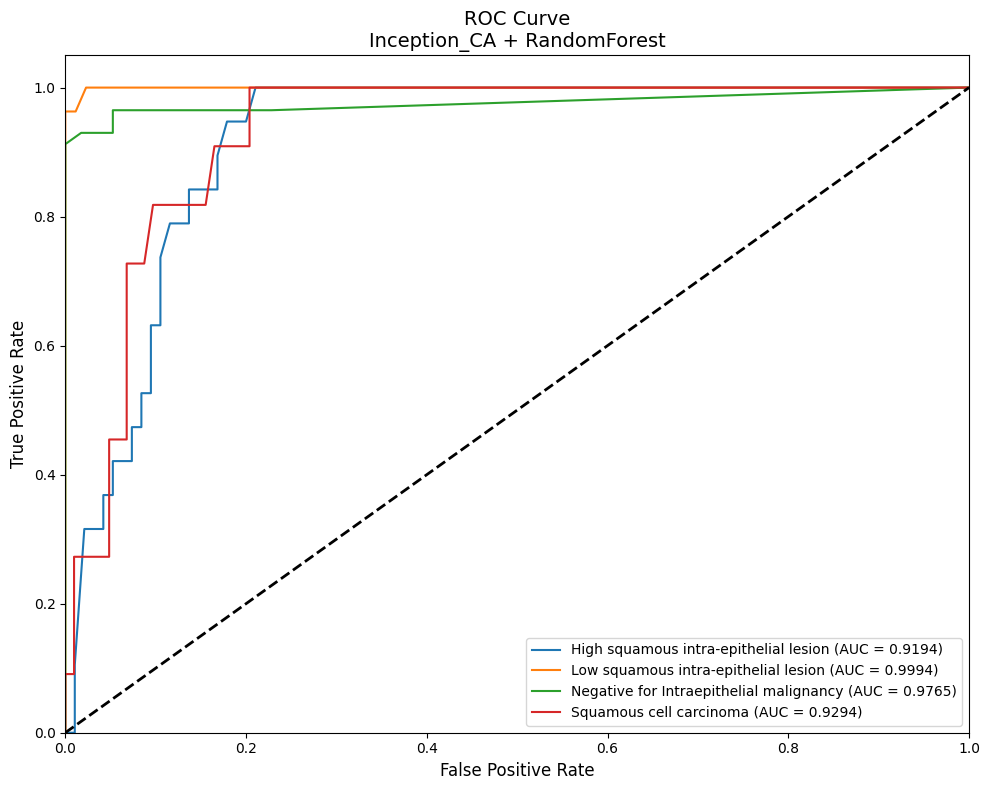


--- Inception_CA + CatBoost ---
Test Accuracy       : 0.780702
Meta training time  : 0.308667 s
Test time per image : 0.000018 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.555556  0.526316  0.540541        19
   Low squamous intra-epithelial lesion   0.729730  1.000000  0.843750        27
Negative for Intraepithelial malignancy   1.000000  0.842105  0.914286        57
                Squamous cell carcinoma   0.363636  0.363636  0.363636        11

                               accuracy                       0.780702       114
                              macro avg   0.662230  0.683014  0.665553       114
                           weighted avg   0.800511  0.780702  0.782156       114



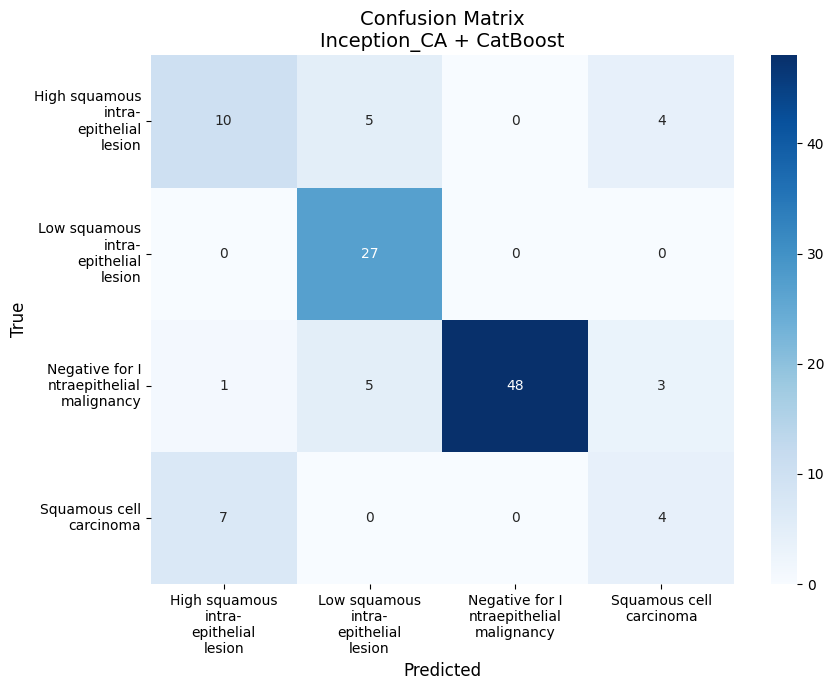

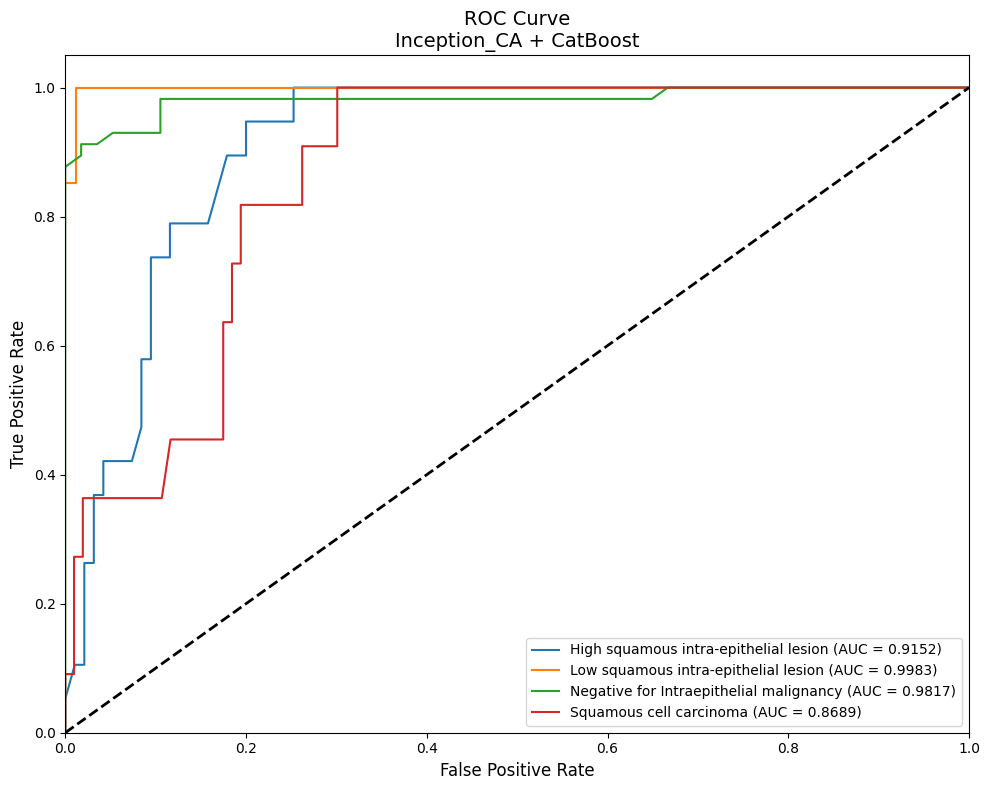

In [55]:
run_meta_classifiers("Inception_CA", show_plots=True)

### MobileNet_ca

MobileNet_CA + Meta-Classifiers (base accuracy on test: 0.798246)

--- MobileNet_CA + KNN ---
Test Accuracy       : 0.815789
Meta training time  : 0.001299 s
Test time per image : 0.000040 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.700000  0.368421  0.482759        19
   Low squamous intra-epithelial lesion   0.833333  0.925926  0.877193        27
Negative for Intraepithelial malignancy   0.945455  0.912281  0.928571        57
                Squamous cell carcinoma   0.473684  0.818182  0.600000        11

                               accuracy                       0.815789       114
                              macro avg   0.738118  0.756202  0.722131       114
                           weighted avg   0.832469  0.815789  0.810396       114



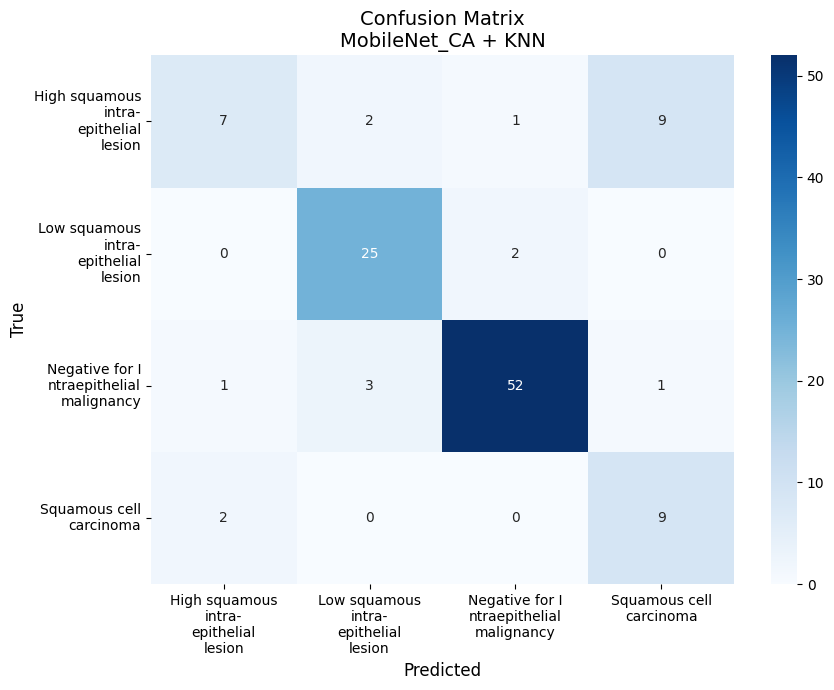

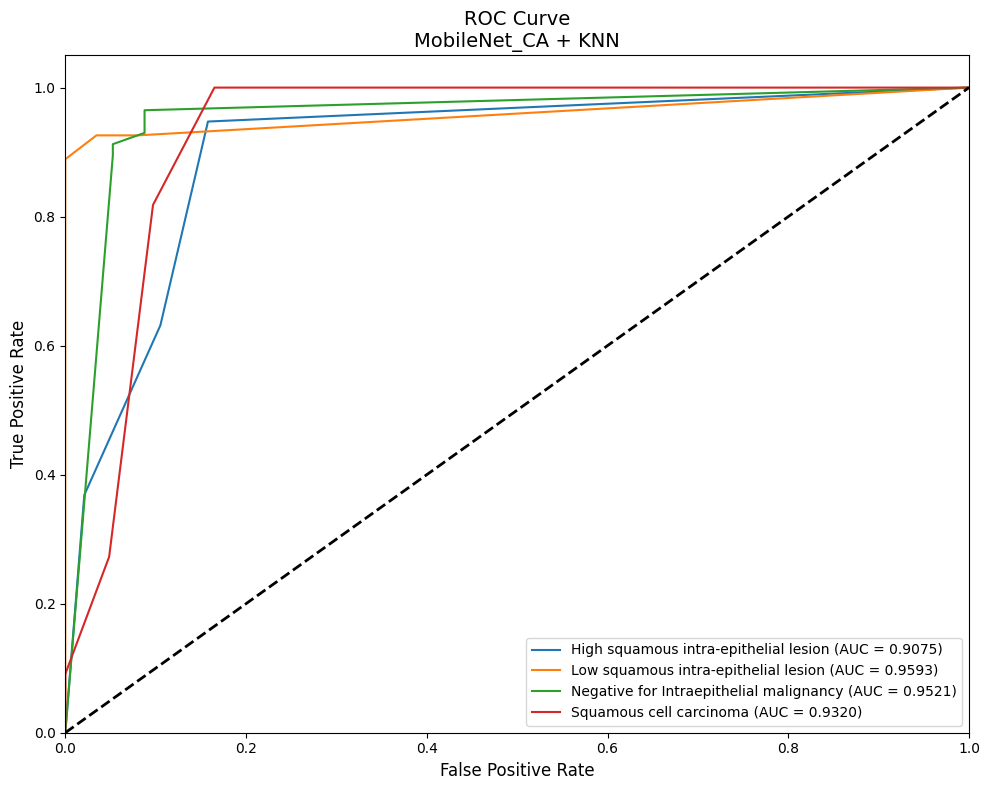


--- MobileNet_CA + MLP ---
Test Accuracy       : 0.763158
Meta training time  : 1.108539 s
Test time per image : 0.000007 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.352941  0.315789  0.333333        19
   Low squamous intra-epithelial lesion   1.000000  0.851852  0.920000        27
Negative for Intraepithelial malignancy   0.925926  0.877193  0.900901        57
                Squamous cell carcinoma   0.400000  0.727273  0.516129        11

                               accuracy                       0.763158       114
                              macro avg   0.669717  0.693027  0.667591       114
                           weighted avg   0.797225  0.763158  0.773703       114



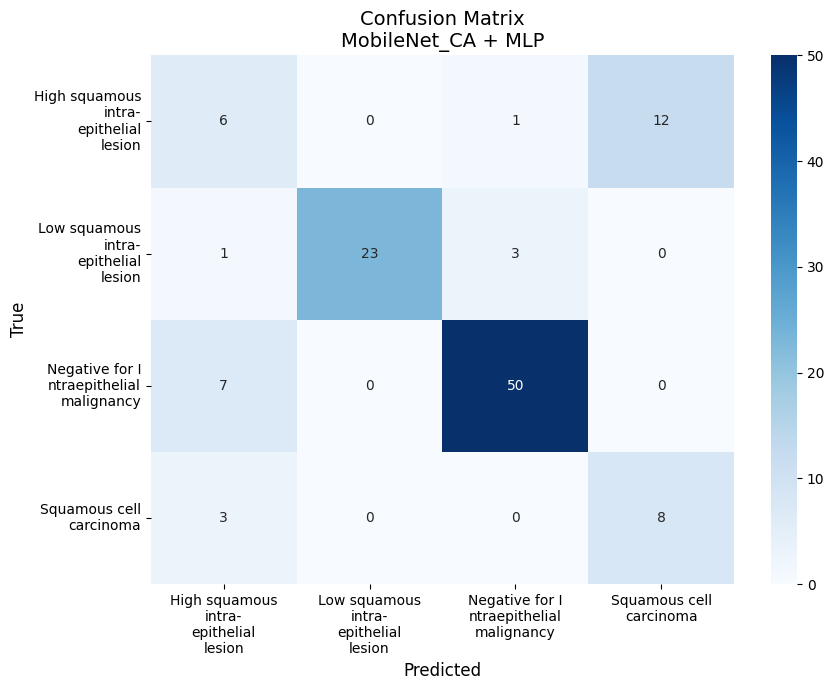

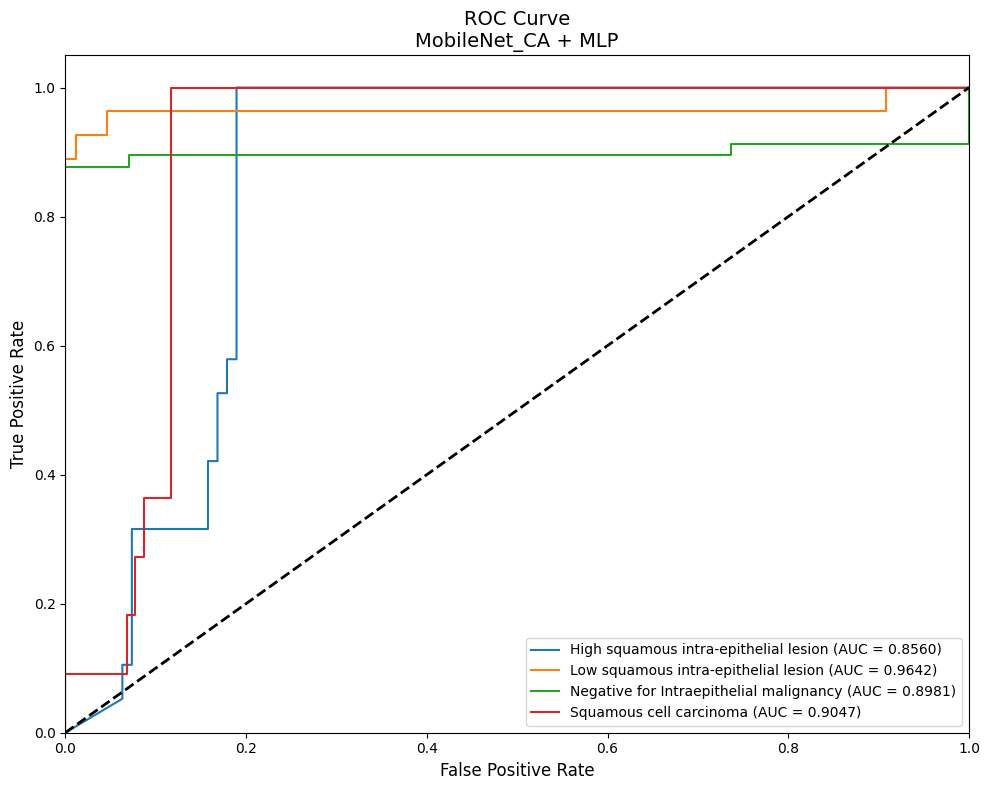


--- MobileNet_CA + RandomForest ---
Test Accuracy       : 0.798246
Meta training time  : 0.539696 s
Test time per image : 0.001095 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.714286  0.263158  0.384615        19
   Low squamous intra-epithelial lesion   0.781250  0.925926  0.847458        27
Negative for Intraepithelial malignancy   0.944444  0.894737  0.918919        57
                Squamous cell carcinoma   0.476190  0.909091  0.625000        11

                               accuracy                       0.798246       114
                              macro avg   0.729043  0.748228  0.693998       114
                           weighted avg   0.822251  0.798246  0.784583       114



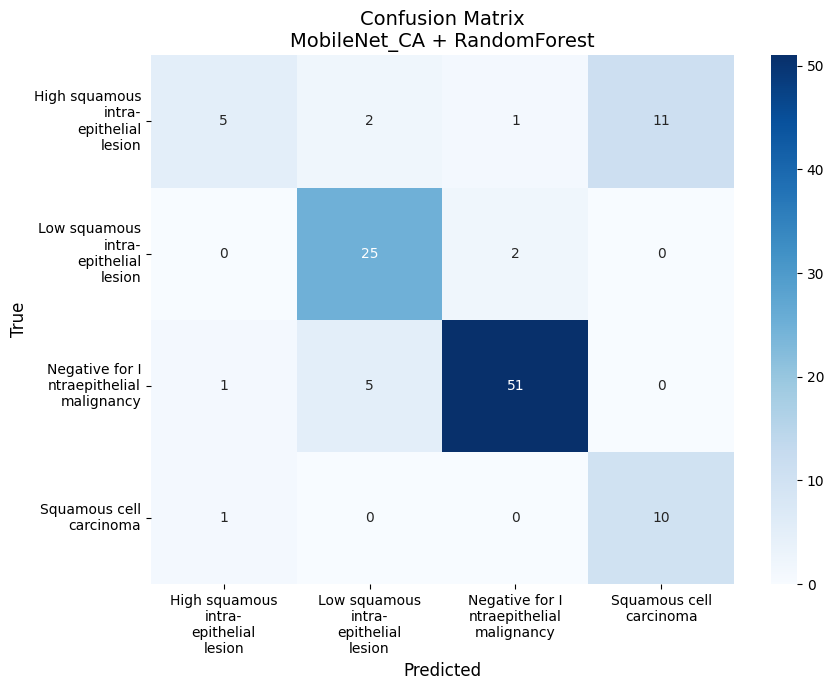

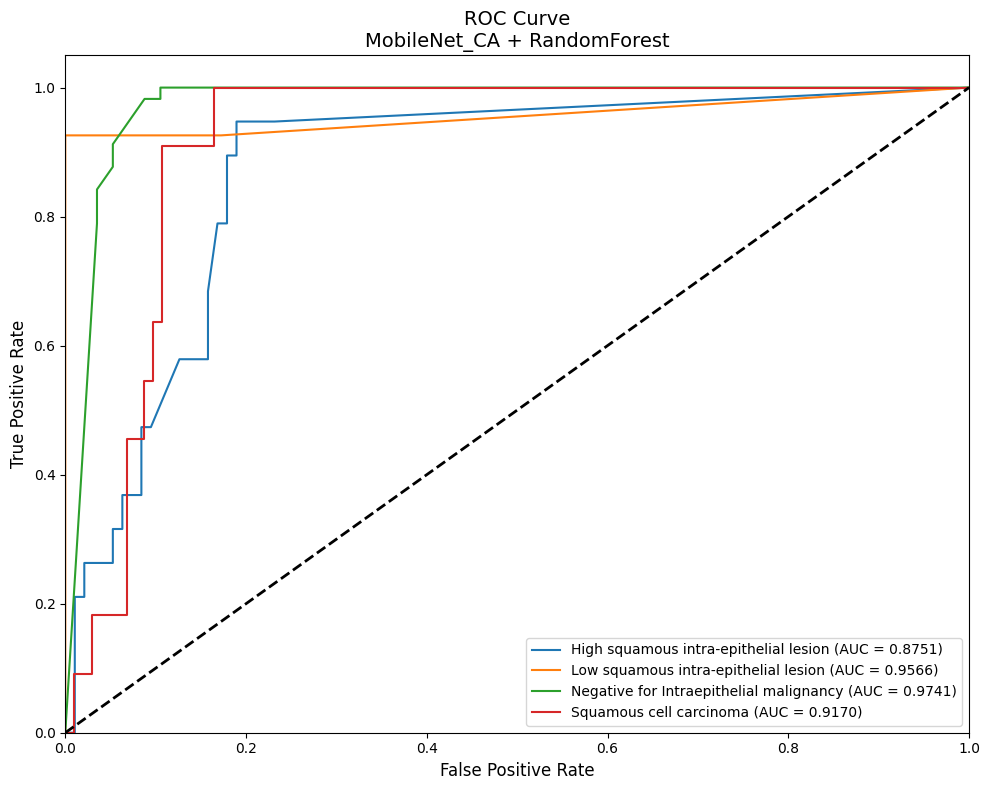


--- MobileNet_CA + CatBoost ---
Test Accuracy       : 0.798246
Meta training time  : 0.302649 s
Test time per image : 0.000017 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.333333  0.105263  0.160000        19
   Low squamous intra-epithelial lesion   1.000000  0.925926  0.961538        27
Negative for Intraepithelial malignancy   0.870968  0.947368  0.907563        57
                Squamous cell carcinoma   0.476190  0.909091  0.625000        11

                               accuracy                       0.798246       114
                              macro avg   0.670123  0.721912  0.663525       114
                           weighted avg   0.773830  0.798246  0.768488       114



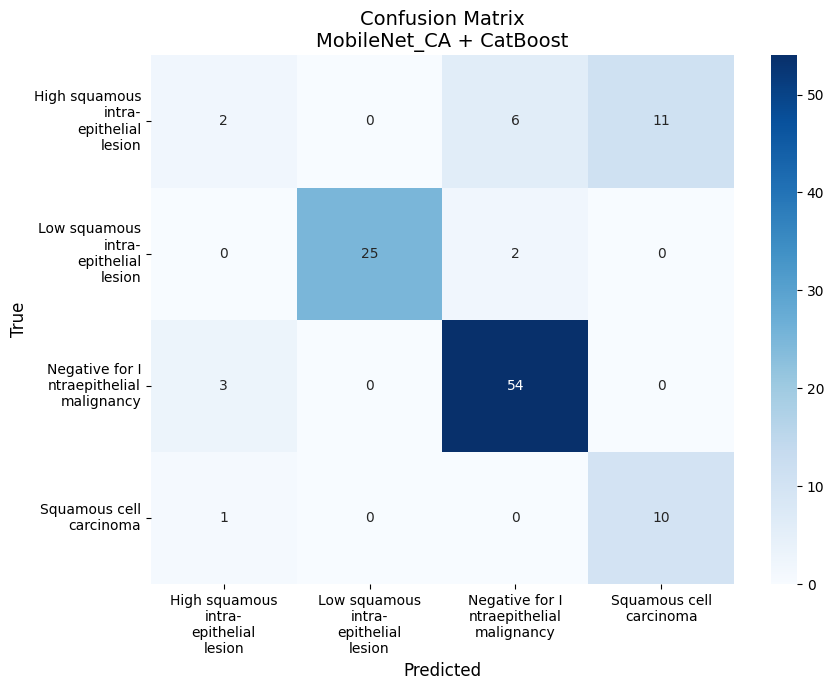

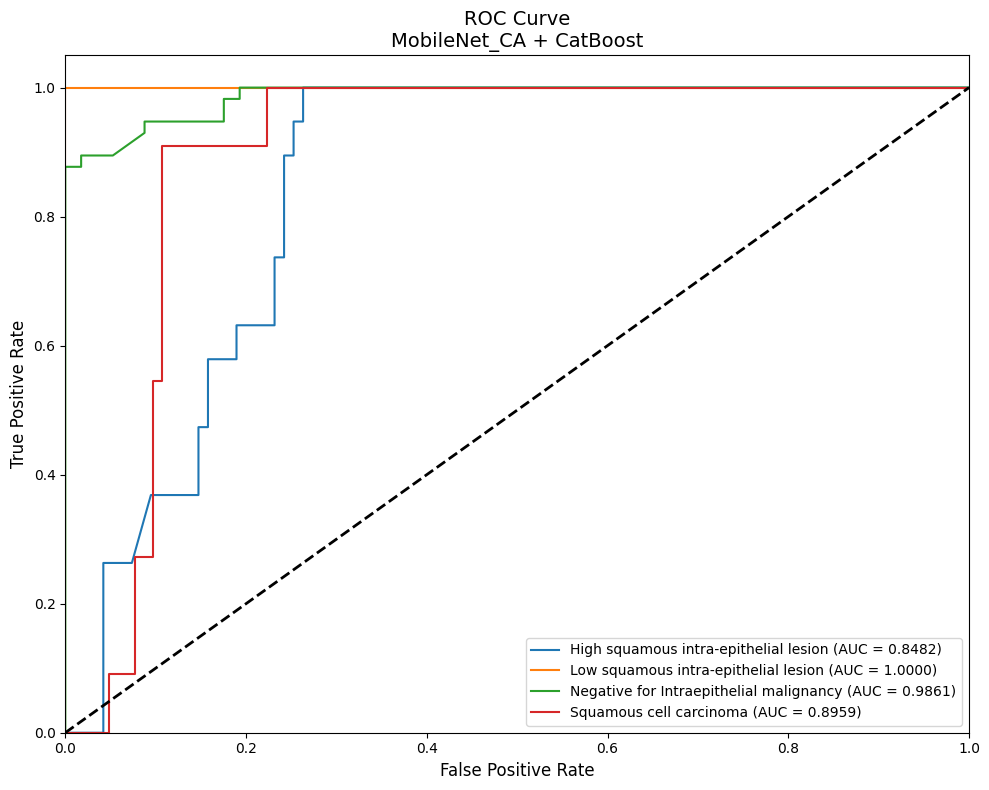

In [56]:
run_meta_classifiers("MobileNet_CA", show_plots=True)

## Stacked ensembles

In [57]:
def fit_stacked_ensemble(members):
    X_meta_val = np.hstack([val_predictions[name] for name in members])
    X_meta_test = np.hstack([test_predictions[name] for name in members])

    meta = LogisticRegression(max_iter=2000, random_state=42)
    meta.fit(X_meta_val, y_val_classes)

    start = time.time()
    probs = meta.predict_proba(X_meta_test)
    time_per_image = (time.time() - start) / len(X_test)
    return probs, time_per_image


cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)


def val_cv_accuracy(members):
    X_meta_val = np.hstack([val_predictions[name] for name in members])
    oof_pred = cross_val_predict(LogisticRegression(max_iter=2000, random_state=42),
                                 X_meta_val, y_val_classes, cv=cv, groups=groups_val)
    return accuracy_score(y_val_classes, oof_pred)

### All combinations of the CA models

In [58]:
ensemble_results = {}

for r in range(2, len(ca_models) + 1):
    for combo in combinations(ca_models, r):
        probs, _ = fit_stacked_ensemble(combo)
        ensemble_results[" + ".join(combo)] = {
            "size": r,
            "val_cv_accuracy": val_cv_accuracy(combo),
            "test_accuracy": accuracy_score(y_test_classes, np.argmax(probs, axis=1)),
            "predictions": probs,
        }

# rank by test accuracy (ties go to the smaller ensemble)
ranked = sorted(ensemble_results.items(), key=lambda x: (-x[1]["test_accuracy"], x[1]["size"]))
ensemble_rank = {name: i for i, (name, _) in enumerate(ranked, 1)}

print(f"{len(ensemble_results)} ensembles evaluated\n")
print("Top 10 ensembles (ranked by validation CV accuracy)")
print(f"{'':4s}{'Ensemble':75s}  {'Val CV Acc':>10s}  {'Test Acc':>10s}")
print("-" * 105)
for i, (name, data) in enumerate(ranked[:10], 1):
    print(f"{i:2d}. {name:75s}  {data['val_cv_accuracy']:10.6f}  {data['test_accuracy']:10.6f}")

best_name, best_data = ranked[0]
print("\n" + "=" * 90)
print(f"SELECTED ENSEMBLE (by test): {best_name}")
print(f"Val CV Accuracy : {best_data['val_cv_accuracy']:.6f}")
print(f"Test Accuracy   : {best_data['test_accuracy']:.6f}")
print("=" * 90)
print(classification_report(y_test_classes, np.argmax(best_data["predictions"], axis=1),
                            target_names=class_names, digits=4))

120 ensembles evaluated

Top 10 ensembles (ranked by validation CV accuracy)
    Ensemble                                                                     Val CV Acc    Test Acc
---------------------------------------------------------------------------------------------------------
 1. ResNet50_CA + Xception_CA                                                      0.513761    0.903509
 2. ResNet50_CA + Inception_CA                                                     0.513761    0.903509
 3. ResNet50_CA + MobileNet_CA + Xception_CA                                       0.513761    0.903509
 4. ResNet50_CA + Xception_CA + Inception_CA                                       0.513761    0.903509
 5. VGG19_CA + ResNet50_CA + Xception_CA + Inception_CA                            0.513761    0.903509
 6. ResNet50_CA + MobileNet_CA + Xception_CA + Inception_CA                        0.513761    0.903509
 7. VGG19_CA + ResNet50_CA + MobileNet_CA + Xception_CA + Inception_CA             0.5137

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [59]:
def evaluate_pair_ensemble(members):
    name = " + ".join(members)
    probs, time_per_image = fit_stacked_ensemble(members)
    y_pred = np.argmax(probs, axis=1)

    print(f"Stacked Ensemble: {name}")
    print(f"Val CV Accuracy     : {ensemble_results[name]['val_cv_accuracy']:.6f} ")
    print(f"Test Accuracy       : {accuracy_score(y_test_classes, y_pred):.6f}"
          f"(rank {ensemble_rank[name]} of {len(ensemble_results)})")
    print(f"Test time per image : {time_per_image:.6f} s")
    print("\nClassification Report:")
    print(classification_report(y_test_classes, y_pred, target_names=class_names, digits=6))

    save_name = "Ensemble_" + "_".join(members)
    plot_confusion_matrix(y_test_classes, y_pred, f'Ensemble: {name}', save_name)
    plot_roc_curves(y_test, probs, f'Ensemble: {name}', save_name)

#### Xception_CA + ResNet50_CA

Stacked Ensemble: ResNet50_CA + Xception_CA
Val CV Accuracy     : 0.513761 
Test Accuracy       : 0.903509(rank 1 of 120)
Test time per image : 0.000004 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.633333  1.000000  0.775510        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   1.000000  1.000000  1.000000        57
                Squamous cell carcinoma   0.000000  0.000000  0.000000        11

                               accuracy                       0.903509       114
                              macro avg   0.658333  0.750000  0.693878       114
                           weighted avg   0.842398  0.903509  0.866094       114



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


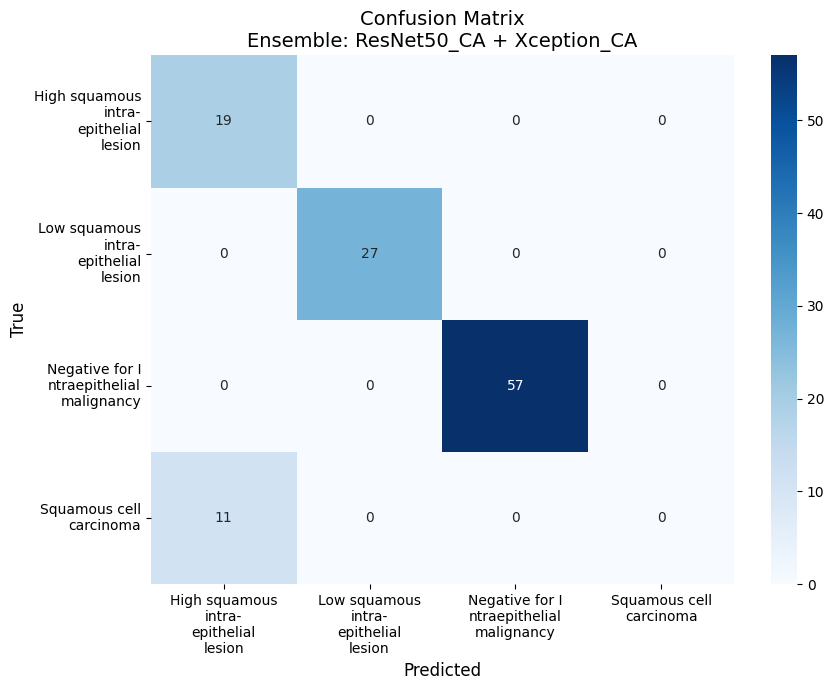

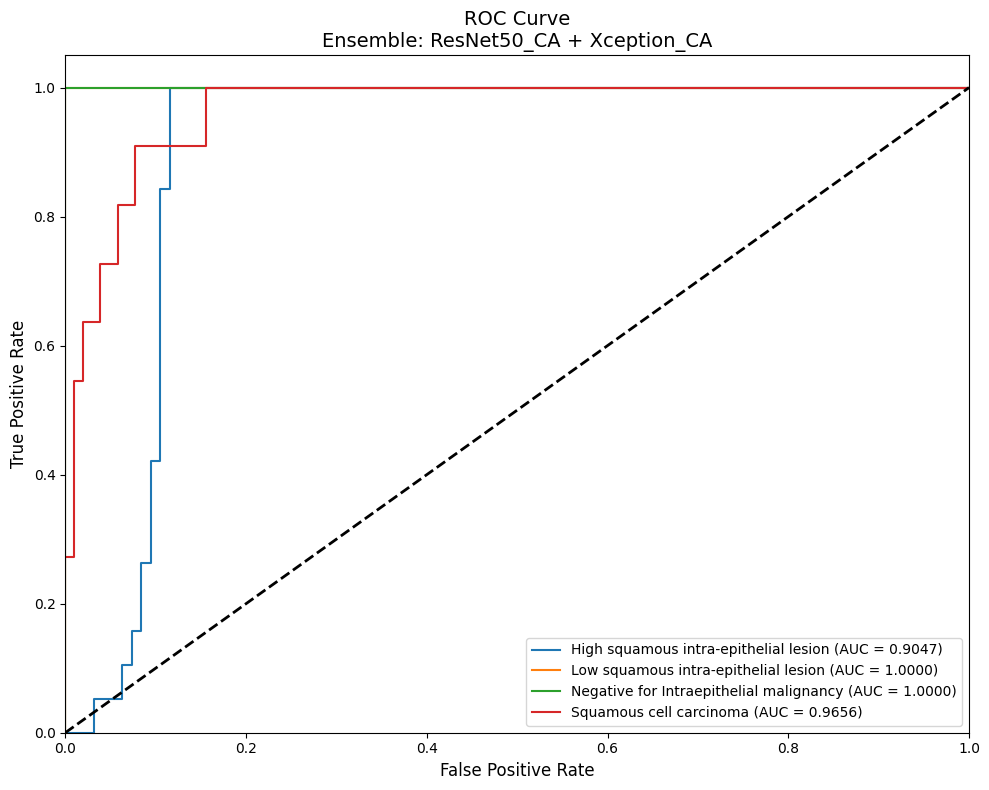

In [60]:
evaluate_pair_ensemble(['ResNet50_CA', 'Xception_CA'])

#### Inception_CA + ResNet50_CA

Stacked Ensemble: ResNet50_CA + Inception_CA
Val CV Accuracy     : 0.513761 
Test Accuracy       : 0.903509(rank 2 of 120)
Test time per image : 0.000005 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.633333  1.000000  0.775510        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   1.000000  1.000000  1.000000        57
                Squamous cell carcinoma   0.000000  0.000000  0.000000        11

                               accuracy                       0.903509       114
                              macro avg   0.658333  0.750000  0.693878       114
                           weighted avg   0.842398  0.903509  0.866094       114



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


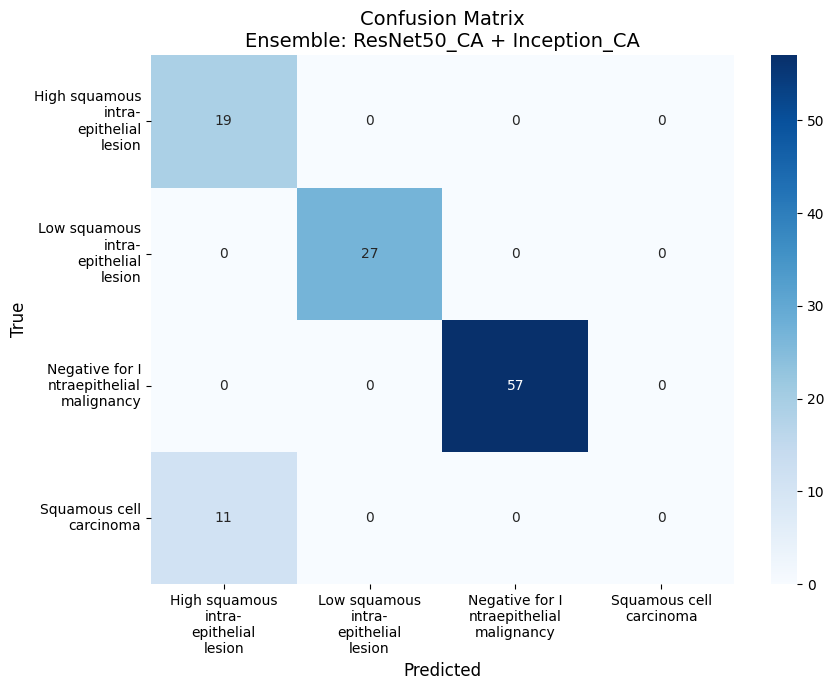

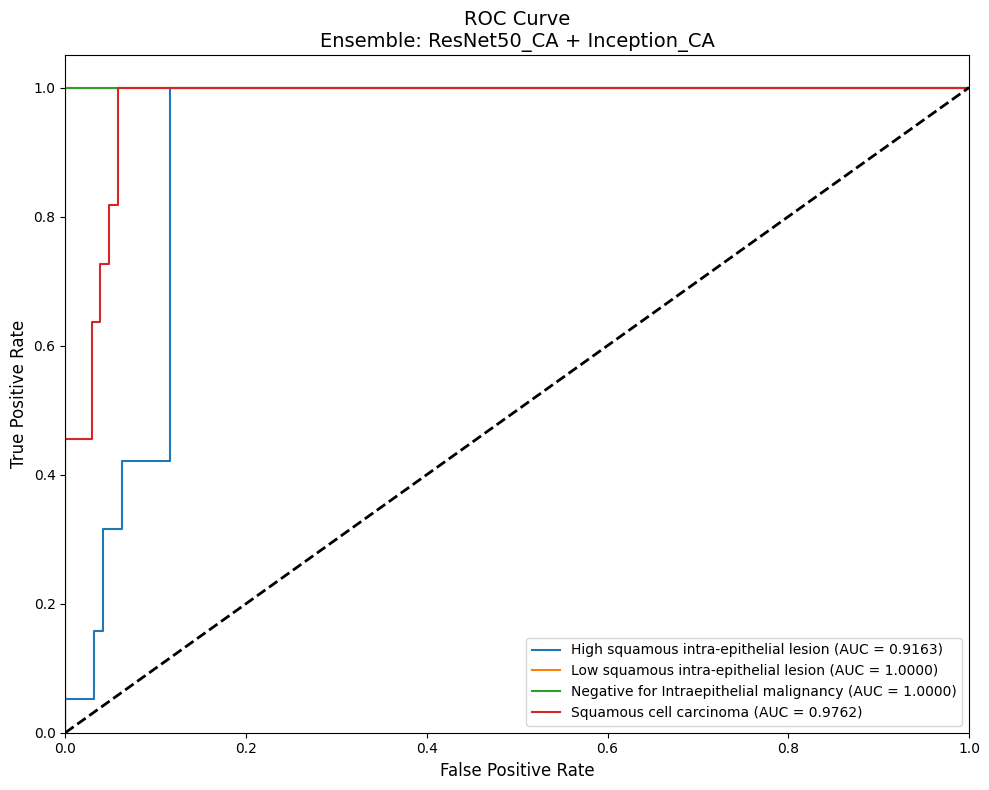

In [61]:
evaluate_pair_ensemble(['ResNet50_CA', 'Inception_CA'])

#### ResNet50_CA + MobileNet_CA + Xception_CA 

Stacked Ensemble: ResNet50_CA + MobileNet_CA + Xception_CA
Val CV Accuracy     : 0.513761 
Test Accuracy       : 0.903509(rank 3 of 120)
Test time per image : 0.000005 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.633333  1.000000  0.775510        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   1.000000  1.000000  1.000000        57
                Squamous cell carcinoma   0.000000  0.000000  0.000000        11

                               accuracy                       0.903509       114
                              macro avg   0.658333  0.750000  0.693878       114
                           weighted avg   0.842398  0.903509  0.866094       114



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


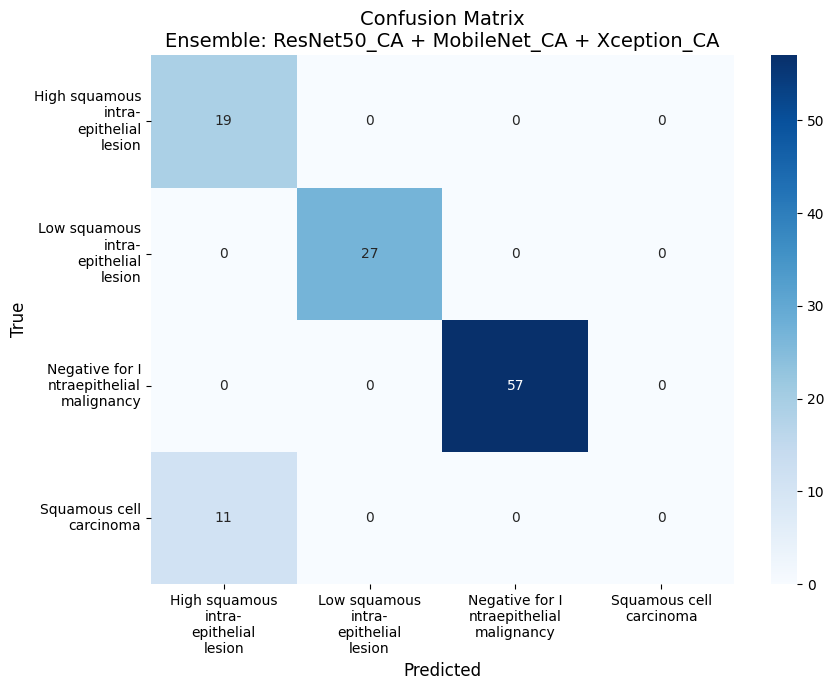

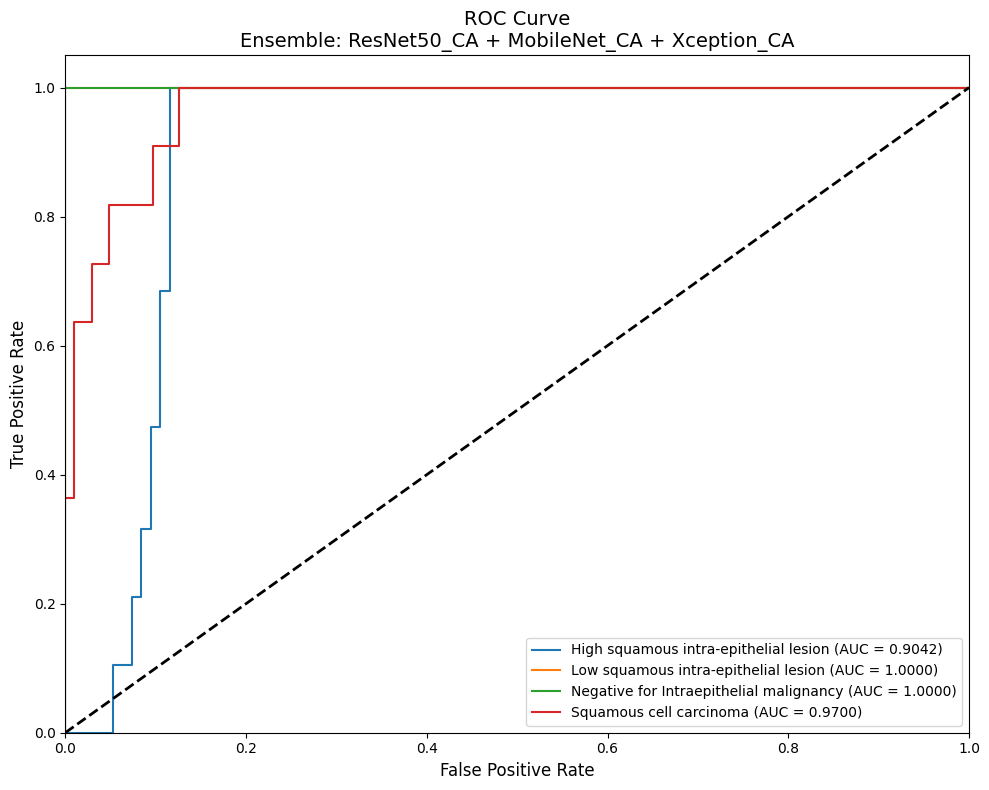

In [69]:
evaluate_pair_ensemble(['ResNet50_CA', 'MobileNet_CA','Xception_CA'])

#### ResNet50_CA + Xception_CA + Inception_CA   

Stacked Ensemble: ResNet50_CA + Xception_CA + Inception_CA
Val CV Accuracy     : 0.513761 
Test Accuracy       : 0.903509(rank 4 of 120)
Test time per image : 0.000005 s

Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.633333  1.000000  0.775510        19
   Low squamous intra-epithelial lesion   1.000000  1.000000  1.000000        27
Negative for Intraepithelial malignancy   1.000000  1.000000  1.000000        57
                Squamous cell carcinoma   0.000000  0.000000  0.000000        11

                               accuracy                       0.903509       114
                              macro avg   0.658333  0.750000  0.693878       114
                           weighted avg   0.842398  0.903509  0.866094       114



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


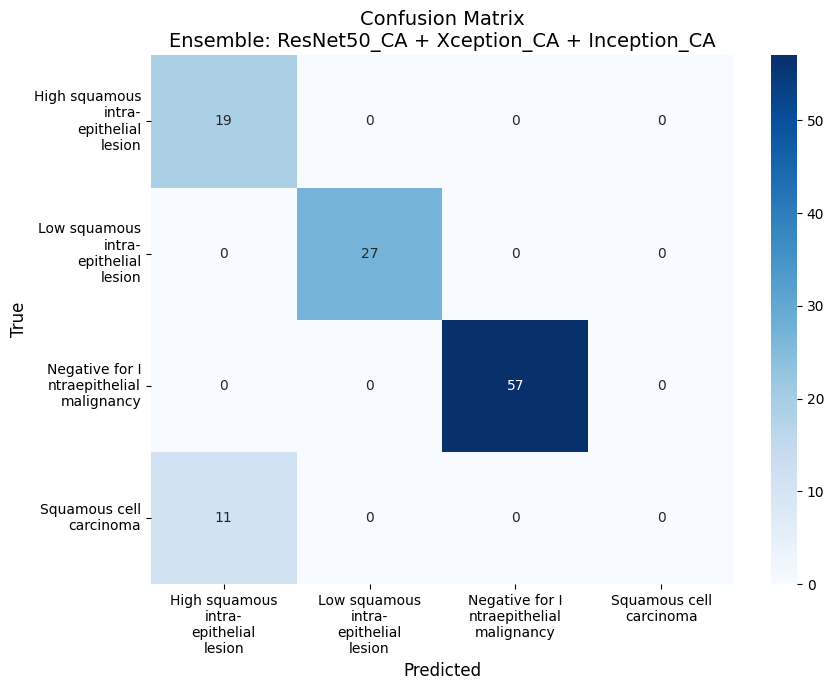

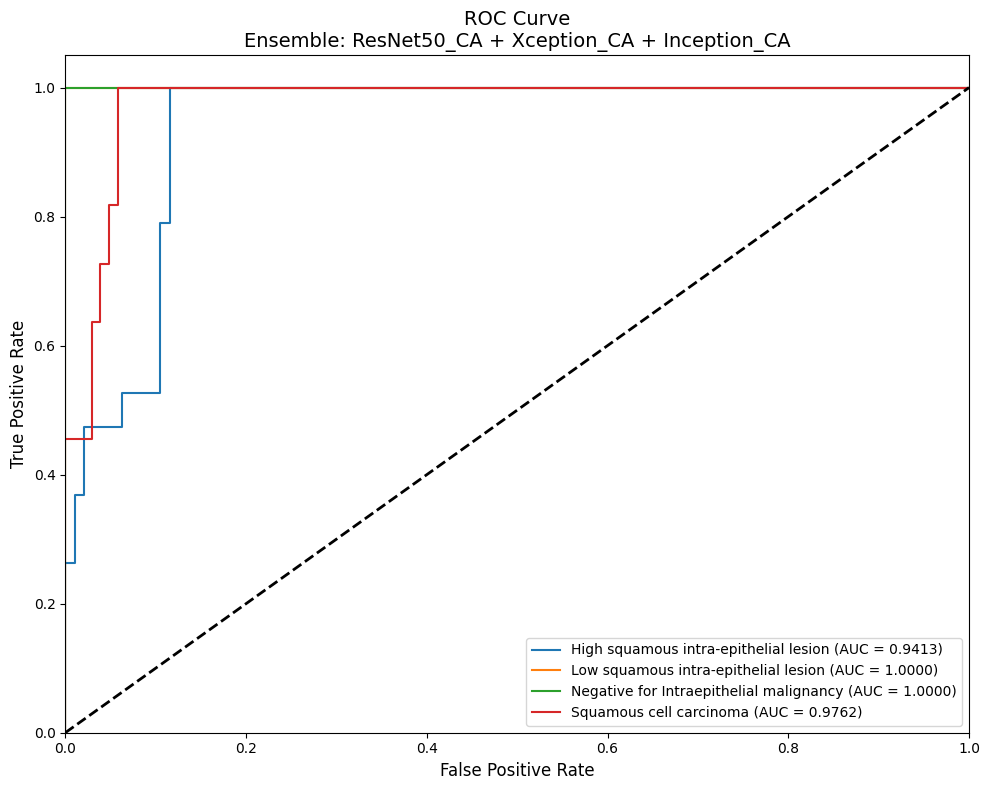

In [70]:
evaluate_pair_ensemble(['ResNet50_CA','Xception_CA', 'Inception_CA'])

## silhouette scores 

In [62]:
embedding_models = [name for name in model_info if name.endswith(("_GAP", "_CA"))]


def to_feature_matrix(features):
    # the cluster attention block returns two outputs, in that case use the last one (the cluster vector)
    if isinstance(features, (list, tuple)):
        features = features[-1]
    return features.reshape(features.shape[0], -1)


silhouette_results, tsne_embeddings = {}, {}

for name in embedding_models:
    K.clear_session()
    model = load_cervical_model(name)

    print(f"\n{name}: last layers ->", [(l.name, type(l).__name__) for l in model.layers[-5:]])
    feature_layer = model.layers[-3]  # CHECK in the printout above that this is the intended feature layer for BOTH GAP and CA
    feature_model = Model(inputs=model.input, outputs=feature_layer.output)
    features = to_feature_matrix(feature_model.predict(X_test, batch_size=32, verbose=0))

    silhouette_results[name] = silhouette_score(features, y_test_classes)
    tsne_embeddings[name] = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(features)

    print(f"{name} (layer: {feature_layer.name}, features: {features.shape[1]}) "
          f"Silhouette Score: {silhouette_results[name]:.4f}")
    del model, feature_model, features


VGG16_GAP: last layers -> [('dense_8', 'Dense'), ('dropout_2', 'Dropout'), ('dense_9', 'Dense'), ('dropout_3', 'Dropout'), ('dense_10', 'Dense')]
VGG16_GAP (layer: dense_9, features: 512) Silhouette Score: 0.4310



VGG19_GAP: last layers -> [('dense_8', 'Dense'), ('dropout_2', 'Dropout'), ('dense_9', 'Dense'), ('dropout_3', 'Dropout'), ('dense_10', 'Dense')]
VGG19_GAP (layer: dense_9, features: 512) Silhouette Score: 0.4768



ResNet50_GAP: last layers -> [('dense_8', 'Dense'), ('dropout_2', 'Dropout'), ('dense_9', 'Dense'), ('dropout_3', 'Dropout'), ('dense_10', 'Dense')]
ResNet50_GAP (layer: dense_9, features: 512) Silhouette Score: 0.4846



MobileNet_GAP: last layers -> [('dense_8', 'Dense'), ('dropout_2', 'Dropout'), ('dense_9', 'Dense'), ('dropout_3', 'Dropout'), ('dense_10', 'Dense')]
MobileNet_GAP (layer: dense_9, features: 512) Silhouette Score: 0.3022



DenseNet_GAP: last layers -> [('dense_8', 'Dense'), ('dropout_2', 'Dropout'), ('dense_9', 'Dense'), ('dropout_3', 'Dropout'), ('dense_10', 'Dense')]
DenseNet_GAP (layer: dense_9, features: 512) Silhouette Score: 0.3112



Xception_GAP: last layers -> [('dense_8', 'Dense'), ('dropout_2', 'Dropout'), ('dense_9', 'Dense'), ('dropout_3', 'Dropout'), ('dense_10', 'Dense')]
Xception_GAP (layer: dense_9, features: 512) Silhouette Score: 0.3069


... (4 outputs left out)


MobileNet_CA: last layers -> [('dense_3', 'Dense'), ('dropout', 'Dropout'), ('dense_4', 'Dense'), ('dropout_1', 'Dropout'), ('dense_5', 'Dense')]
MobileNet_CA (layer: dense_4, features: 512) Silhouette Score: 0.4131



DenseNet_CA: last layers -> [('dense_3', 'Dense'), ('dropout', 'Dropout'), ('dense_4', 'Dense'), ('dropout_1', 'Dropout'), ('dense_5', 'Dense')]
DenseNet_CA (layer: dense_4, features: 512) Silhouette Score: 0.5018



Xception_CA: last layers -> [('dense_3', 'Dense'), ('dropout', 'Dropout'), ('dense_4', 'Dense'), ('dropout_1', 'Dropout'), ('dense_5', 'Dense')]
Xception_CA (layer: dense_4, features: 512) Silhouette Score: 0.4279



Inception_CA: last layers -> [('dense_3', 'Dense'), ('dropout', 'Dropout'), ('dense_4', 'Dense'), ('dropout_1', 'Dropout'), ('dense_5', 'Dense')]
Inception_CA (layer: dense_4, features: 512) Silhouette Score: 0.3901


In [63]:
rows = []
for name, score in silhouette_results.items():
    backbone, variant = name.rsplit("_", 1)
    rows.append({"Model": backbone, "Type": variant, "Silhouette Score": score})

silhouette_table = (pd.DataFrame(rows)
                    .pivot(index="Model", columns="Type", values="Silhouette Score")
                    [["GAP", "CA"]])

print("Silhouette Score Comparison Table\n")
print(silhouette_table.round(4))

Silhouette Score Comparison Table

Type          GAP      CA
Model                    
DenseNet   0.3112  0.5018
Inception  0.2251  0.3901
MobileNet  0.3022  0.4131
ResNet50   0.4846  0.6150
VGG16      0.4310  0.4639
VGG19      0.4768  0.6013
Xception   0.3069  0.4279


## t-SNE 

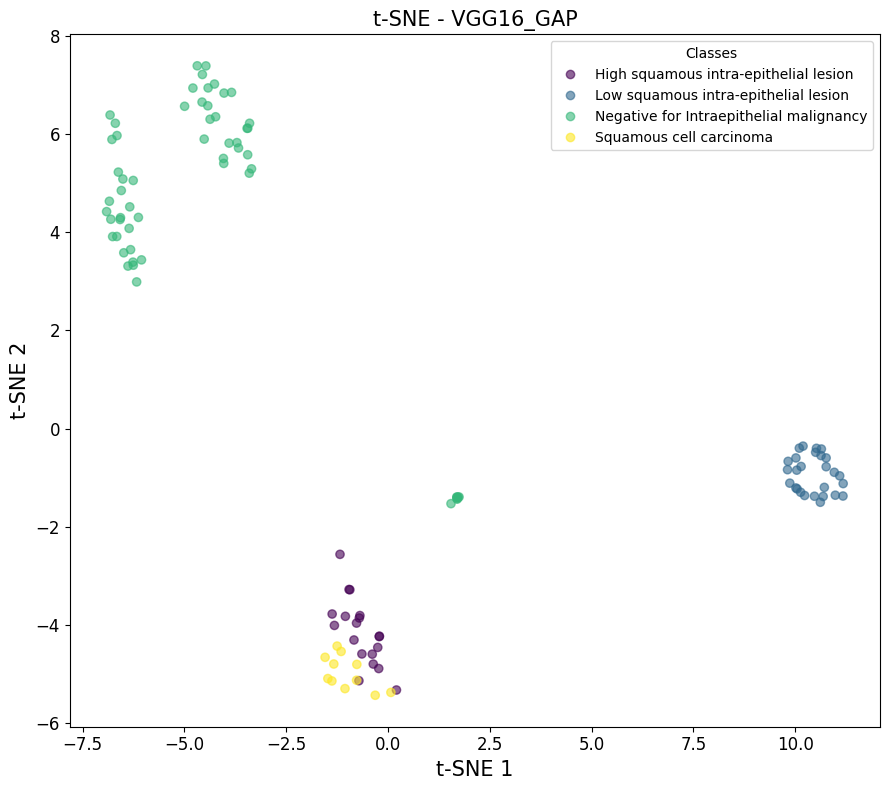

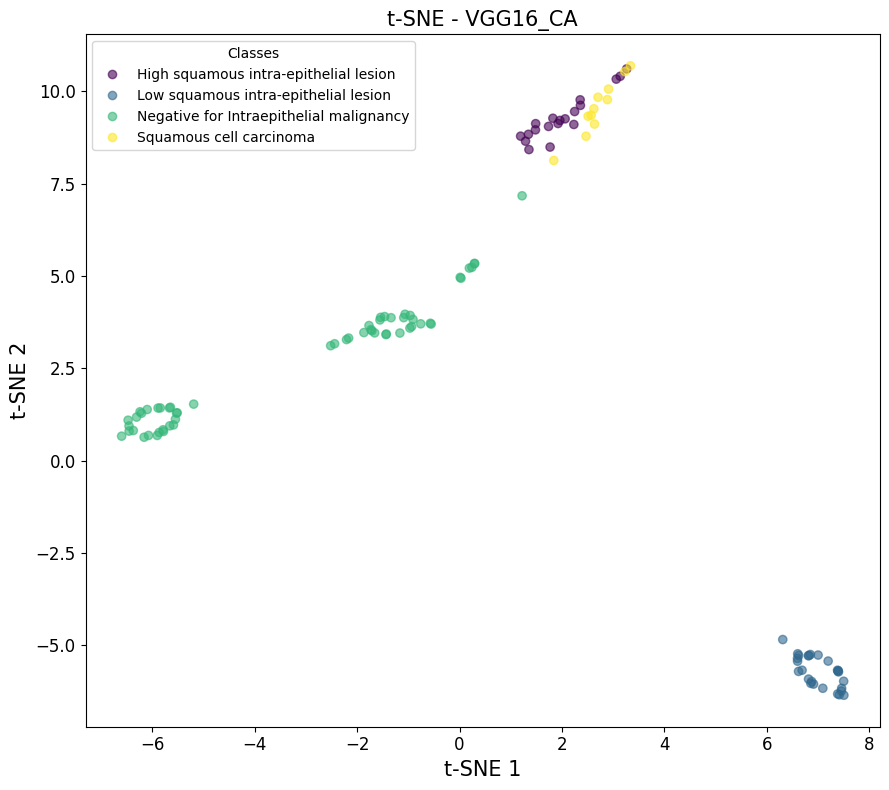

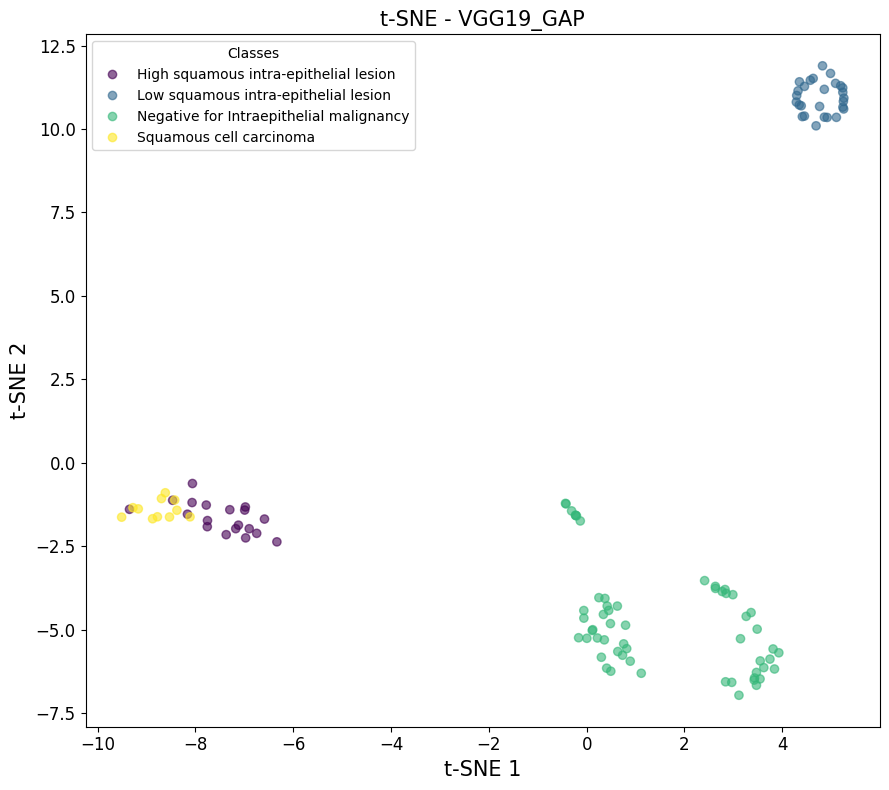

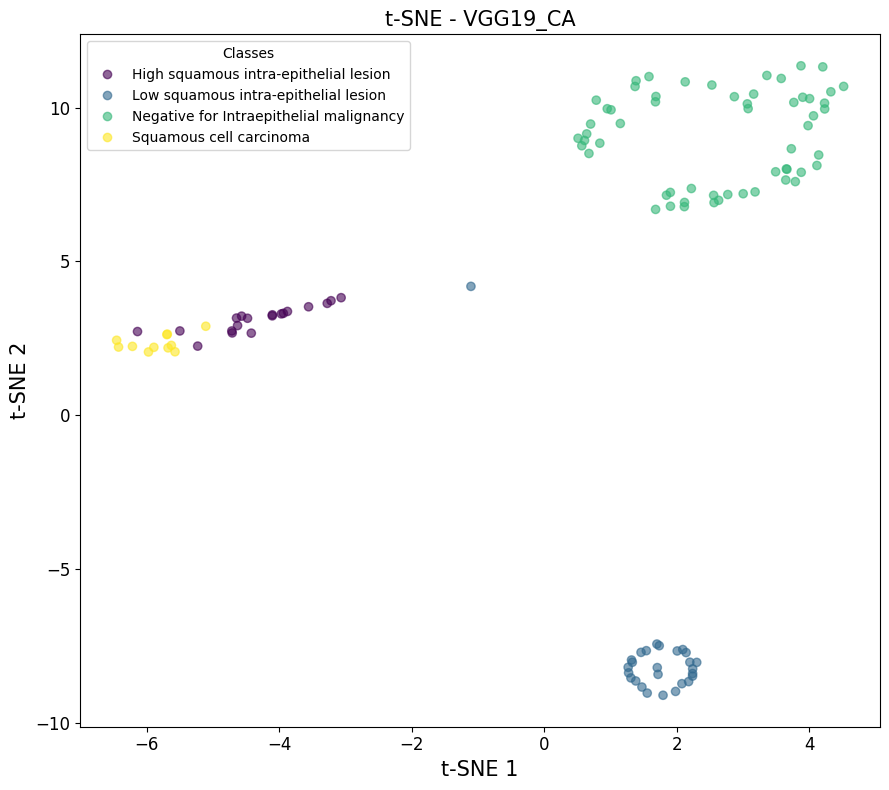

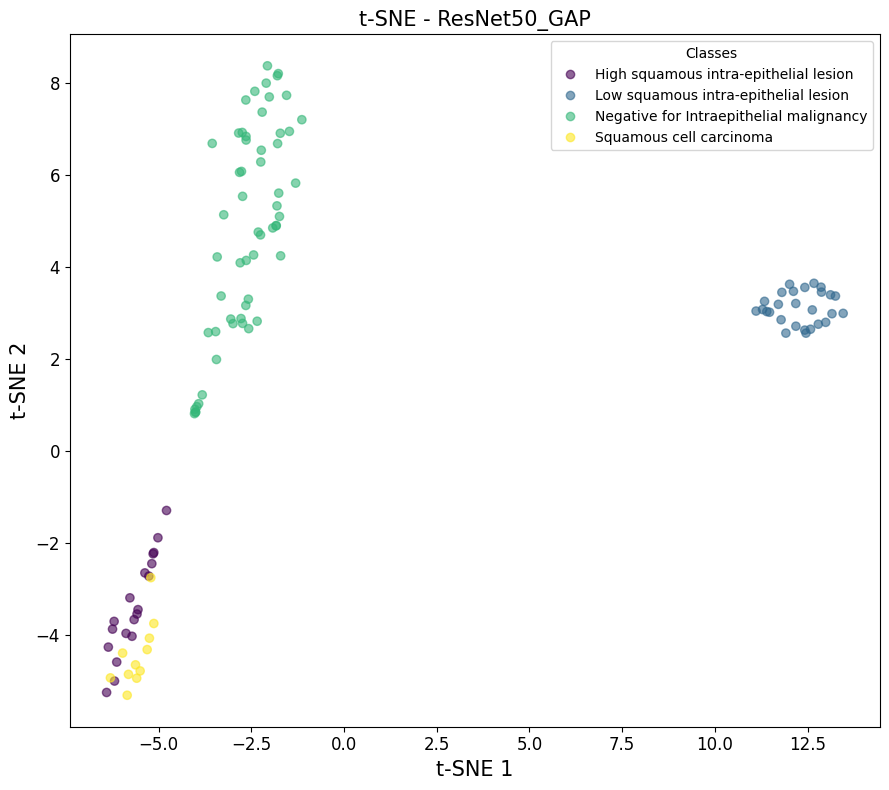

...

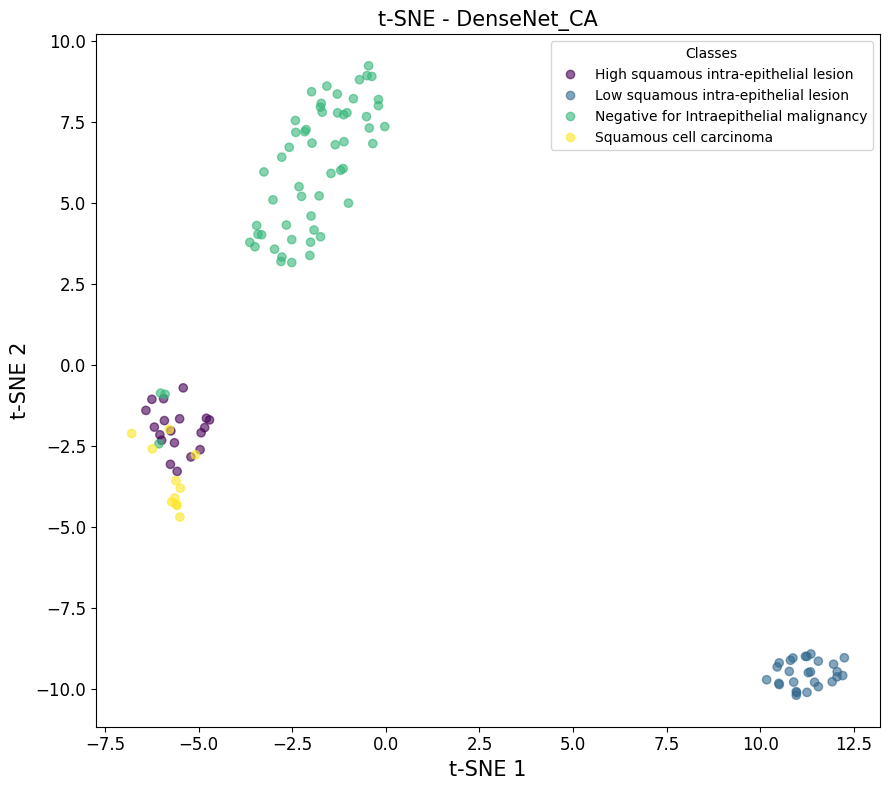

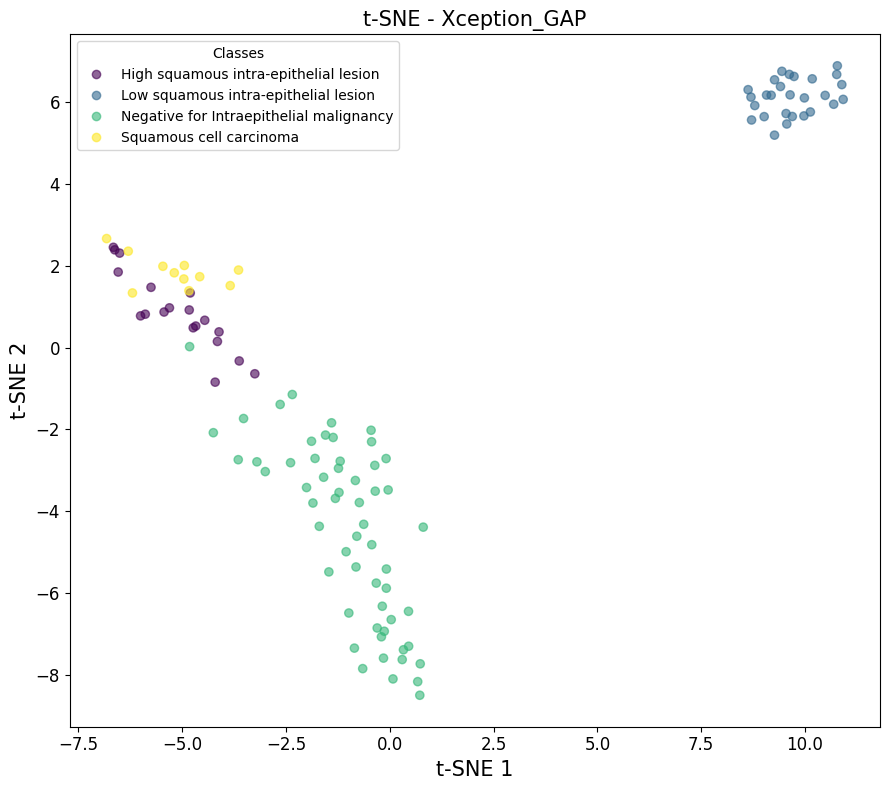

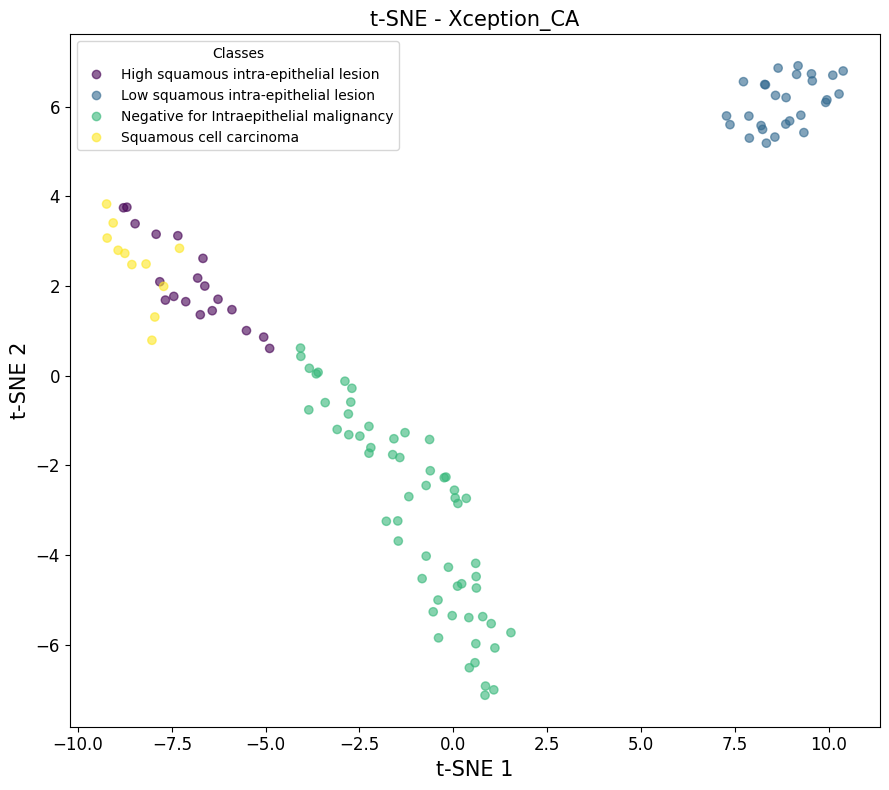

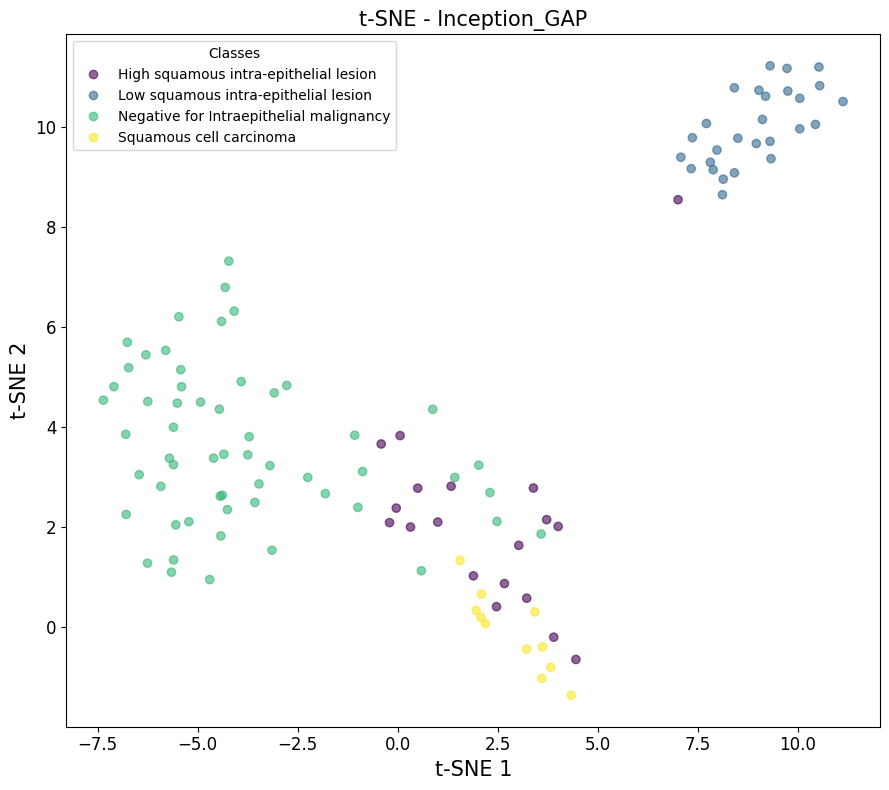

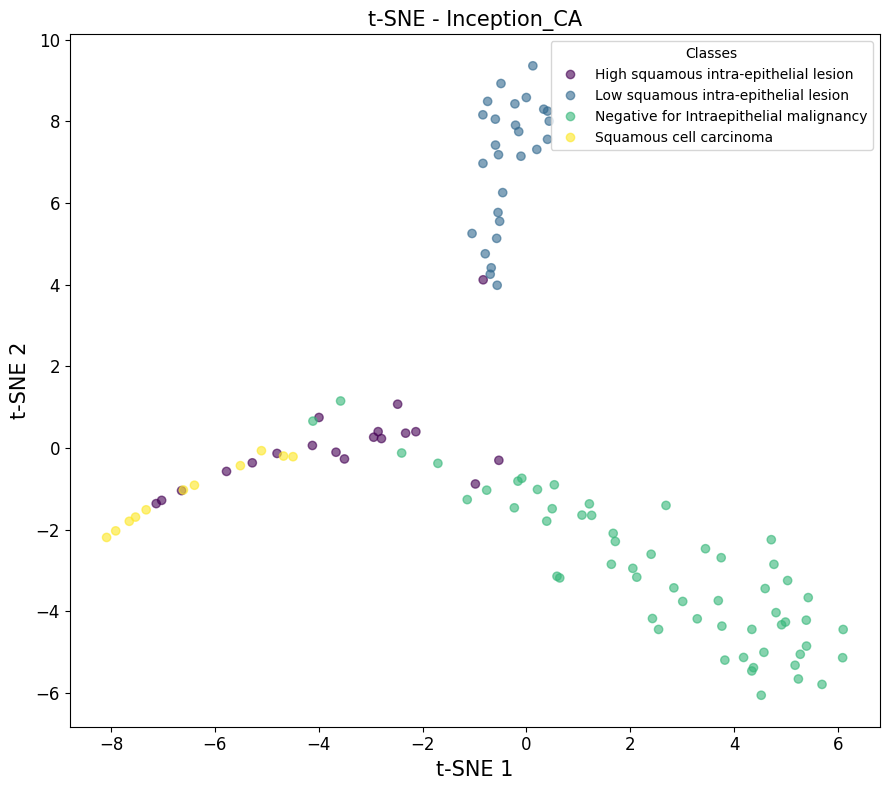

In [64]:
for backbone in versions:
    for variant in ["GAP", "CA"]:
        name = f"{backbone}_{variant}"
        emb = tsne_embeddings[name]
        fig, ax = plt.subplots(figsize=(9, 8))
        scatter = ax.scatter(emb[:, 0], emb[:, 1], c=y_test_classes, cmap='viridis', alpha=0.6)
        ax.set_title(f't-SNE - {name}', fontsize=15)
        ax.set_xlabel('t-SNE 1', fontsize=15)
        ax.set_ylabel('t-SNE 2', fontsize=15)
        ax.tick_params(labelsize=12)
        ax.legend(handles=scatter.legend_elements()[0], labels=class_names,
                  title="Classes", fontsize=10, title_fontsize=10)
        plt.tight_layout()
        plt.savefig(f'tsne_{name}.png', dpi=150)   
        plt.show()

## Paired McNemar’s test

In [65]:
from scipy.stats import binom

order = [("MobileNet", "MobileNet"), ("ResNet50", "ResNet50"), ("VGG16", "VGG16"),
         ("VGG19", "VGG19"), ("Xception", "Xception"),
         ("DenseNet", "DenseNet121"), ("Inception", "InceptionV3")]   # (key in notebook, label in table)

def mcnemar_exact(b, c):
    n, k = b + c, min(b, c)
    if n == 0:
        return 1.0, 1.0
    p_exact = min(1.0, 2 * binom.cdf(k, n, 0.5))
    p_mid = max(0.0, p_exact - binom.pmf(k, n, 0.5))
    return p_exact, p_mid

rows = []
n = len(y_test_classes)

for key, label in order:
    gap_ok = np.argmax(test_predictions[f"{key}_GAP"], axis=1) == y_test_classes
    ca_ok  = np.argmax(test_predictions[f"{key}_CA"],  axis=1) == y_test_classes

    both_correct = int(np.sum(gap_ok & ca_ok))
    b = int(np.sum(gap_ok & ~ca_ok))      # GAP correct, CA wrong
    c = int(np.sum(~gap_ok & ca_ok))      # GAP wrong,   CA correct
    both_wrong = int(np.sum(~gap_ok & ~ca_ok))
    assert both_correct + b + c + both_wrong == n

    p_exact, p_mid = mcnemar_exact(b, c)
    rows.append({
        "Backbone": label,
        "GAP Acc. (%)": 100 * gap_ok.mean(),
        "CA Acc. (%)": 100 * ca_ok.mean(),
        "Δ (pp)": 100 * (ca_ok.mean() - gap_ok.mean()),
        "Both correct": both_correct,
        "b": b, "c": c,
        "Both wrong": both_wrong,
        "McNemar p (exact)": p_exact,
        "Mid-p": p_mid,
    })

mcnemar_table = pd.DataFrame(rows).set_index("Backbone")

print(f"Paired McNemar's test, CA vs GAP per backbone (test partition, n = {n})")
print("b = GAP correct & CA wrong, c = GAP wrong & CA correct\n")
display(mcnemar_table.style.format({
    "GAP Acc. (%)": "{:.2f}", "CA Acc. (%)": "{:.2f}", "Δ (pp)": "{:+.2f}",
    "McNemar p (exact)": "{:.3f}", "Mid-p": "{:.3f}"}))

Paired McNemar's test, CA vs GAP per backbone (test partition, n = 114)
b = GAP correct & CA wrong, c = GAP wrong & CA correct



,GAP Acc. (%),CA Acc. (%),Δ (pp),Both correct,b,c,Both wrong,McNemar p (exact),Mid-p
Backbone,,,,,,,,,
MobileNet,68.42,79.82,+11.40,76,2,15,21,0.002,0.001
ResNet50,89.47,90.35,+0.88,102,0,1,11,1.000,0.500
VGG16,79.82,86.84,+7.02,90,1,9,14,0.021,0.012
VGG19,80.70,88.60,+7.89,92,0,9,13,0.004,0.002
Xception,88.60,89.47,+0.88,100,1,2,11,1.000,0.625
DenseNet121,77.19,85.96,+8.77,86,2,12,14,0.013,0.007
InceptionV3,75.44,79.82,+4.39,84,2,7,21,0.180,0.109


## Grad-Cam

In [66]:
def _last_call_tensor(layer, which):
    node = layer._inbound_nodes[-1]
    if which == "output":
        t = getattr(node, "output_tensors", None)
        if t is None:
            t = node.outputs
    else:
        t = node.input_tensors
    while isinstance(t, (list, tuple)) and len(t) == 1:
        t = t[0]
    return t


def build_gradcam_model(model):
    ca_layers = [l for l in model.layers if l.__class__.__name__ in ("ClusterAttentionBlock", "ASCFBlock")]
    if ca_layers:
        target = _last_call_tensor(ca_layers[-1], 'input')
    else:
        target = None
        for layer in reversed(model.layers):
            out = _last_call_tensor(layer, 'output')
            if not isinstance(out, (list, tuple)) and len(out.shape) == 4:
                target = out
                break
    if target is None:
        raise ValueError("No 4-D feature map found in the model")

    last = model.layers[-1]
    act_name = getattr(getattr(last, "activation", None), "__name__", "")
    if isinstance(last, tf.keras.layers.Dense) and act_name == "softmax":
        kind, head, aux = "dense", [np.asarray(w) for w in last.get_weights()], _last_call_tensor(last, 'input')
    elif isinstance(last, tf.keras.layers.Softmax) or (
            isinstance(last, tf.keras.layers.Activation) and act_name == "softmax"):
        kind, head, aux = "logits", None, _last_call_tensor(last, 'input')
    else:
        kind, head, aux = "log", None, model.output
    return Model(model.inputs, [target, aux]), kind, head


def gradcam_batch(model, images, targets=None):
    grad_model, kind, head = build_gradcam_model(model)
    x = tf.convert_to_tensor(np.asarray(images), dtype=tf.float32)
    with tf.GradientTape() as tape:
        feat, aux = grad_model(x, training=False)
        if kind == "dense":
            logits = tf.matmul(aux, head[0]) + (head[1] if len(head) > 1 else 0.0)
        elif kind == "logits":
            logits = aux
        else:
            logits = tf.math.log(aux + 1e-10)
        preds = tf.argmax(logits, axis=1).numpy()
        tgt = preds if targets is None else np.asarray(targets).astype(int)
        score = tf.reduce_sum(logits * tf.one_hot(tgt, logits.shape[-1]))
    grads = tape.gradient(score, feat)
    if grads is None:
        raise RuntimeError("No gradient reached the feature map")

    # sanity check: the reconstructed logits must reproduce the model's own predictions
    ref = np.argmax(model.predict(np.asarray(images), verbose=0), axis=1)
    assert np.array_equal(ref, preds), "Logit path does not match model.predict"

    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(feat * weights, axis=-1)).numpy()
    cam = cam / (cam.max(axis=(1, 2), keepdims=True) + 1e-8)
    return cam, preds, tgt


# ---------------------------------------------------------------------------------------------
# Test images (one per class, deterministic) and plotting / caching helpers
# ---------------------------------------------------------------------------------------------
gradcam_idx = np.array([np.where(y_test_classes == c)[0][0] for c in range(num_classes)])
X_gradcam = X_test[gradcam_idx]
print("Grad-CAM test indices:", gradcam_idx, "-> true classes:", [class_names[y_test_classes[i]] for i in gradcam_idx])

gradcam_cache = {}


def run_gradcam(name, targets=None):
    key = (name, None if targets is None else tuple(int(t) for t in targets))
    if key not in gradcam_cache:
        K.clear_session()
        model = load_cervical_model(name)
        cam, preds, tgt = gradcam_batch(model, X_gradcam, targets)
        print(f"  {name}: feature map {cam.shape[1]}x{cam.shape[2]} | predictions {[class_names[p][:4] for p in preds]}")
        gradcam_cache[key] = (cam, preds, tgt)
        del model
    return gradcam_cache[key]


def show_gradcam(title, heatmaps):
    n = len(gradcam_idx)
    fig, axes = plt.subplots(2, n, figsize=(4 * n, 6))
    fig.suptitle(title, fontsize=16)

    for i, idx in enumerate(gradcam_idx):
        img = X_test[idx]
        true_label = y_test_classes[idx]
        img_norm = (img - img.min()) / (img.max() - img.min() + 1e-8)
        img_norm = np.uint8(255 * img_norm)

        heatmap_resized = cv2.resize(heatmaps[i], (img.shape[1], img.shape[0]))
        heatmap_uint8 = np.uint8(255 * heatmap_resized)
        heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
        heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
        superimposed_img = cv2.addWeighted(img_norm, 0.6, heatmap_color, 0.4, 0)

        axes[0, i].imshow(img_norm)
        axes[0, i].set_title(f"{wrapped_class_names[true_label]}\n\nOriginal")   # class name, gap, "Original"
        axes[0, i].axis('off')

        axes[1, i].imshow(superimposed_img)
        axes[1, i].set_title("Grad-CAM")
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.savefig("gradcam_" + title.replace(" ", "_").replace("+", "plus").replace(":", "") + ".png", dpi=150)
    plt.show()

Grad-CAM test indices: [  0  19  46 103] -> true classes: ['High squamous intra-epithelial lesion', 'Low squamous intra-epithelial lesion', 'Negative for Intraepithelial malignancy', 'Squamous cell carcinoma']



Generating Grad-CAM for: VGG16_GAP


  VGG16_GAP: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


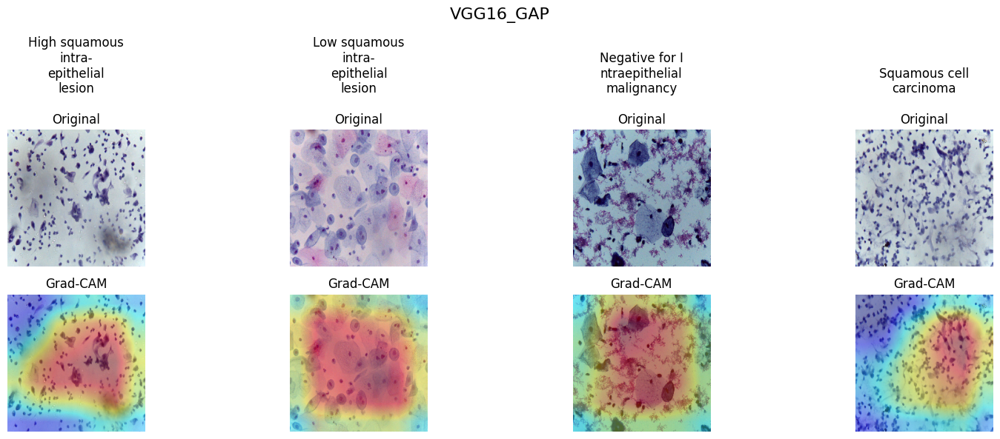


Generating Grad-CAM for: VGG16_CA


  VGG16_CA: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


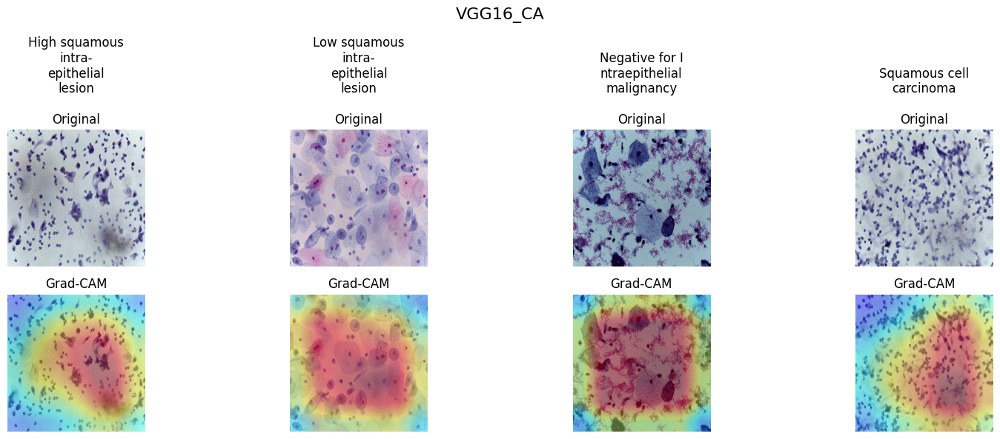


Generating Grad-CAM for: VGG19_GAP


  VGG19_GAP: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


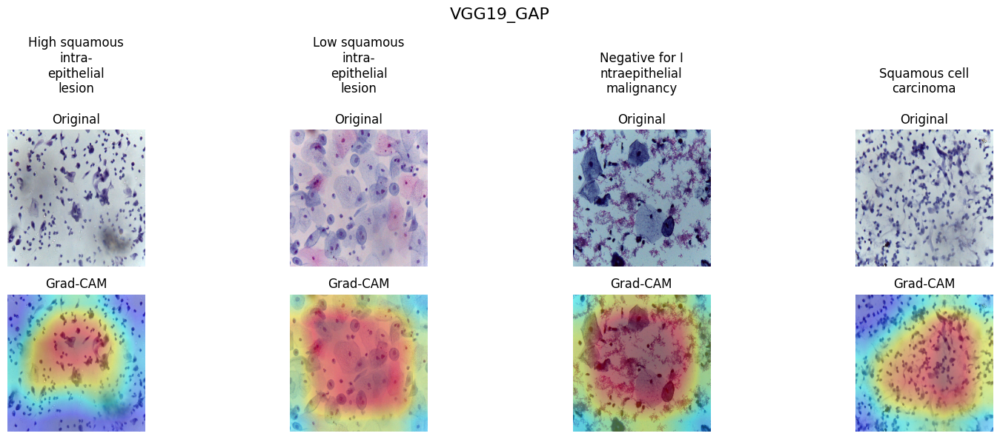


Generating Grad-CAM for: VGG19_CA


  VGG19_CA: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


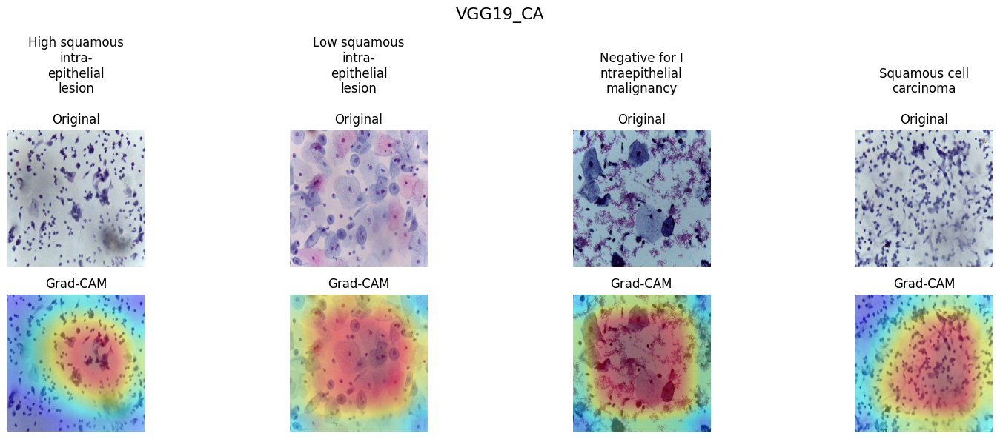


Generating Grad-CAM for: ResNet50_GAP


  ResNet50_GAP: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


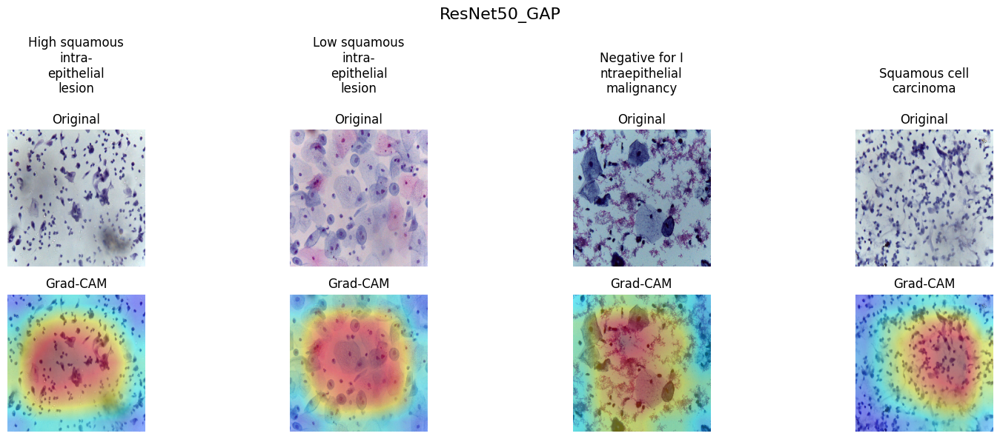


Generating Grad-CAM for: ResNet50_CA


  ResNet50_CA: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


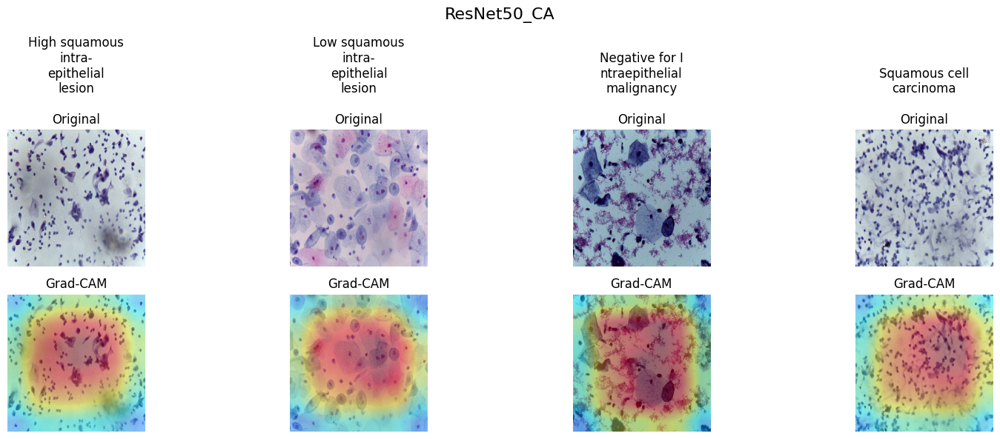


Generating Grad-CAM for: MobileNet_GAP


2026-11-14 08:57:46.174698: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 08:57:46.330129: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 08:57:46.467737: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  MobileNet_GAP: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


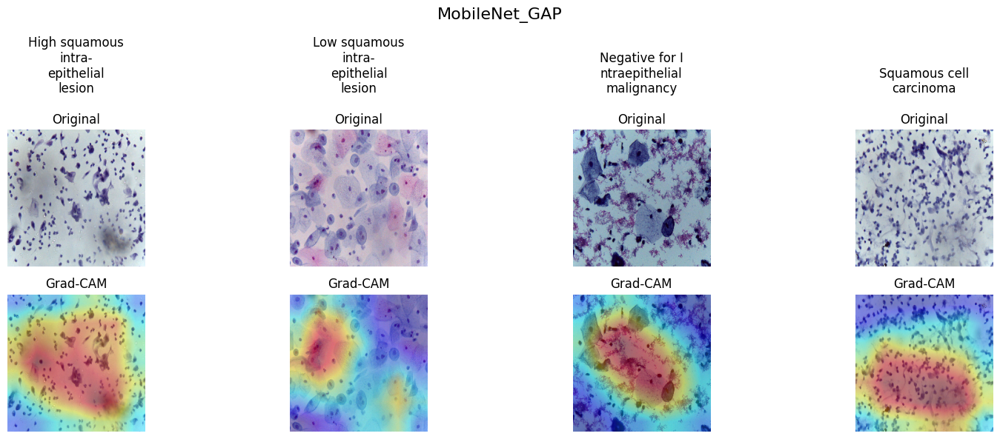


Generating Grad-CAM for: MobileNet_CA


  MobileNet_CA: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


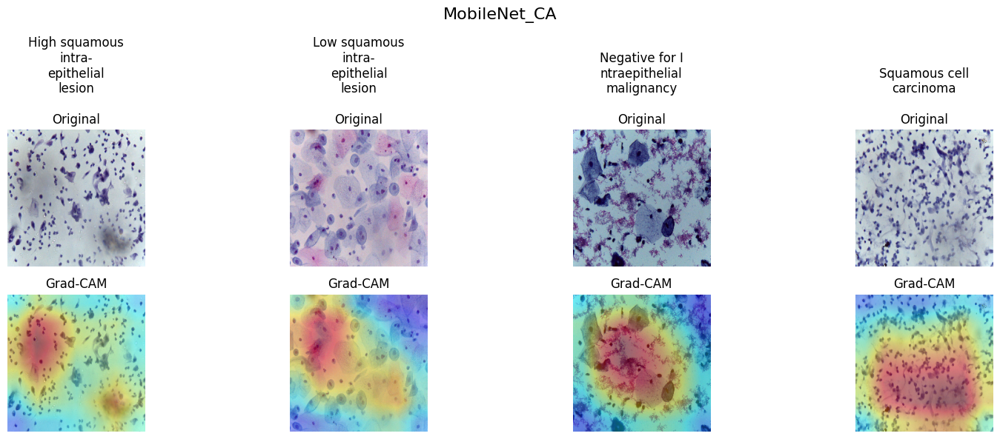


Generating Grad-CAM for: DenseNet_GAP


  DenseNet_GAP: feature map 7x7 | predictions ['High', 'Nega', 'Nega', 'High']


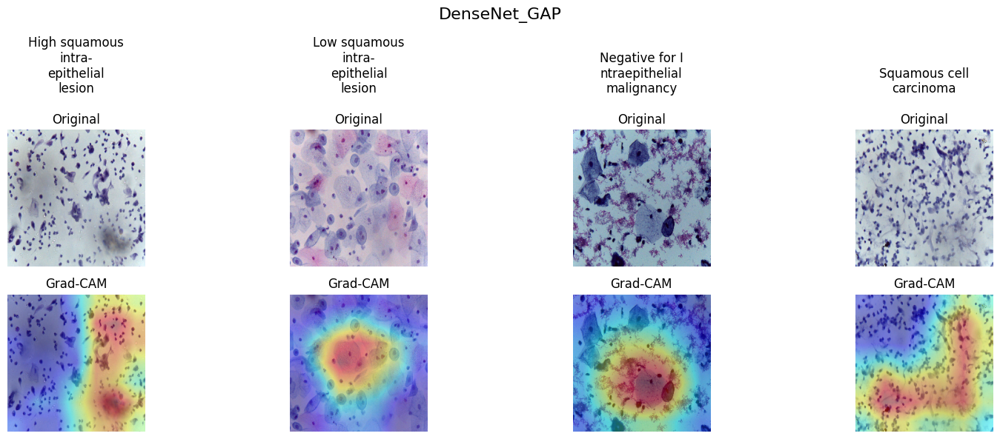


Generating Grad-CAM for: DenseNet_CA


  DenseNet_CA: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


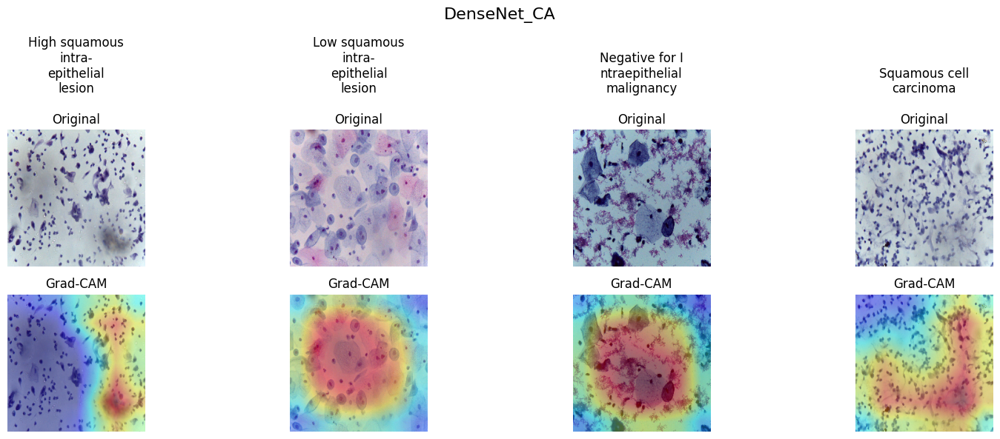


Generating Grad-CAM for: Xception_GAP


2026-11-14 08:58:44.530195: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 08:58:44.665923: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 08:58:45.401541: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 08:58:45.534712: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 08:58:46.308593: E external/local_xla/xla/stream_

  Xception_GAP: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


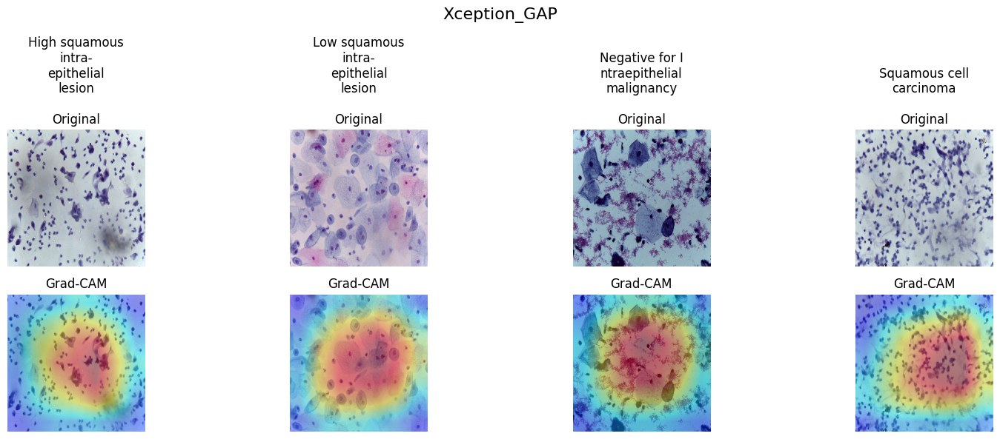


Generating Grad-CAM for: Xception_CA


  Xception_CA: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


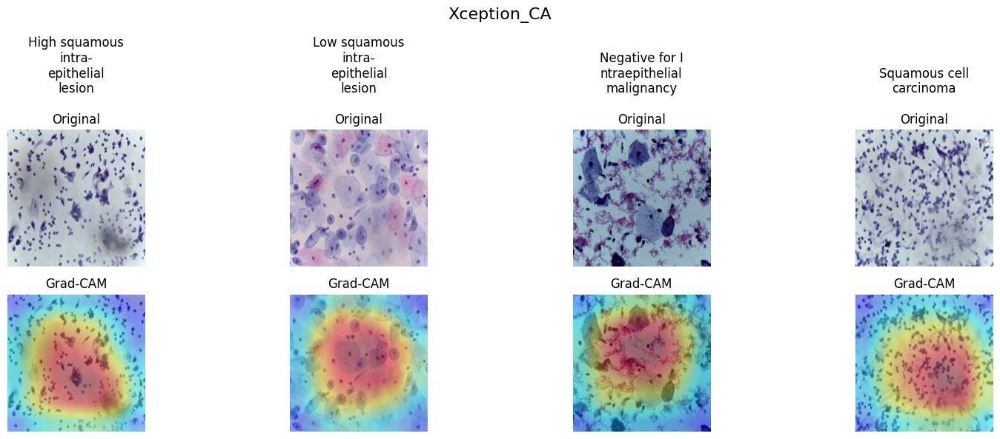


Generating Grad-CAM for: Inception_GAP


  Inception_GAP: feature map 5x5 | predictions ['Squa', 'Low ', 'Nega', 'High']


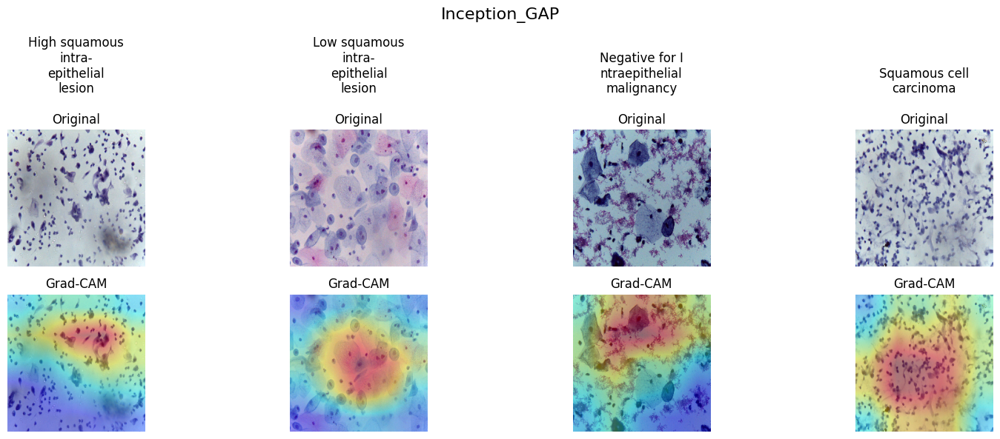


Generating Grad-CAM for: Inception_CA


  Inception_CA: feature map 5x5 | predictions ['High', 'Low ', 'Nega', 'High']


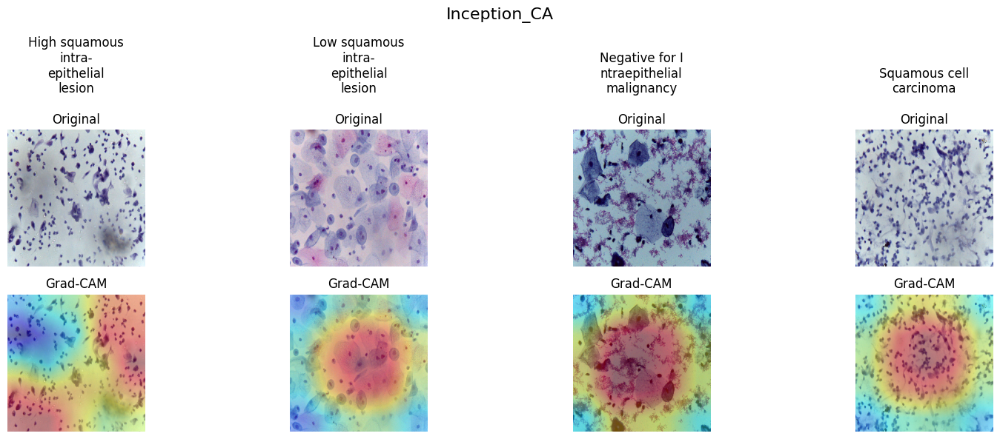

In [67]:
for backbone in versions:
    for variant in ["GAP", "CA"]:
        name = f"{backbone}_{variant}"
        print(f"\nGenerating Grad-CAM for: {name}")
        cam, preds, _ = run_gradcam(name)
        show_gradcam(name, cam)

stacked ensemble


Generating Grad-CAM for ensemble: VGG16_CA + Inception_CA
ensemble predictions: [0, 1, 2, 0] | true: [0, 1, 2, 3]
member weights per image: {'VGG16_CA': [0.89, 0.59, 0.57, 0.67], 'Inception_CA': [0.11, 0.41, 0.43, 0.33]}


  VGG16_CA: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


  Inception_CA: feature map 5x5 | predictions ['High', 'Low ', 'Nega', 'High']


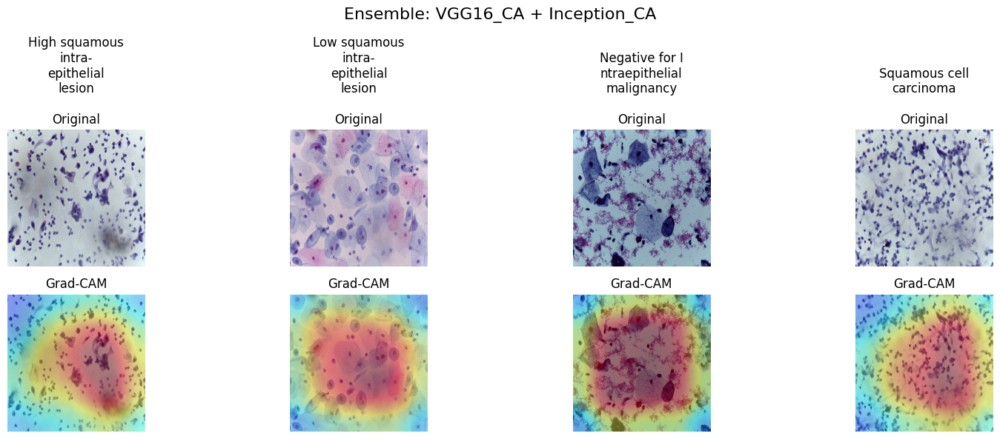


Generating Grad-CAM for ensemble: VGG16_CA + ResNet50_CA
ensemble predictions: [0, 1, 2, 0] | true: [0, 1, 2, 3]
member weights per image: {'VGG16_CA': [0.52, 0.62, 0.57, 0.52], 'ResNet50_CA': [0.48, 0.38, 0.43, 0.48]}


  ResNet50_CA: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


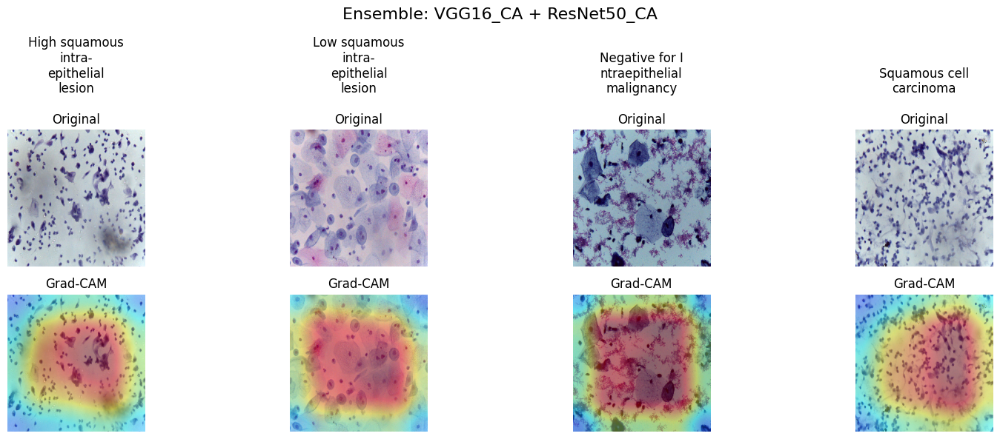


Generating Grad-CAM for ensemble: ResNet50_CA + Xception_CA
ensemble predictions: [0, 1, 2, 0] | true: [0, 1, 2, 3]
member weights per image: {'ResNet50_CA': [0.52, 0.38, 0.43, 0.5], 'Xception_CA': [0.48, 0.62, 0.57, 0.5]}


  Xception_CA: feature map 7x7 | predictions ['High', 'Low ', 'Nega', 'High']


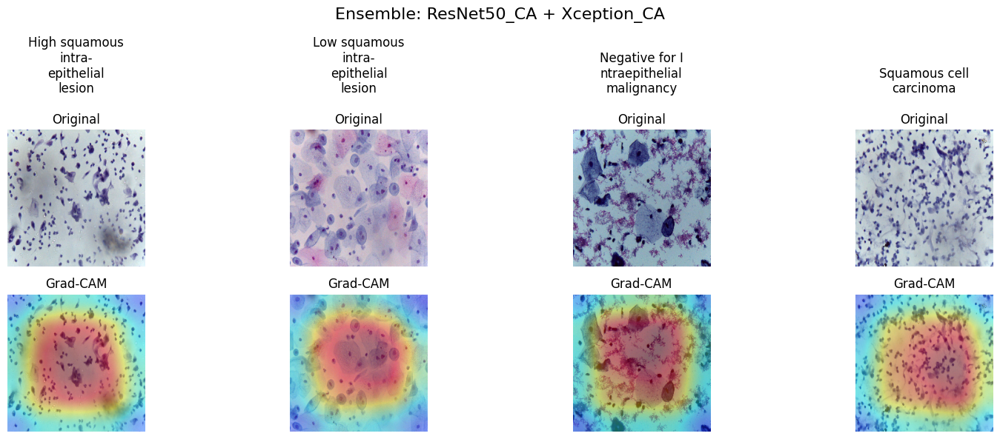

In [68]:
def gradcam_ensemble(members):
    n, K_ = len(gradcam_idx), num_classes
    lr = LogisticRegression(max_iter=2000, random_state=42)
    lr.fit(np.hstack([val_predictions[m] for m in members]), y_val_classes)
    assert np.array_equal(lr.classes_, np.arange(K_))
    member_probs = [test_predictions[m][gradcam_idx] for m in members]
    ens_pred = lr.predict(np.hstack(member_probs))

    contrib = np.array([[lr.coef_[ens_pred[i], j * K_:(j + 1) * K_] @ member_probs[j][i]
                         for j in range(len(members))] for i in range(n)])
    w = np.clip(contrib, 0, None)
    w[w.sum(1) == 0] = 1.0
    w = w / w.sum(1, keepdims=True)
    print("ensemble predictions:", ens_pred.tolist(), "| true:", y_test_classes[gradcam_idx].tolist())
    print("member weights per image:", {m: np.round(w[:, j], 2).tolist() for j, m in enumerate(members)})

    h, wd = X_test.shape[1:3]
    cams = [run_gradcam(m, targets=ens_pred)[0] for m in members]
    up = lambda m: cv2.resize(m.astype(np.float32), (wd, h), interpolation=cv2.INTER_CUBIC)
    fused = []
    for i in range(n):
        f = sum(w[i, j] * np.clip(up(cams[j][i]), 0, 1) for j in range(len(members)))
        fused.append(f / (f.max() + 1e-8))
    show_gradcam("Ensemble: " + " + ".join(members), fused)


ensemble_list = [["VGG16_CA", "Inception_CA"], ["VGG16_CA", "ResNet50_CA"]]
if "best_name" in globals() and best_name.split(" + ") not in ensemble_list:
    ensemble_list.append(best_name.split(" + "))        # the top-ranked ensemble from the search above

for members in ensemble_list:
    print("\nGenerating Grad-CAM for ensemble:", " + ".join(members))
    gradcam_ensemble(members)